
# Residual Super-Resolution with Layer-wise Energy/Reward Training

$
x^{(\ell+1)} = U_\ell(x^{(\ell)}) + A_\ell r_\ell,
$

where each layer generates a residual $r_\ell$, receives its own energy/reward signal, and can use either deterministic ODE/CNF-style probability accounting or SDE/Langevin/AIS-style path weighting.

The current executable benchmark is the 2D lattice $\phi^4$ model:

$
S(\phi)=\sum_x\left[
\frac12(\phi_x-\phi_{x+\hat x})^2+
\frac12(\phi_x-\phi_{x+\hat y})^2+
\frac12m^2\phi_x^2+
\frac{\lambda}{4}\phi_x^4
\right].
$

The design is intentionally modular. The blocks are:

1. partition / lifting rule;
2. variable to train: absolute new values vs residuals;
3. layer energy / reward;
4. per-layer refiner: ODE/CNF, EWFM, RFM, EDM/Langevin/SDE;
5. probability or work accounting;
6. diagnostics: final ESS, observables, memory/time.








## Conceptual Architecture: Algorithm, Geometry, Network, Conditioning

A useful way to read this notebook is to separate four independent design layers.

```text
sampler / transportation paradigm
    chooses the mathematical training objective and probability accounting

partition geometry
    chooses which lattice sites are generated at each layer

transportation / embedding backbones
    parameterizes the functions used by the sampler

conditioning mechanism
    chooses what information from the parent coarse sample is given to the residual model
```

These are not the same thing.

The sampler paradigm is the high-level algorithm:

```text
RKL-CNF  -> ODE velocity field with log-density/divergence accounting
EWFM     -> ODE velocity field trained by weighted flow matching
RFM      -> ODE velocity field trained by reverse posterior inference
iDEM     -> score field trained by denoising/energy-weighted score estimates
NETS-AM  -> scalar control potential trained by action matching
```

The partition geometry defines the layer variables:

```text
current default: full Kadanoff L -> 2L
residual shape: [B, 3, L, L]
future option: checkerboard / half-step partition
```

The transportation backbone is the function approximator inside the sampler paradigm. It parameterizes the actual transport/control object:

```text
v_theta(r_t, t; condition)      velocity for CNF/EWFM/RFM
s_theta(r_t, t; condition)      score for iDEM
psi_theta(r_t, t; condition)    scalar control potential for NETS-AM
E_phi(coarse)                   optional context encoder, controlled by embedding_type
```

Those transport functions do not have to be MLPs. They can be selected with transportation_backbone, currently "mlp" or "cnn". The single embedding_type setting controls conditioning: "unconditional" passes no coarse information, None passes raw coarse sites only, and "mlp", "cnn", "fourier", or "fourier_cnn" add a learned context to the raw field.

The conditioning mechanism determines how the residual model reads the already-generated parent sample. The baseline uses the raw coarse field directly. The optional context embedding adds a deterministic learned summary:

```text
h_l = E_l(x_l)
r_l ~ q_theta(r_l | x_l, h_l)
x_{l+1} = U_l(x_l) + A_l r_l
```

The context value `h_l` is sample-specific, but the encoder `E_l` and residual model are layer-specific trainable modules shared across samples. Since `h_l` is deterministic given `x_l`, it introduces no extra density term. During greedy layerwise training, previous layers are fixed and detached; gradients update only the current layer's encoder and residual sampler.

So the implementation should be read as a composition:

```text
chosen paradigm + chosen partition + chosen transportation backbone + chosen embedding backbone + chosen conditioning
```

The current default is:

```text
RKL-CNF / EWFM / iDEM / NETS / RFM
+ full Kadanoff partition
+ flattened MLP transportation backbone
+ raw coarse conditioning, optionally raw+context with selectable embedding backbone
```


## 1. Imports and configuration

In [1]:
import math
import time
from pathlib import Path
from dataclasses import dataclass, field, replace
from typing import Dict, Tuple, Optional, Callable, List, Any, Union

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

torch.set_default_dtype(torch.float32)

def get_device():
    return torch.device("cuda" if torch.cuda.is_available() else "cpu")


In [2]:
import os
import importlib
os.chdir('/scratch/kzhang9/KUL')

# Prefer the packaged utility. A stale top-level file in /scratch/kzhang9/KUL
# must not shadow the implementation shipped with this notebook.
try:
    from lattice_scaling_final.training_modules import training_best_state as _training_best_state
except ModuleNotFoundError:
    from training_modules import training_best_state as _training_best_state

# Re-executing this cell reloads edited utility code instead of retaining an
# older module object in the Jupyter kernel.
_training_best_state = importlib.reload(_training_best_state)
BestStateTracker = _training_best_state.BestStateTracker
finite_record = _training_best_state.finite_record
rkl_density_record_is_stable = _training_best_state.rkl_density_record_is_stable
safe_optimizer_step = _training_best_state.safe_optimizer_step

In [3]:
@dataclass
class Phi4Config:
    """
    Default params: \n
    ------- Common to all ------- \n
    m2: float = -0.4658 \n
    lam: float = 0.3007 \n
    L0: int = 4 \n
    n_lift_layers: int = 1 \n
    coarse_sigma: float = 0.7 \n
    residual_sigma: float = 0.7 \n
    init_type: str = "gaussian" # Choose from "gaussian" and "free_theory" \n
    init_free_m2: float = 1.0 \n
    batch_size: int = 64 \n
    lr: float = 2e-4 \n
    n_train_steps: int = 500 \n
    grad_clip: float = 1.0 \n
    hidden_dim: int = 128 \n
    transportation_backbone: str = "mlp" # "mlp" or "cnn" \n
    embedding_type: Optional[str] = None # "unconditional", None, "mlp", "cnn", "fourier", or "fourier_cnn" \n
    inherit_previous_lift_cnn_weights: bool = False # lifting only; warm-start a compatible CNN from the preceding lift \n
    base_train_overrides: Dict[str, Any] = field(default_factory=dict) \n
    layer_train_overrides: Dict[int, Dict[str, Any]] = field(default_factory=dict) \n
    device \n
    ------- Common to ODE Methods (RKL-CNF, EWFM, RFM) ------- \n
    cnf_steps: int = 8 \n
    cnf_divergence_mode: str = "exact"  # "exact" or "hutchinson", exact mode ≈ hutchinson_samples = dimension, here in lattice sampling, dimension=L*L \n
    hutchinson_samples: int = 1 # number of random trace probes per cnf step \n
    ------- Common to SDE Methods (iDEM, NETS) ------- \n
    sde_steps: int = 32 \n
    sde_step_size: Optional[float] = None \n
        Use only one of these: \n
            sde_steps = 32 \n
            sde_step_size = None \n
        or: \n
            sde_step_size = 0.01 \n
    ------- Specific to iEWFM ------- \n
    ewfm_max_weight: float = 20.0 \n
    ewfm_outer_loops: int = 8 # ewfm_outer_loops = 1 will make iEWFM just plain EWFM \n
    ewfm_buffer_size: int = 4096 \n
    ------- Specific to RFM ------- \n
    rfm_mc_samples: int = 8 \n
    rfm_t_min: float = 0.02 \n
    rfm_use_stein: bool = True \n
    rfm_stein_ridge: float = 1e-4 \n
    ------- Specific to iDEM ------- \n
    idem_outer_loops: int = 8 \n
    idem_buffer_size: int = 4096 \n
    idem_exploration_noise: float = 1.0 \n
    ------- Specific to NETS ------- \n
    nets_eps: float = 1.0
    """

    # Singha-style critical-ish convention:
    # S = sum_x [0.5 * nearest-neighbor differences + 0.5*m2*phi^2 + lam/4*phi^4]
    m2: float = -0.4658
    lam: float = 0.3007

    # L0 is the base resolution; n_lift_layers controls how many L -> 2L lifts are trained.
    L0: int = 4
    n_lift_layers: int = 1
    partition_mode: str = "full_kadanoff"

    # Optional deterministic context embedding for residual layers.
    # Single user-facing control: "unconditional" passes no coarse information,
    # None uses raw coarse sites only, and "mlp", "cnn", "fourier", or
    # "fourier_cnn" use raw coarse sites plus the selected learned context.
    embedding_type: Optional[str] = None
    transportation_backbone: str = "mlp"  # "mlp" or "cnn"; used consistently for base and residual transport models.
    cnn_channels: int = 64
    cnn_layers: int = 4
    cnn_kernel_size: int = 3
    # Lifting-only warm start. It never copies base or relaxation weights and
    # does not change the Gaussian/free-theory residual initialization.
    inherit_previous_lift_cnn_weights: bool = False
    # Legacy fields retained only so old checkpoints can be upgraded on load.
    use_context_embedding: bool = False
    embedding_backbone: str = "mlp"
    context_dim: int = 64
    context_hidden_dim: int = 128
    embedding_cnn_channels: int = 32
    embedding_cnn_layers: int = 3
    fourier_context_modes: int = 4
    condition_mode: str = "raw_plus_context"

    # Optional RG-guided full-lattice CNF trained after a residual lift.
    # It is disabled by default so all existing checkpoints remain unchanged.
    rg_relaxation_enabled: bool = False
    rg_relaxation_train_steps: int = 1000
    # batch_size is the global physical microbatch. Multi-GPU mode splits it
    # across all CUDA devices visible through CUDA_VISIBLE_DEVICES.
    rg_relaxation_multi_gpu: bool = False
    # This multiplies the global effective batch without increasing per-pass memory.
    rg_relaxation_gradient_accumulation_steps: int = 1
    rg_relaxation_cnf_steps: int = 8
    rg_relaxation_channels: int = 32
    rg_relaxation_layers: int = 4
    rg_relaxation_kernel_size: int = 3
    rg_relaxation_uv_scale: float = 1.0
    rg_relaxation_ir_scale: float = 0.1
    rg_relaxation_trust_weight: float = 0.0
    rg_relaxation_trust_anneal_fraction: float = 0.5

    # residual base distribution
    residual_sigma: float = 0.7
    coarse_sigma: float = 0.7

    device: str = str(get_device())

    # Initialization law used at the base scale and for every new residual layer.
    # "gaussian" is iid site noise; "free_theory" is the quadratic lattice field with lambda=0.
        # RKL-CNF / EWFM / RFM / NETS:cfg.init_type defines source/base initialization
        # iDEM:cfg.init_type defines optional clean-side replay-buffer warm start terminal prior is always Gaussian

    init_type: str = "gaussian"
    init_free_m2: float = 1.0

    # training
    batch_size: int = 64
    lr: float = 2e-4
    n_train_steps: int = 500
    grad_clip: float = 1.0

    # Resource policy. Abundant mode trades GPU memory for throughput by
    # caching frozen parent samples on GPU and enabling a fused optimizer.
    # Conservative mode streams fresh parents and avoids persistent GPU pools.
    gpu_resources_abundant: bool = False
    gpu_parent_pool_size: int = 32768
    gpu_parent_generation_batch_size: int = 256

    # Optional stage-specific training overrides. Keys in layer_train_overrides are
    # the coarse lattice size L for the layer L -> 2L, e.g. {16: {"n_train_steps": 3000}}.
    # Keep architecture/rollout-defining settings such as hidden_dim, cnf_steps, and sde_steps global
    # unless the validation code is also updated to use per-stage integration settings.
    base_train_overrides: Dict[str, Any] = field(default_factory=dict)
    layer_train_overrides: Dict[int, Dict[str, Any]] = field(default_factory=dict)

    # CNF / ODE Euler settings
    cnf_steps: int = 8
    hidden_dim: int = 128
    cnf_divergence_mode: str = "exact"  # "exact" or "hutchinson"
    hutchinson_samples: int = 1

    # EWFM uses model-generated endpoints z -> x1/r1. The denominator in
    # the importance weight is q_theta(endpoint), computed by ODE log-density.
    ewfm_max_weight: float = 20.0
    ewfm_outer_loops: int = 8
    ewfm_buffer_size: int = 4096

    # RFM posterior inference. Candidates are normalized separately for each
    # intermediate state, so the reported ESS is a local conditional diagnostic.
    rfm_mc_samples: int = 8
    rfm_t_min: float = 0.02
    rfm_use_stein: bool = True
    rfm_stein_ridge: float = 1e-4

    # iDEM outer/inner training settings
    idem_outer_loops: int = 8
    idem_buffer_size: int = 4096
    idem_exploration_noise: float = 1.0

    # NETS controlled-Langevin diffusion strength.
    nets_eps: float = 1.0

    # Common SDE
    sde_steps: int = 32
    sde_step_size: Optional[float] = None  # Optional dt override; if None, use sde_steps.

def configure_gpu_resource_policy(cfg: Phi4Config) -> None:
    """Configure safe global CUDA runtime choices for the selected resource policy."""
    abundant = bool(cfg.gpu_resources_abundant) and torch.cuda.is_available()
    if abundant:
        torch.set_float32_matmul_precision("high")
        torch.backends.cuda.matmul.allow_tf32 = True
        torch.backends.cudnn.allow_tf32 = True
        torch.backends.cudnn.benchmark = True
    else:
        torch.backends.cudnn.benchmark = False
    print({"gpu_resource_policy": "abundant" if abundant else "oom_conservative"})

def make_adamw(module: nn.Module, cfg: Phi4Config) -> torch.optim.Optimizer:
    """Use fused AdamW only in abundant CUDA mode; fall back safely otherwise."""
    use_fused = bool(cfg.gpu_resources_abundant) and torch.cuda.is_available()
    if use_fused:
        try:
            return torch.optim.AdamW(module.parameters(), lr=cfg.lr, fused=True)
        except (TypeError, RuntimeError):
            pass
    return torch.optim.AdamW(module.parameters(), lr=cfg.lr)

# Canonical shared definitions live in training_modules. Keeping this import at
# the end of the cell also makes older notebook copies migrate safely.
try:
    from lattice_scaling_final.training_modules.config import Phi4Config, configure_gpu_resource_policy, get_device, make_adamw
except ModuleNotFoundError:
    from training_modules.config import Phi4Config, configure_gpu_resource_policy, get_device, make_adamw

cfg = Phi4Config()
device = torch.device(cfg.device)
print("device:", device)

device: cuda


In [4]:
print(torch.cuda.memory_allocated() / 1e9)  # GB currently allocated by tensors)
print(torch.cuda.memory_reserved() / 1e9)  # GB reserved by the caching allocator
print(torch.cuda.get_device_properties(0).total_memory / 1e9)  # total on the GPU

0.0
0.0
85.093777408



## 2. The $\phi^4$ action

This is the final target action at any completed lattice resolution.

In [5]:
def phi4_action(phi: torch.Tensor, cfg: Phi4Config) -> torch.Tensor:
    """
    Square-lattice phi^4 action with periodic boundary conditions.

    Args:
        phi: tensor with shape [B, 1, L, L] or [B, L, L]
    Returns:
        action per batch element, shape [B]
    """
    if phi.ndim == 3:
        phi = phi[:, None, :, :]
    dx = phi - torch.roll(phi, shifts=-1, dims=-2)
    dy = phi - torch.roll(phi, shifts=-1, dims=-1)
    kinetic = 0.5 * (dx.square() + dy.square())
    potential = 0.5 * cfg.m2 * phi.square() + (cfg.lam / 4.0) * phi.pow(4)
    return (kinetic + potential).sum(dim=(-1, -2, -3))

def log_gaussian_field(x: torch.Tensor, sigma: float) -> torch.Tensor:
    """
    Log density of independent N(0, sigma^2) entries, per batch element.
    """
    D = x[0].numel()
    return -0.5 * (x.square() / sigma**2).flatten(1).sum(dim=1) - D * math.log(sigma * math.sqrt(2 * math.pi))

def free_theory_energy(x: torch.Tensor, m2: float) -> torch.Tensor:
    """Quadratic lambda=0 lattice energy, channel-wise with periodic boundaries."""
    if x.ndim == 3:
        x = x[:, None, :, :]
    dx = x - torch.roll(x, shifts=-1, dims=-2)
    dy = x - torch.roll(x, shifts=-1, dims=-1)
    return (0.5 * (dx.square() + dy.square()) + 0.5 * m2 * x.square()).sum(dim=(-1, -2, -3))

def log_free_theory_field(x: torch.Tensor, m2: float) -> torch.Tensor:
    """Normalized log density of the periodic Gaussian free field.

    For S0(x) = 0.5 * x^T A x,
        log q0(x) = -S0(x) + 0.5 log det(A) - D/2 log(2*pi).
    The eigenvalues of A are evaluated exactly in the Fourier basis.
    """
    if m2 <= 0:
        raise ValueError("Normalized free-theory density requires m2 > 0.")
    if x.ndim == 3:
        x = x[:, None, :, :]
    if x.ndim != 4 or x.shape[-2] != x.shape[-1]:
        raise ValueError("Expected free-theory fields with shape [B, C, L, L].")
    channels, L = x.shape[1], x.shape[-1]
    k = 2.0 * math.pi * torch.fft.fftfreq(L, device=x.device, dtype=x.dtype)
    eigenvalues = m2 + 4.0 - 2.0 * torch.cos(k)[:, None] - 2.0 * torch.cos(k)[None, :]
    log_det = channels * torch.log(eigenvalues).sum()
    D = x[0].numel()
    log_normalizer = 0.5 * log_det - 0.5 * D * math.log(2.0 * math.pi)
    return -free_theory_energy(x, m2) + log_normalizer

def sample_free_theory_field(batch_size: int, channels: int, L: int, m2: float, device, dtype=torch.float32) -> torch.Tensor:
    """Direct Gaussian free-field sample using the Fourier diagonal quadratic operator."""
    if m2 <= 0:
        raise ValueError("free_theory initialization requires init_free_m2 > 0.")
    white = torch.randn(batch_size, channels, L, L, device=device, dtype=dtype)
    k = 2.0 * math.pi * torch.fft.fftfreq(L, device=device, dtype=dtype)
    lam = m2 + 4.0 - 2.0 * torch.cos(k)[:, None] - 2.0 * torch.cos(k)[None, :]
    white_k = torch.fft.fft2(white, norm="ortho")
    field = torch.fft.ifft2(white_k / torch.sqrt(lam)[None, None, :, :], norm="ortho").real
    return field

def _init_sigma_for_role(cfg: Phi4Config, role: str) -> float:
    """Gaussian initialization scale for base fields versus residual/new-site variables."""
    if role == "base":
        return cfg.coarse_sigma
    if role == "residual":
        return cfg.residual_sigma
    raise ValueError(f"Unknown initialization role: {role}")

def sample_initial_field(cfg: Phi4Config, batch_size: int, channels: int, L: int, device=None, dtype=torch.float32, role: str = "residual") -> torch.Tensor:
    """Sample the configured initialization law for base fields or residual variables."""
    device = torch.device(cfg.device) if device is None else device
    init_type = getattr(cfg, "init_type", "gaussian")
    if init_type == "gaussian":
        return _init_sigma_for_role(cfg, role) * torch.randn(batch_size, channels, L, L, device=device, dtype=dtype)
    if init_type == "free_theory":
        return sample_free_theory_field(batch_size, channels, L, cfg.init_free_m2, device=device, dtype=dtype)
    raise ValueError(f"Unknown init_type: {init_type}")

def initial_base_energy(x: torch.Tensor, cfg: Phi4Config, role: str = "residual") -> torch.Tensor:
    """Unnormalized base energy U0 for the configured initialization law."""
    init_type = getattr(cfg, "init_type", "gaussian")
    if init_type == "gaussian":
        sigma = _init_sigma_for_role(cfg, role)
        return 0.5 * (x.square() / sigma**2).flatten(1).sum(dim=1)
    if init_type == "free_theory":
        return free_theory_energy(x, cfg.init_free_m2)
    raise ValueError(f"Unknown init_type: {init_type}")

def initial_log_prob(x: torch.Tensor, cfg: Phi4Config, role: str = "residual") -> torch.Tensor:
    """Fully normalized base log density, including all additive constants."""
    init_type = getattr(cfg, "init_type", "gaussian")
    if init_type == "gaussian":
        return log_gaussian_field(x, _init_sigma_for_role(cfg, role))
    if init_type == "free_theory":
        return log_free_theory_field(x, cfg.init_free_m2)
    raise ValueError(f"Unknown init_type: {init_type}")

def resolve_sde_grid(cfg: Phi4Config, n_steps: Optional[int] = None) -> Tuple[int, float]:
    """Return an SDE grid over [0, 1]. Explicit n_steps wins; otherwise sde_step_size can set dt."""
    if n_steps is not None:
        steps = int(n_steps)
    else:
        step_size = getattr(cfg, "sde_step_size", None)
        if step_size is None:
            steps = int(cfg.sde_steps)
        else:
            if step_size <= 0:
                raise ValueError("sde_step_size must be positive when set.")
            steps = int(math.ceil(1.0 / float(step_size)))
    steps = max(1, steps)
    return steps, 1.0 / steps

# Use the package implementation below; the definitions above are retained in
# the notebook only as a readable migration bridge for existing experiment logs.
try:
    from lattice_scaling_final.training_modules.physics import free_theory_energy, initial_base_energy, initial_log_prob, log_free_theory_field, log_gaussian_field, phi4_action, resolve_sde_grid, sample_free_theory_field, sample_initial_field
except ModuleNotFoundError:
    from training_modules.physics import free_theory_energy, initial_base_energy, initial_log_prob, log_free_theory_field, log_gaussian_field, phi4_action, resolve_sde_grid, sample_free_theory_field, sample_initial_field

## 3. Partition block: Kadanoff-style $L \rightarrow 2L$ lifting

We use one clean implementation first:

$
\phi^{2L} = U(\phi^L) + M_{\rm new} r.
$

The deterministic lift $U$ copies coarse values to even-even sites and fills new sites by interpolation. The residual $r$ is represented as three $L\times L$ maps:

$
r = (r_{\rm body}, r_{\rm row}, r_{\rm col}) \in \mathbb{R}^{3\times L\times L}.
$

- body: $(2i+1, 2j+1)$
- row-edge: $(2i+1, 2j)$
- column-edge: $(2i, 2j+1)$

Later we can swap this partition block for continuous patches, wavelets, Fourier bands, or a physical basis

In [6]:
class FullKadanoffPartition:
    """Current full Kadanoff L -> 2L partition with 3L^2 new-site variables."""
    name = "full_kadanoff"
    validates_scale = True

    def fine_L(self, L: int) -> int:
        return 2 * int(L)

    def residual_channels(self, L: int) -> int:
        return 3

    def residual_shape(self, L: int) -> Tuple[int, int, int]:
        return (self.residual_channels(L), int(L), int(L))

    def n_new_sites(self, L: int) -> int:
        return 3 * int(L) * int(L)

    def lift(self, coarse: torch.Tensor) -> torch.Tensor:
        return kadanoff_lift(coarse)

    def insert(self, coarse: torch.Tensor, residual: torch.Tensor, mode: str = "residual") -> torch.Tensor:
        return insert_residual(coarse, residual, mode=mode)

    def extract(self, fine: torch.Tensor, coarse: torch.Tensor, mode: str = "residual") -> torch.Tensor:
        if mode == "residual":
            return extract_residual(fine, coarse)
        if mode == "absolute":
            B, _, L2, _ = fine.shape
            L = L2 // 2
            r = torch.zeros(B, 3, L, L, device=fine.device, dtype=fine.dtype)
            r[:, 0] = fine[:, 0, 1::2, 1::2]
            r[:, 1] = fine[:, 0, 1::2, 0::2]
            r[:, 2] = fine[:, 0, 0::2, 1::2]
            return r
        raise ValueError(f"Unknown mode: {mode}")

    def new_site_mask(self, L: int, device=None) -> torch.Tensor:
        return new_site_mask(L, device=device)

    def layer_energy(self, fine: torch.Tensor, L_coarse: int, cfg: Phi4Config) -> torch.Tensor:
        return layer_energy_new_terms(fine, L_coarse, cfg)

    def coarsen_completed_lattice(self, fine: torch.Tensor) -> torch.Tensor:
        return fine[:, :, 0::2, 0::2]

FULL_KADANOFF_PARTITION = FullKadanoffPartition()

def get_partition(cfg: Optional[Phi4Config] = None):
    """Return the active partition object. Currently only full_kadanoff is implemented."""
    name = getattr(cfg, "partition_mode", "full_kadanoff") if cfg is not None else "full_kadanoff"
    if name == "full_kadanoff":
        return FULL_KADANOFF_PARTITION
    raise ValueError(f"Unknown partition_mode: {name}")

def kadanoff_lift(coarse: torch.Tensor) -> torch.Tensor:
    """
    Deterministically lift [B, 1, L, L] -> [B, 1, 2L, 2L].
    Periodic interpolation is used.
    """
    if coarse.ndim == 3:
        coarse = coarse[:, None, :, :]
    B, C, L, _ = coarse.shape
    assert C == 1

    fine = torch.zeros(B, 1, 2 * L, 2 * L, device=coarse.device, dtype=coarse.dtype)

    c = coarse
    c_down = torch.roll(c, shifts=-1, dims=-2)
    c_right = torch.roll(c, shifts=-1, dims=-1)
    c_diag = torch.roll(c_down, shifts=-1, dims=-1)

    # inherited even-even sites
    fine[:, :, 0::2, 0::2] = c

    # row-edge: between vertical neighbors
    fine[:, :, 1::2, 0::2] = 0.5 * (c + c_down)

    # column-edge: between horizontal neighbors
    fine[:, :, 0::2, 1::2] = 0.5 * (c + c_right)

    # body center
    fine[:, :, 1::2, 1::2] = 0.25 * (c + c_down + c_right + c_diag)

    return fine

def insert_residual(coarse: torch.Tensor, residual: torch.Tensor, mode: str = "residual") -> torch.Tensor:
    """
    Assemble fine field from coarse field and residual/new-value tensor.

    Args:
        coarse: [B, 1, L, L]
        residual: [B, 3, L, L]
        mode:
            "residual": fine_new = lift_new + residual
            "absolute": fine_new = residual  (new sites are generated directly)
    """
    if coarse.ndim == 3:
        coarse = coarse[:, None, :, :]
    B, _, L, _ = coarse.shape
    assert residual.shape == (B, 3, L, L)

    fine = kadanoff_lift(coarse)

    if mode == "residual":
        fine[:, 0, 1::2, 1::2] = fine[:, 0, 1::2, 1::2] + residual[:, 0]  # body
        fine[:, 0, 1::2, 0::2] = fine[:, 0, 1::2, 0::2] + residual[:, 1]  # row-edge
        fine[:, 0, 0::2, 1::2] = fine[:, 0, 0::2, 1::2] + residual[:, 2]  # col-edge
    elif mode == "absolute":
        fine[:, 0, 1::2, 1::2] = residual[:, 0]
        fine[:, 0, 1::2, 0::2] = residual[:, 1]
        fine[:, 0, 0::2, 1::2] = residual[:, 2]
    else:
        raise ValueError(f"Unknown mode: {mode}")

    return fine

def extract_residual(fine: torch.Tensor, coarse: torch.Tensor) -> torch.Tensor:
    """
    Extract residual maps from a completed fine lattice and its coarse ancestor.
    """
    lift = kadanoff_lift(coarse)
    B, _, L2, _ = fine.shape
    L = L2 // 2
    r = torch.zeros(B, 3, L, L, device=fine.device, dtype=fine.dtype)
    r[:, 0] = fine[:, 0, 1::2, 1::2] - lift[:, 0, 1::2, 1::2]
    r[:, 1] = fine[:, 0, 1::2, 0::2] - lift[:, 0, 1::2, 0::2]
    r[:, 2] = fine[:, 0, 0::2, 1::2] - lift[:, 0, 0::2, 1::2]
    return r

def new_site_mask(L: int, device=None) -> torch.Tensor:
    """
    Boolean mask for new sites on a 2L x 2L lattice.
    """
    mask = torch.ones(2 * L, 2 * L, dtype=torch.bool, device=device)
    mask[0::2, 0::2] = False
    return mask

@torch.no_grad()
def run_kadanoff_insert_extract_check(
    Ls: Tuple[int, ...] = (4, 8),
    batch_size: int = 32,
    mode: str = "residual",
    cfg: Optional[Phi4Config] = None,
    device: Optional[Union[str, torch.device]] = None,
    dtype: torch.dtype = torch.float32,
    seed: Optional[int] = 0,
    verbose: bool = True,
) -> List[Dict[str, Any]]:
    """Sanity check for Chapter 4.2-A: insert residual/new-site variables and extract them back."""
    device = torch.device("cpu") if device is None else torch.device(device)
    if seed is not None:
        torch.manual_seed(int(seed))

    partition = get_partition(cfg)
    rows: List[Dict[str, Any]] = []
    for L in Ls:
        L = int(L)
        coarse = torch.randn(batch_size, 1, L, L, device=device, dtype=dtype)
        residual_shape = partition.residual_shape(L)
        residual = torch.randn(batch_size, *residual_shape, device=device, dtype=dtype)
        fine = partition.insert(coarse, residual, mode=mode)
        recovered = partition.extract(fine, coarse, mode=mode)

        diff = residual - recovered
        per_sample_l2 = diff.flatten(1).norm(dim=1)
        inherited_site_error = (fine[:, :, 0::2, 0::2] - coarse).abs().max()
        row = {
            "L": L,
            "fine_L": int(fine.shape[-1]),
            "batch_size": int(batch_size),
            "mode": mode,
            "residual_shape": tuple(int(v) for v in residual.shape[1:]),
            "fine_shape": tuple(int(v) for v in fine.shape[1:]),
            "max_l2_error": float(per_sample_l2.max().detach().cpu()),
            "mean_l2_error": float(per_sample_l2.mean().detach().cpu()),
            "max_abs_error": float(diff.abs().max().detach().cpu()),
            "max_inherited_site_error": float(inherited_site_error.detach().cpu()),
        }
        rows.append(row)
        if verbose:
            print(row)
    return rows


## 4. Layer energy block

For a layer $L\rightarrow 2L$, the simplest layer energy is:

$
E_{L\to2L}
=
\text{self potential of new sites}
+
\text{bonds involving at least one new site}.
$

This is not automatically the exact marginal conditional of the final theory. It is a **layer target / shaped energy**. Final full-action evaluation is still used as a global audit.

In [7]:
def layer_energy_new_terms(fine: torch.Tensor, L_coarse: int, cfg: Phi4Config) -> torch.Tensor:
    """
    Energy contribution involving newly introduced sites.

    Args:
        fine: [B, 1, 2L, 2L]
        L_coarse: coarse L
    Returns:
        energy per batch element, shape [B]
    """
    if fine.ndim == 3:
        fine = fine[:, None, :, :]
    phi = fine
    B, _, H, W = phi.shape
    assert H == 2 * L_coarse and W == 2 * L_coarse

    m_new = new_site_mask(L_coarse, device=phi.device).to(phi.dtype)[None, None, :, :]

    # potential on new sites only
    potential = 0.5 * cfg.m2 * phi.square() + (cfg.lam / 4.0) * phi.pow(4)
    E_pot = (potential * m_new).sum(dim=(-1, -2, -3))

    # bonds in row/down direction; include if either endpoint is new
    dx = phi - torch.roll(phi, shifts=-1, dims=-2)
    m_next_x = torch.roll(m_new, shifts=-1, dims=-2)
    m_bond_x = torch.clamp(m_new + m_next_x, 0, 1)
    E_x = (0.5 * dx.square() * m_bond_x).sum(dim=(-1, -2, -3))

    # bonds in col/right direction; include if either endpoint is new
    dy = phi - torch.roll(phi, shifts=-1, dims=-1)
    m_next_y = torch.roll(m_new, shifts=-1, dims=-1)
    m_bond_y = torch.clamp(m_new + m_next_y, 0, 1)
    E_y = (0.5 * dy.square() * m_bond_y).sum(dim=(-1, -2, -3))

    return E_pot + E_x + E_y

def n_new_sites(L: int) -> int:
    return int(new_site_mask(L).sum().item())

def residual_channels_for_L(L: int, cfg: Optional[Phi4Config] = None) -> int:
    return get_partition(cfg).residual_channels(L)

def residual_dim_for_L(L: int, cfg: Optional[Phi4Config] = None) -> int:
    c, h, w = get_partition(cfg).residual_shape(L)
    return int(c * h * w)

# produce sample + some embeddings --> sample specific
# a minimal MLP since the current residual models are also flattened MLPs
class CoarseContextEncoder(nn.Module):
    """MLP deterministic sample-specific context h = E(coarse)."""
    def __init__(self, L: int, context_dim: int = 64, hidden_dim: int = 128):
        super().__init__()
        self.L = int(L)
        self.context_dim = int(context_dim)
        self.net = nn.Sequential(
            nn.Linear(self.L * self.L, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, context_dim),
        )

    def forward(self, coarse: torch.Tensor) -> torch.Tensor:
        return self.net(coarse.flatten(1))

def low_fourier_features(coarse: torch.Tensor, modes: int) -> torch.Tensor:
    """Real/imag low-k FFT features from a periodic coarse field."""
    if coarse.ndim == 3:
        coarse = coarse[:, None, :, :]
    B, _, L, _ = coarse.shape
    max_modes = max(0, (L - 1) // 2)
    m = min(int(modes), max_modes)
    fft = torch.fft.fftshift(torch.fft.fft2(coarse[:, 0], norm="ortho"), dim=(-2, -1))
    center = L // 2
    patch = fft[:, center - m:center + m + 1, center - m:center + m + 1]
    return torch.cat([patch.real.reshape(B, -1), patch.imag.reshape(B, -1)], dim=1).to(coarse.dtype)

def low_fourier_feature_dim(L: int, modes: int) -> int:
    m = min(int(modes), max(0, (int(L) - 1) // 2))
    return 2 * (2 * m + 1) ** 2

class CoarseContextCNNEncoder(nn.Module):
    """CNN encoder with global pooling for sample-specific context."""
    def __init__(self, L: int, cfg: Phi4Config):
        super().__init__()
        k = int(cfg.cnn_kernel_size)
        pad = k // 2
        width = int(cfg.embedding_cnn_channels)
        depth = max(1, int(cfg.embedding_cnn_layers))
        layers: List[nn.Module] = []
        ch = 1
        for _ in range(depth):
            layers.append(nn.Conv2d(ch, width, kernel_size=k, padding=pad, padding_mode="circular"))
            layers.append(nn.SiLU())
            ch = width
        self.cnn = nn.Sequential(*layers)
        self.readout = nn.Sequential(
            nn.Linear(width, cfg.context_hidden_dim),
            nn.SiLU(),
            nn.Linear(cfg.context_hidden_dim, cfg.context_dim),
        )

    def forward(self, coarse: torch.Tensor) -> torch.Tensor:
        feat = self.cnn(coarse).mean(dim=(-2, -1))
        return self.readout(feat)

class CoarseContextFourierEncoder(nn.Module):
    """Low-Fourier-mode context encoder for long-wavelength coarse information."""
    def __init__(self, L: int, cfg: Phi4Config):
        super().__init__()
        self.modes = int(cfg.fourier_context_modes)
        in_dim = low_fourier_feature_dim(L, self.modes)
        self.net = nn.Sequential(
            nn.Linear(in_dim, cfg.context_hidden_dim),
            nn.SiLU(),
            nn.Linear(cfg.context_hidden_dim, cfg.context_dim),
        )

    def forward(self, coarse: torch.Tensor) -> torch.Tensor:
        return self.net(low_fourier_features(coarse, self.modes))

class CoarseContextFourierCNNEncoder(nn.Module):
    """Hybrid context encoder combining local CNN pooled features and low Fourier modes."""
    def __init__(self, L: int, cfg: Phi4Config):
        super().__init__()
        self.modes = int(cfg.fourier_context_modes)
        k = int(cfg.cnn_kernel_size)
        pad = k // 2
        width = int(cfg.embedding_cnn_channels)
        depth = max(1, int(cfg.embedding_cnn_layers))
        layers: List[nn.Module] = []
        ch = 1
        for _ in range(depth):
            layers.append(nn.Conv2d(ch, width, kernel_size=k, padding=pad, padding_mode="circular"))
            layers.append(nn.SiLU())
            ch = width
        self.cnn = nn.Sequential(*layers)
        in_dim = width + low_fourier_feature_dim(L, self.modes)
        self.net = nn.Sequential(
            nn.Linear(in_dim, cfg.context_hidden_dim),
            nn.SiLU(),
            nn.Linear(cfg.context_hidden_dim, cfg.context_dim),
        )

    def forward(self, coarse: torch.Tensor) -> torch.Tensor:
        cnn_feat = self.cnn(coarse).mean(dim=(-2, -1))
        fft_feat = low_fourier_features(coarse, self.modes)
        return self.net(torch.cat([cnn_feat, fft_feat], dim=1))

def normalized_embedding_type(cfg: Optional[Phi4Config]) -> Optional[str]:
    """Resolve the single conditioning control to unconditional, raw-only, or an encoder."""
    if cfg is None:
        return None
    value = getattr(cfg, "embedding_type", None)
    if value is None:
        return None
    value = str(value).strip().lower()
    if value in {"", "none", "raw"}:
        return None
    allowed = {"unconditional", "mlp", "cnn", "fourier", "fourier_cnn"}
    if value not in allowed:
        raise ValueError(f"Unknown embedding_type={value!r}; choose None or one of {sorted(allowed)}.")
    return value

def conditioning_uses_raw_coarse(cfg: Optional[Phi4Config]) -> bool:
    """Whether the conditional transport receives the raw coarse field."""
    return normalized_embedding_type(cfg) != "unconditional"

def context_condition_dim(L: int, cfg: Optional[Phi4Config] = None) -> int:
    """Raw coarse dimension plus optional learned context dimension."""
    kind = normalized_embedding_type(cfg)
    if kind == "unconditional":
        return 0
    return int(L * L + (cfg.context_dim if kind is not None else 0))

def make_context_encoder_if_needed(L: int, cfg: Optional[Phi4Config] = None) -> Optional[nn.Module]:
    embedding_backbone = normalized_embedding_type(cfg)
    if embedding_backbone is None or embedding_backbone == "unconditional":
        return None
    if embedding_backbone == "mlp":
        return CoarseContextEncoder(L, context_dim=cfg.context_dim, hidden_dim=cfg.context_hidden_dim)
    if embedding_backbone == "cnn":
        return CoarseContextCNNEncoder(L, cfg)
    if embedding_backbone == "fourier":
        return CoarseContextFourierEncoder(L, cfg)
    if embedding_backbone == "fourier_cnn":
        return CoarseContextFourierCNNEncoder(L, cfg)
    raise ValueError(f"Unknown embedding_backbone: {embedding_backbone}")

def conditioned_coarse_features(coarse: torch.Tensor, context_encoder: Optional[nn.Module], cfg: Optional[Phi4Config]) -> torch.Tensor:
    """Return raw coarse features plus optional learned context."""
    c_flat = coarse.flatten(1)
    kind = normalized_embedding_type(cfg)
    if kind == "unconditional":
        return coarse.new_empty((coarse.shape[0], 0))
    if kind is None:
        return c_flat
    if context_encoder is None:
        raise ValueError("Context encoder is required when embedding_type is not None.")
    h = context_encoder(coarse)
    return torch.cat([c_flat, h], dim=1)

def time_channel(t: torch.Tensor, ref: torch.Tensor) -> torch.Tensor:
    """Broadcast scalar batch times to a spatial channel matching ref."""
    B, _, H, W = ref.shape
    if t.ndim == 0:
        t = t.expand(B)
    if t.ndim == 1:
        t = t[:, None, None, None]
    elif t.ndim == 2:
        t = t[:, :, None, None]
    return t.to(device=ref.device, dtype=ref.dtype).expand(B, 1, H, W)

def context_channels(coarse: torch.Tensor, context_encoder: Optional[nn.Module], cfg: Optional[Phi4Config]) -> torch.Tensor:
    """Return raw spatial conditioning plus optional broadcast learned context."""
    B, _, H, W = coarse.shape
    raw = coarse
    kind = normalized_embedding_type(cfg)
    if kind == "unconditional":
        return coarse.new_empty((B, 0, H, W))
    if kind is None:
        return raw
    if context_encoder is None:
        raise ValueError("Context encoder is required when embedding_type is not None.")
    h = context_encoder(coarse).to(device=coarse.device, dtype=coarse.dtype)[:, :, None, None].expand(B, cfg.context_dim, H, W)
    return torch.cat([raw, h], dim=1)

def cnn_condition_channels(cfg: Optional[Phi4Config]) -> int:
    """One raw coarse channel plus optional learned context channels."""
    kind = normalized_embedding_type(cfg)
    if kind == "unconditional":
        return 0
    return int(1 + (cfg.context_dim if kind is not None else 0))

def make_cnn(in_channels: int, out_channels: int, cfg: Phi4Config, final_activation: bool = False) -> nn.Sequential:
    """Small periodic-padding CNN used as an optional transportation backbone."""
    k = int(cfg.cnn_kernel_size)
    pad = k // 2
    width = int(cfg.cnn_channels)
    depth = max(1, int(cfg.cnn_layers))
    layers: List[nn.Module] = []
    ch = in_channels
    for _ in range(depth):
        layers.append(nn.Conv2d(ch, width, kernel_size=k, padding=pad, padding_mode="circular"))
        layers.append(nn.SiLU())
        ch = width
    layers.append(nn.Conv2d(ch, out_channels, kernel_size=k, padding=pad, padding_mode="circular"))
    if final_activation:
        layers.append(nn.SiLU())
    return nn.Sequential(*layers)

def residual_layer_energy_from_r(coarse: torch.Tensor, residual: torch.Tensor, cfg: Phi4Config, mode: str = "residual") -> torch.Tensor:
    """Evaluate the current residual-layer target energy."""
    fine = insert_residual(coarse, residual, mode=mode)
    return layer_energy_new_terms(fine, coarse.shape[-1], cfg)

In [8]:
# generate coarse samples for lifting
def sample_parent_from_base(base_model, cfg: Phi4Config, batch_size: Optional[int] = None) -> torch.Tensor:
    """Draw parent fields from a trained sampler or a composed parent-sampler callable."""
    batch_size = batch_size or cfg.batch_size
    if callable(base_model) and not isinstance(base_model, nn.Module):
        return base_model(batch_size=batch_size)

    paradigm = getattr(base_model, "base_paradigm", "rkl_cnf")
    if paradigm == "rkl_cnf":
        return sample_cnf_base_model(base_model, batch_size)
    if paradigm == "ewfm":
        return sample_ewfm_base_model(base_model, cfg, batch_size=batch_size)["samples"]
    if paradigm == "rfm":
        return sample_rfm_base_model(base_model, cfg, batch_size=batch_size)["samples"]
    if paradigm == "idem":
        return sample_idem_base_model(base_model, cfg, batch_size=batch_size)["samples"]
    if paradigm == "nets":
        return sample_nets_langevin_base_model(base_model, cfg, batch_size=batch_size)["samples"]
    raise ValueError(f"Unknown base sampler paradigm: {paradigm}")

# 5.a ODE flow models utilities

In [9]:
# ODE path integration
def exact_divergence(velocity_fn: Callable, r: torch.Tensor, t: torch.Tensor, coarse: torch.Tensor, create_graph: bool = True) -> Tuple[torch.Tensor, torch.Tensor]:
    """
    Compute velocity and exact divergence d v_i / d r_i.
    This is expensive but okay for small dimensions.
    """
    r = r.requires_grad_(True)
    v = velocity_fn(r, t, coarse)
    B = r.shape[0]
    D = r[0].numel()
    v_flat = v.flatten(1)
    div = torch.zeros(B, device=r.device, dtype=r.dtype)

    for i in range(D):
        grad_i = torch.autograd.grad(
            v_flat[:, i].sum(), r,
            create_graph=create_graph,
            retain_graph=(create_graph or i < D - 1),
            only_inputs=True,
        )[0].flatten(1)[:, i]
        div = div + grad_i

    return v, div

def hutchinson_divergence(
    velocity_fn: Callable,
    r: torch.Tensor,
    t: torch.Tensor,
    coarse: Optional[torch.Tensor],
    n_samples: int = 1,
    noise: str = "rademacher",
    create_graph: bool = True,
) -> Tuple[torch.Tensor, torch.Tensor]:
    """
    Hutchinson trace estimator for div v = Tr(dv/dr).

    Estimates Tr(J) with E_e[e^T J e]. This is much cheaper than exact
    divergence for large residual dimensions, but adds estimator noise.
    """
    r = r.requires_grad_(True)
    v = velocity_fn(r, t, coarse)
    div = torch.zeros(r.shape[0], device=r.device, dtype=r.dtype)

    for sample_idx in range(n_samples):
        if noise == "gaussian":
            eps = torch.randn_like(r)
        elif noise == "rademacher":
            eps = torch.empty_like(r).bernoulli_(0.5).mul_(2.0).sub_(1.0)
        else:
            raise ValueError(f"Unknown Hutchinson noise: {noise}")

        vjp = torch.autograd.grad(
            (v * eps).flatten(1).sum(dim=1).sum(),
            r,
            create_graph=create_graph,
            retain_graph=(create_graph or sample_idx < n_samples - 1),
            only_inputs=True,
        )[0]
        div = div + (vjp * eps).flatten(1).sum(dim=1)

    return v, div / max(1, n_samples)

def compute_divergence(
    velocity_fn: Callable,
    r: torch.Tensor,
    t: torch.Tensor,
    coarse: Optional[torch.Tensor],
    mode: str = "exact",
    hutchinson_samples: int = 1,
    create_graph: bool = True,
) -> Tuple[torch.Tensor, torch.Tensor]:
    """Compute ODE velocity and divergence using exact or Hutchinson trace."""
    if mode == "exact":
        return exact_divergence(velocity_fn, r, t, coarse, create_graph=create_graph)
    if mode == "hutchinson":
        return hutchinson_divergence(velocity_fn, r, t, coarse, n_samples=hutchinson_samples, create_graph=create_graph)
    raise ValueError(f"Unknown divergence mode: {mode}")


In [10]:
# Chained MLP
class BaseFieldVelocityMLP(nn.Module):
    """
    Unconditional MLP velocity field for the starting L x L lattice.
        v(x_t, t) -> same shape as x_t
    """
    def __init__(self, L: int, hidden_dim: int = 128, cfg: Optional[Phi4Config] = None):
        super().__init__()
        self.L = L
        self.dim_x = L * L
        self.net = nn.Sequential(
            nn.Linear(self.dim_x + 1, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, self.dim_x),
        )

    def forward(self, x: torch.Tensor, t: torch.Tensor) -> torch.Tensor:
        B = x.shape[0]
        x_flat = x.flatten(1)
        if t.ndim == 0:
            t = t.expand(B, 1)
        elif t.ndim == 1:
            t = t[:, None]
        inp = torch.cat([x_flat, t.to(x_flat.dtype)], dim=1)
        out = self.net(inp)
        return out.reshape_as(x)

class ResidualVelocityMLP(nn.Module):
    """
    Small conditional MLP velocity field:
        v(r_t, t; coarse) -> same shape as r_t
    """
    def __init__(self, L: int, hidden_dim: int = 128, cfg: Optional[Phi4Config] = None):
        super().__init__()
        self.L = L
        self.residual_shape = get_partition(cfg).residual_shape(L)
        self.dim_r = residual_dim_for_L(L, cfg)
        self.cfg = cfg
        self.context_encoder = make_context_encoder_if_needed(L, cfg)
        self.dim_c = context_condition_dim(L, cfg)
        self.net = nn.Sequential(
            nn.Linear(self.dim_r + self.dim_c + 1, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, self.dim_r),
        )

    def forward(self, r: torch.Tensor, t: torch.Tensor, coarse: torch.Tensor) -> torch.Tensor:
        B = r.shape[0]
        r_flat = r.flatten(1)
        c_flat = conditioned_coarse_features(coarse, self.context_encoder, self.cfg)
        if t.ndim == 0:
            t = t.expand(B, 1)
        elif t.ndim == 1:
            t = t[:, None]
        inp = torch.cat([r_flat, c_flat, t.to(r_flat.dtype)], dim=1)
        out = self.net(inp)
        return out.reshape_as(r)

In [11]:
# stacked CNN
class BaseFieldVelocityCNN(nn.Module):
    """CNN velocity field for base ODE methods; interface matches BaseFieldVelocityMLP."""
    def __init__(self, L: int, cfg: Phi4Config):
        super().__init__()
        self.L = int(L)
        self.net = make_cnn(in_channels=2, out_channels=1, cfg=cfg)

    def forward(self, x: torch.Tensor, t: torch.Tensor) -> torch.Tensor:
        inp = torch.cat([x, time_channel(t, x)], dim=1)
        return self.net(inp)

class ResidualVelocityCNN(nn.Module):
    """CNN residual velocity field; interface matches ResidualVelocityMLP."""
    def __init__(self, L: int, cfg: Phi4Config):
        super().__init__()
        self.L = int(L)
        self.residual_shape = get_partition(cfg).residual_shape(L)
        self.dim_r = residual_dim_for_L(L, cfg)
        self.cfg = cfg
        self.context_encoder = make_context_encoder_if_needed(L, cfg)
        c_res = residual_channels_for_L(L, cfg)
        in_ch = c_res + cnn_condition_channels(cfg) + 1
        self.net = make_cnn(in_channels=in_ch, out_channels=c_res, cfg=cfg)

    def forward(self, r: torch.Tensor, t: torch.Tensor, coarse: torch.Tensor) -> torch.Tensor:
        cond = context_channels(coarse, self.context_encoder, self.cfg)
        inp = torch.cat([r, cond, time_channel(t, r)], dim=1)
        return self.net(inp)


In [12]:
def transportation_backbone_name(cfg: Phi4Config) -> str:
    return getattr(cfg, "transportation_backbone", getattr(cfg, "backbone", "mlp"))

def initialize_lift_cnn_from_previous(
    target_model: nn.Module,
    previous_lift_model: Optional[nn.Module],
    cfg: Phi4Config,
    L: int,
) -> Dict[str, Any]:
    """Optionally warm-start one lifting CNN from the preceding lift.

    Only the transport CNN/head is copied. A scale-specific context encoder,
    the residual source law, the accepted parent stack, and RG relaxation are untouched.
    """
    enabled = bool(getattr(cfg, "inherit_previous_lift_cnn_weights", False))
    metadata: Dict[str, Any] = {
        "enabled": enabled,
        "applied": False,
        "target_L": int(L),
        "target_L_fine": int(2 * L),
    }
    if not enabled:
        metadata["reason"] = "disabled"
        target_model.lift_weight_initialization = metadata
        print({"lifting_cnn_weight_inheritance": metadata})
        return metadata
    if previous_lift_model is None:
        metadata["reason"] = "no_previous_lift"
        target_model.lift_weight_initialization = metadata
        print({"lifting_cnn_weight_inheritance": metadata})
        return metadata
    if transportation_backbone_name(cfg) != "cnn":
        raise ValueError(
            "inherit_previous_lift_cnn_weights=True requires transportation_backbone='cnn'."
        )

    source_transport = getattr(previous_lift_model, "velocity", previous_lift_model)
    target_transport = getattr(target_model, "velocity", target_model)
    if type(source_transport) is not type(target_transport):
        raise ValueError(
            "Cannot inherit lifting CNN weights across incompatible model types: "
            f"{type(source_transport).__name__} -> {type(target_transport).__name__}."
        )

    # Context encoders are scale-specific; copy the transport CNN and any output head only.
    source_state = {
        key: value for key, value in source_transport.state_dict().items()
        if not key.startswith("context_encoder.")
    }
    target_state = target_transport.state_dict()
    target_keys = {key for key in target_state if not key.startswith("context_encoder.")}
    if set(source_state) != target_keys:
        missing = sorted(target_keys - set(source_state))
        extra = sorted(set(source_state) - target_keys)
        raise ValueError(
            "Previous and new lifting CNNs have incompatible parameter names; "
            f"missing={missing[:4]}, extra={extra[:4]}."
        )
    shape_mismatches = [
        (key, tuple(source_state[key].shape), tuple(target_state[key].shape))
        for key in sorted(source_state) if source_state[key].shape != target_state[key].shape
    ]
    if shape_mismatches:
        raise ValueError(
            "Previous and new lifting CNNs are shape-incompatible. Keep the CNN architecture, "
            f"partition, and conditioning channels fixed. First mismatches: {shape_mismatches[:4]}"
        )

    updated_state = dict(target_state)
    updated_state.update(source_state)
    target_transport.load_state_dict(updated_state, strict=True)
    source_L = int(getattr(source_transport, "L", getattr(previous_lift_model, "L", -1)))
    metadata.update({
        "applied": True,
        "reason": "copied_compatible_transport_cnn",
        "source_L": source_L,
        "source_L_fine": int(2 * source_L),
        "copied_tensor_count": len(source_state),
        "copied_parameter_count": int(sum(value.numel() for value in source_state.values())),
    })
    target_model.lift_weight_initialization = metadata
    print({"lifting_cnn_weight_inheritance": metadata})
    return metadata

def make_base_velocity_model(L: int, cfg: Phi4Config) -> nn.Module:
    transportation_backbone = transportation_backbone_name(cfg)
    if transportation_backbone == "mlp":
        return BaseFieldVelocityMLP(L, cfg.hidden_dim)
    if transportation_backbone == "cnn":
        return BaseFieldVelocityCNN(L, cfg)
    raise ValueError(f"Unknown transportation_backbone: {transportation_backbone}")

## 5b. KL-CNF

$\mathbb E_q[E_\ell(U(x)+Ar;x)+\log q(r|x)]$.

In [13]:
# Base model
class BaseFieldCNF(nn.Module):
    """
    Euler-integrated unconditional CNF for the starting L x L field.

    This is the base model for x^(0), trained directly against the
    phi^4 action at resolution L.
    """
    def __init__(self, L: int, sigma: float = 0.7, hidden_dim: int = 128, n_steps: int = 8, divergence_mode: str = "exact", hutchinson_samples: int = 1, cfg: Optional[Phi4Config] = None):
        super().__init__()
        self.L = L
        self.sigma = sigma
        self.n_steps = n_steps
        self.divergence_mode = divergence_mode
        self.hutchinson_samples = hutchinson_samples
        self.velocity = make_base_velocity_model(L, cfg) if cfg is not None else BaseFieldVelocityMLP(L, hidden_dim)

    def sample_base(self, batch_size: int, device=None) -> torch.Tensor:
        device = device or next(self.parameters()).device
        cfg = getattr(self, "cfg", None)
        if cfg is not None:
            return sample_initial_field(cfg, batch_size, 1, self.L, device=device, role="base")
        return self.sigma * torch.randn(batch_size, 1, self.L, self.L, device=device)

    def base_log_prob(self, z: torch.Tensor) -> torch.Tensor:
        cfg = getattr(self, "cfg", None)
        if cfg is not None:
            return initial_log_prob(z, cfg, role="base")
        return log_gaussian_field(z, self.sigma)

    def forward(self, z: torch.Tensor, compute_logq: bool = True, create_graph: bool = True) -> Tuple[torch.Tensor, Optional[torch.Tensor]]:
        x = z
        logq = self.base_log_prob(z) if compute_logq else None
        dt = 1.0 / self.n_steps

        for k in range(self.n_steps):
            t = torch.full((x.shape[0],), (k + 0.5) * dt, device=x.device, dtype=x.dtype)

            if compute_logq:
                x = x.requires_grad_(True)
                v, div = compute_divergence(
                    lambda x_, t_, _unused: self.velocity(x_, t_),
                    x,
                    t,
                    None,
                    mode=self.divergence_mode,
                    hutchinson_samples=self.hutchinson_samples,
                    create_graph=create_graph,
                )
                logq = logq - dt * div
                x = x + dt * v
                if not create_graph:
                    x = x.detach()
                    logq = logq.detach()
            else:
                v = self.velocity(x, t)
                x = x + dt * v

        return x, logq

def cnf_base_model_loss(model: BaseFieldCNF, cfg: Phi4Config, L: int) -> Dict[str, torch.Tensor]:
    """
    One stochastic reverse-KL loss for the unconditional base lattice model.
    """
    B = cfg.batch_size
    z = model.sample_base(B, device=torch.device(cfg.device))
    x, logq = model(z, compute_logq=True)
    S = phi4_action(x, cfg)

    loss_raw = S + logq
    loss = (loss_raw / (L * L)).mean()

    with torch.no_grad():
        logw = -S - logq

    return {
        "loss": loss,
        "action": S.detach(),
        "logq": logq.detach(),
        "logw": logw.detach(),
        "samples": x.detach(),
    }

def train_cnf_base_model(
    cfg: Phi4Config,
    L: int,
    n_steps: Optional[int] = None,
    init_sigma: Optional[float] = None,
) -> BaseFieldCNF:
    """
    Train the starting L x L base model with the same CNF/reverse-KL
    objective used by the residual lifting layer.

    init_sigma defaults to cfg.residual_sigma so the base model uses the
    same Gaussian initialization scale as the new-site residual variables.
    """
    n_steps = n_steps or cfg.n_train_steps
    init_sigma = init_sigma or cfg.residual_sigma

    model = BaseFieldCNF(
        L=L,
        sigma=init_sigma,
        hidden_dim=cfg.hidden_dim,
        n_steps=cfg.cnf_steps,
        divergence_mode=cfg.cnf_divergence_mode,
        hutchinson_samples=cfg.hutchinson_samples,
        cfg=cfg,
    ).to(torch.device(cfg.device))
    model.cfg = cfg
    model.base_paradigm = "rkl_cnf"
    print({"cnf_base_L": L, "divergence_mode": cfg.cnf_divergence_mode, "hutchinson_samples": cfg.hutchinson_samples})

    opt = make_adamw(model, cfg)
    hist = []
    best = BestStateTracker(model, stage=f"rkl_cnf_base_L{L}", validator=rkl_density_record_is_stable)

    for it in range(1, n_steps + 1):
        out = cnf_base_model_loss(model, cfg, L)
        loss = out["loss"]

        if not safe_optimizer_step(loss, model, opt, cfg.grad_clip, stage=f"rkl_cnf_base_L{L}", step=it):
            break

        if it % max(1, n_steps // 20) == 0 or it == 1:
            site_norm = L * L
            rec = {
                "step": it,
                "loss": float(loss.detach().cpu()),
                "action_per_site": float((out["action"] / site_norm).mean().cpu()),
                "logq_per_site": float((out["logq"] / site_norm).mean().cpu()),
            }
            hist.append(rec)
            best.consider(model, rec)
            print(rec)

    model.training_history = hist
    best.restore(model)
    return model

@torch.no_grad()
def sample_cnf_base_model(model: BaseFieldCNF, batch_size: int) -> torch.Tensor:
    """Sample parent L x L fields from a trained base CNF."""
    z = model.sample_base(batch_size)
    x, _ = model(z, compute_logq=False)
    return x.detach()

In [14]:
# Lifting layers
def make_residual_velocity_model(L: int, cfg: Phi4Config) -> nn.Module:
    transportation_backbone = transportation_backbone_name(cfg)
    if transportation_backbone == "mlp":
        return ResidualVelocityMLP(L, cfg.hidden_dim, cfg=cfg)
    if transportation_backbone == "cnn":
        return ResidualVelocityCNN(L, cfg)
    raise ValueError(f"Unknown transportation_backbone: {transportation_backbone}")

class ResidualCNF(nn.Module):
    """
    Euler-integrated conditional CNF in residual space.

    Output:
        r1: generated residual
        logq: endpoint log-density under the CNF
    """
    def __init__(self, L: int, sigma: float = 0.7, hidden_dim: int = 128, n_steps: int = 8, divergence_mode: str = "exact", hutchinson_samples: int = 1, cfg: Optional[Phi4Config] = None):
        super().__init__()
        self.L = L
        self.sigma = sigma
        self.n_steps = n_steps
        self.divergence_mode = divergence_mode
        self.hutchinson_samples = hutchinson_samples
        self.residual_shape = get_partition(cfg).residual_shape(L)
        self.velocity = make_residual_velocity_model(L, cfg) if cfg is not None else ResidualVelocityMLP(L, hidden_dim)

    def sample_base(self, batch_size: int, device=None) -> torch.Tensor:
        device = device or next(self.parameters()).device
        cfg = getattr(self, "cfg", None)
        if cfg is not None:
            c, h, w = get_partition(cfg).residual_shape(self.L)
            return sample_initial_field(cfg, batch_size, c, h, device=device)
        c, h, w = self.residual_shape
        return self.sigma * torch.randn(batch_size, c, h, w, device=device)

    def base_log_prob(self, z: torch.Tensor) -> torch.Tensor:
        cfg = getattr(self, "cfg", None)
        if cfg is not None:
            return initial_log_prob(z, cfg, role="residual")
        return log_gaussian_field(z, self.sigma)

    def forward(self, z: torch.Tensor, coarse: torch.Tensor, compute_logq: bool = True, create_graph: bool = True) -> Tuple[torch.Tensor, Optional[torch.Tensor]]:
        r = z
        logq = self.base_log_prob(z) if compute_logq else None
        dt = 1.0 / self.n_steps

        for k in range(self.n_steps):
            t = torch.full((r.shape[0],), (k + 0.5) * dt, device=r.device, dtype=r.dtype)

            if compute_logq:
                r = r.requires_grad_(True)
                v, div = compute_divergence(
                    self.velocity,
                    r,
                    t,
                    coarse,
                    mode=self.divergence_mode,
                    hutchinson_samples=self.hutchinson_samples,
                    create_graph=create_graph,
                )
                logq = logq - dt * div
                r = r + dt * v
                if not create_graph:
                    r = r.detach()
                    logq = logq.detach()
            else:
                v = self.velocity(r, t, coarse)
                r = r + dt * v

        return r, logq

def cnf_layer_loss(
    model: ResidualCNF,
    coarse: torch.Tensor,
    cfg: Phi4Config,
    mode: str = "residual",
) -> Dict[str, torch.Tensor]:
    """
    One stochastic layer loss for L -> 2L.
    """
    B, _, L, _ = coarse.shape
    z = model.sample_base(B, device=coarse.device)
    r, logq = model(z, coarse, compute_logq=True)
    fine = insert_residual(coarse, r, mode=mode)
    E = layer_energy_new_terms(fine, L, cfg)

    loss_raw = E + logq
    loss = (loss_raw / n_new_sites(L)).mean()

    with torch.no_grad():
        logw = -E - logq

    return {
        "loss": loss,
        "energy": E.detach(),
        "logq": logq.detach(),
        "logw": logw.detach(),
        "fine": fine.detach(),
        "residual": r.detach(),
    }

def train_cnf_layer(
    cfg: Phi4Config,
    base_model,
    L: int,
    mode: str = "residual",
    n_steps: Optional[int] = None,
    previous_lift_model: Optional[nn.Module] = None,
) -> ResidualCNF:
    """
    Train one residual lifting layer L -> 2L using ancestors from a trained base/previous-layer sampler.
    """
    n_steps = n_steps or cfg.n_train_steps
    model = ResidualCNF(
        L=L,
        sigma=cfg.residual_sigma,
        hidden_dim=cfg.hidden_dim,
        n_steps=cfg.cnf_steps,
        divergence_mode=cfg.cnf_divergence_mode,
        hutchinson_samples=cfg.hutchinson_samples,
        cfg=cfg,
    ).to(torch.device(cfg.device))
    model.cfg = cfg
    initialize_lift_cnn_from_previous(model, previous_lift_model, cfg, L)
    print({"cnf_layer_L": L, "divergence_mode": cfg.cnf_divergence_mode, "hutchinson_samples": cfg.hutchinson_samples})

    opt = make_adamw(model, cfg)
    hist = []
    best = BestStateTracker(model, stage=f"rkl_cnf_layer_L{L}_to_L{2 * L}", validator=rkl_density_record_is_stable)

    for it in range(1, n_steps + 1):
        coarse = sample_parent_from_base(base_model, cfg, cfg.batch_size)

        out = cnf_layer_loss(model, coarse, cfg, mode=mode)
        loss = out["loss"]

        if not safe_optimizer_step(loss, model, opt, cfg.grad_clip, stage=f"rkl_cnf_layer_L{L}_to_L{2 * L}", step=it):
            break

        if it % max(1, n_steps // 20) == 0 or it == 1:
            site_norm = n_new_sites(L)
            rec = {
                "step": it,
                "loss": float(loss.detach().cpu()),
                "energy_per_new_site": float((out["energy"] / site_norm).mean().cpu()),
                "logq_per_new_site": float((out["logq"] / site_norm).mean().cpu()),
            }
            hist.append(rec)
            best.consider(model, rec)
            print(rec)

    model.training_history = hist
    best.restore(model)
    return model

@torch.no_grad()
def sample_cnf_residual_layer(model: ResidualCNF, coarse: torch.Tensor, cfg: Phi4Config, mode: str = "residual") -> Dict[str, torch.Tensor]:
    """Sample one CNF residual layer without density accounting for parent generation."""
    B, _, L, _ = coarse.shape
    z = model.sample_base(B, device=coarse.device)
    r, _ = model(z, coarse, compute_logq=False)
    fine = insert_residual(coarse, r, mode=mode)
    E = layer_energy_new_terms(fine, L, cfg)
    return {"residual": r.detach(), "fine": fine.detach(), "energy": E.detach()}

# The RG corrector is kept in training_modules so its full-lattice CNF
# can also be unit-tested independently of notebook execution state.
# Prefer the package-local file for the same reason as training_best_state:
# an older /scratch/kzhang9/KUL/rg_relaxation.py cannot shadow it.
try:
    from lattice_scaling_final.training_modules import rg_relaxation as _rg_relaxation
except ModuleNotFoundError:
    from training_modules import rg_relaxation as _rg_relaxation

# Reload and explicitly bind the same safety helpers, even if Python exposes
# these files under both package and top-level module names.
_rg_relaxation = importlib.reload(_rg_relaxation)
_rg_relaxation.BestStateTracker = BestStateTracker
_rg_relaxation.rg_relaxation_record_is_stable = _training_best_state.rg_relaxation_record_is_stable
_rg_relaxation.safe_optimizer_step = safe_optimizer_step
RGRelaxationCNF = _rg_relaxation.RGRelaxationCNF
inverse_rg_relaxation_cnf = _rg_relaxation.inverse_rg_relaxation_cnf
rg_block_coarsen = _rg_relaxation.rg_block_coarsen
rg_block_prolong = _rg_relaxation.rg_block_prolong
rg_ir_project = _rg_relaxation.rg_ir_project
rg_old_site_mask = _rg_relaxation.rg_old_site_mask
rg_uv_project = _rg_relaxation.rg_uv_project
sample_rg_relaxation_cnf = _rg_relaxation.sample_rg_relaxation_cnf
train_rg_relaxation_cnf = _rg_relaxation.train_rg_relaxation_cnf

## 5c. iEWFM

Energy-weighted flow matching trains a velocity field by weighted regression on Gaussian residual endpoint proposals. It does not require paired high-resolution targets and uses the same layer energy for weights.

In [15]:
# Base model
def _set_module_requires_grad(module: nn.Module, requires_grad: bool) -> List[bool]:
    """Temporarily freeze a module while still allowing autograd with respect to states."""
    old_flags = [p.requires_grad for p in module.parameters()]
    for p in module.parameters():
        p.requires_grad_(requires_grad)
    return old_flags

def _restore_module_requires_grad(module: nn.Module, old_flags: List[bool]) -> None:
    for p, old in zip(module.parameters(), old_flags):
        p.requires_grad_(old)

class EWFMBaseReplayBuffer:
    """Static proposal buffer B = {(x1, log prop(x1))} for Dern-style iEWFM."""
    def __init__(self, max_size: int):
        self.max_size = int(max_size)
        self.samples: List[torch.Tensor] = []
        self.log_props: List[torch.Tensor] = []
    def replace(self, x: torch.Tensor, log_prop: torch.Tensor) -> None:
        self.samples = [v.detach().cpu().clone() for v in x[:self.max_size]]
        self.log_props = [v.detach().cpu().clone() for v in log_prop[:self.max_size]]
    def sample(self, batch_size: int, device: torch.device) -> Tuple[torch.Tensor, torch.Tensor]:
        if not self.samples:
            raise RuntimeError("Cannot sample from an empty EWFM base buffer.")
        idx = torch.randint(0, len(self.samples), (batch_size,))
        x = torch.stack([self.samples[int(i)] for i in idx], dim=0).to(device)
        log_prop = torch.stack([self.log_props[int(i)] for i in idx], dim=0).to(device)
        return x, log_prop
    def __len__(self) -> int:
        return len(self.samples)

def ewfm_base_loss_from_proposal(
    velocity: BaseFieldVelocityMLP,
    cfg: Phi4Config,
    L: int,
    x1: torch.Tensor,
    log_prop: torch.Tensor,
    max_weight: float = 20.0,
) -> Dict[str, torch.Tensor]:
    """Weighted CFM loss for endpoints x1 sampled from a fixed proposal buffer."""
    B = x1.shape[0]
    d = L * L
    device = x1.device
    S1 = phi4_action(x1, cfg)

    with torch.no_grad():
        log_w = -S1 - log_prop
        log_w = log_w - log_w.max()
        w = torch.exp(log_w).clamp(max=max_weight)
        w = w / w.mean().clamp(min=1e-8)

    x0 = sample_initial_field(cfg, B, 1, L, device=device, dtype=x1.dtype, role="base")
    t = torch.rand(B, device=device)
    x_t = (1.0 - t[:, None, None, None]) * x0 + t[:, None, None, None] * x1
    target_v = x1 - x0
    pred_v = velocity(x_t, t)
    per_sample = (pred_v - target_v).flatten(1).square().sum(dim=1) / d

    return {"loss": (w * per_sample).mean(), "action": S1.detach(), "logq": log_prop.detach(), "logw": log_w.detach()}

def integrate_base_velocity_with_logq(
    velocity: BaseFieldVelocityMLP,
    z: torch.Tensor,
    cfg: Phi4Config,
    n_steps: Optional[int] = None,
    create_graph: bool = True,
) -> Tuple[torch.Tensor, torch.Tensor]:
    """Integrate an ODE base velocity and compute sample-specific log q."""
    x = z
    logq = initial_log_prob(z, cfg, role="base")
    n_steps = n_steps or cfg.cnf_steps
    dt = 1.0 / n_steps
    for k in range(n_steps):
        t = torch.full((x.shape[0],), (k + 0.5) * dt, device=x.device, dtype=x.dtype)
        x = x.requires_grad_(True)
        v, div = compute_divergence(
            lambda x_, t_, _unused: velocity(x_, t_),
            x,
            t,
            None,
            mode=cfg.cnf_divergence_mode,
            hutchinson_samples=cfg.hutchinson_samples,
            create_graph=create_graph,
        )
        logq = logq - dt * div
        x = x + dt * v
        if not create_graph:
            x = x.detach()
            logq = logq.detach()
    return x, logq

def ewfm_base_gaussian_proposal(cfg: Phi4Config, L: int, batch_size: int) -> Tuple[torch.Tensor, torch.Tensor]:
    """Initial iEWFM proposal: direct Gaussian endpoints and their Gaussian log density."""
    x1 = sample_initial_field(cfg, batch_size, 1, L, device=torch.device(cfg.device), role="base")
    return x1.detach(), initial_log_prob(x1, cfg, role="base").detach()

def ewfm_base_model_proposal(
    velocity: BaseFieldVelocityMLP,
    cfg: Phi4Config,
    L: int,
    batch_size: Optional[int] = None,
    n_steps: Optional[int] = None,
) -> Tuple[torch.Tensor, torch.Tensor]:
    """Current-model iEWFM proposal: x1 = F_theta(z), log prop = log q_theta(x1)."""
    B = batch_size or cfg.batch_size
    z = sample_initial_field(cfg, B, 1, L, device=torch.device(cfg.device), role="base")
    old_flags = _set_module_requires_grad(velocity, False)
    was_training = velocity.training
    velocity.eval()
    try:
        with torch.enable_grad():
            x1, logq = integrate_base_velocity_with_logq(velocity, z, cfg, n_steps=n_steps)
    finally:
        velocity.train(was_training)
        _restore_module_requires_grad(velocity, old_flags)
    return x1.detach(), logq.detach()

def train_ewfm_base_model(cfg: Phi4Config, L: int, n_steps: Optional[int] = None, max_weight: Optional[float] = None) -> BaseFieldVelocityMLP:
    """Train the starting L x L base sampler with Dern-style buffered iEWFM."""
    n_steps = n_steps or cfg.n_train_steps
    max_weight = cfg.ewfm_max_weight if max_weight is None else max_weight
    device = torch.device(cfg.device)
    velocity = make_base_velocity_model(L, cfg).to(device)
    velocity.base_paradigm = "ewfm"
    opt = make_adamw(velocity, cfg)
    buffer = EWFMBaseReplayBuffer(cfg.ewfm_buffer_size)
    hist = []
    best = BestStateTracker(velocity, stage=f"ewfm_base_L{L}")
    n_outer = max(1, int(cfg.ewfm_outer_loops))
    n_inner = max(1, math.ceil(n_steps / n_outer))
    step = 0
    stop_training = False

    for outer in range(1, n_outer + 1):
        proposal_batch = max(cfg.batch_size, min(cfg.ewfm_buffer_size, cfg.batch_size * n_inner))
        if outer == 1:
            x_buf, logp_buf = ewfm_base_gaussian_proposal(cfg, L, proposal_batch)
        else:
            x_buf, logp_buf = ewfm_base_model_proposal(velocity, cfg, L, batch_size=proposal_batch)
        buffer.replace(x_buf, logp_buf)

        for _ in range(n_inner):
            if step >= n_steps:
                break
            step += 1
            x1, log_prop = buffer.sample(cfg.batch_size, device)
            out = ewfm_base_loss_from_proposal(velocity, cfg, L, x1, log_prop, max_weight=max_weight)
            loss = out["loss"]
            if not safe_optimizer_step(loss, velocity, opt, cfg.grad_clip, stage=f"ewfm_base_L{L}", step=step):
                stop_training = True
                break
            if step % max(1, n_steps // 20) == 0 or step == 1:
                site_norm = L * L
                rec = {
                    "step": step,
                    "outer": outer,
                    "buffer_size": len(buffer),
                    "loss": float(loss.detach().cpu()),
                    "action_per_site": float((out["action"] / site_norm).mean().cpu()),
                    "logq_per_site": float((out["logq"] / site_norm).mean().cpu()),
                }
                hist.append(rec)
                best.consider(velocity, rec)
                print({"ewfm_base": rec})
        if stop_training:
            break

    velocity.training_history = hist
    best.restore(velocity)
    return velocity

def sample_ewfm_base_model(velocity: BaseFieldVelocityMLP, cfg: Phi4Config, batch_size: Optional[int] = None, n_steps: Optional[int] = None) -> Dict[str, torch.Tensor]:
    """Sample L x L fields from an EWFM-trained base velocity, with endpoint log q."""
    batch_size = batch_size or cfg.batch_size
    L = velocity.L
    z = sample_initial_field(cfg, batch_size, 1, L, device=torch.device(cfg.device), role="base")
    old_flags = _set_module_requires_grad(velocity, False)
    was_training = velocity.training
    velocity.eval()
    try:
        with torch.enable_grad():
            x, logq = integrate_base_velocity_with_logq(velocity, z, cfg, n_steps=n_steps)
    finally:
        velocity.train(was_training)
        _restore_module_requires_grad(velocity, old_flags)
    S = phi4_action(x, cfg)
    logw = -S - logq.detach()
    return {"samples": x.detach(), "action": S.detach(), "logq": logq.detach(), "logw": logw.detach()}

In [16]:
# Lifting layers
class EWFMResidualReplayBuffer:
    """Static proposal buffer B = {(coarse, r1, log prop(r1|coarse))} for layerwise iEWFM."""
    def __init__(self, max_size: int):
        self.max_size = int(max_size)
        self.coarse_items: List[torch.Tensor] = []
        self.residual_items: List[torch.Tensor] = []
        self.log_props: List[torch.Tensor] = []
    def replace(self, coarse: torch.Tensor, residual: torch.Tensor, log_prop: torch.Tensor) -> None:
        n = min(self.max_size, residual.shape[0])
        self.coarse_items = [v.detach().cpu().clone() for v in coarse[:n]]
        self.residual_items = [v.detach().cpu().clone() for v in residual[:n]]
        self.log_props = [v.detach().cpu().clone() for v in log_prop[:n]]
    def sample(self, batch_size: int, device: torch.device) -> Tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
        if not self.residual_items:
            raise RuntimeError("Cannot sample from an empty EWFM residual buffer.")
        idx = torch.randint(0, len(self.residual_items), (batch_size,))
        coarse = torch.stack([self.coarse_items[int(i)] for i in idx], dim=0).to(device)
        residual = torch.stack([self.residual_items[int(i)] for i in idx], dim=0).to(device)
        log_prop = torch.stack([self.log_props[int(i)] for i in idx], dim=0).to(device)
        return coarse, residual, log_prop
    def __len__(self) -> int:
        return len(self.residual_items)

def ewfm_residual_loss_from_proposal(
    velocity: ResidualVelocityMLP,
    coarse: torch.Tensor,
    r1: torch.Tensor,
    log_prop: torch.Tensor,
    cfg: Phi4Config,
    max_weight: float = 20.0,
    mode: str = "residual",
) -> Dict[str, torch.Tensor]:
    """Weighted CFM loss for residual endpoints from a fixed conditional proposal buffer."""
    B, _, L, _ = coarse.shape
    d = n_new_sites(L)
    E1 = residual_layer_energy_from_r(coarse, r1, cfg, mode=mode)
    with torch.no_grad():
        log_w = -E1 - log_prop
        log_w = log_w - log_w.max()
        w = torch.exp(log_w).clamp(max=max_weight)
        w = w / w.mean().clamp(min=1e-8)

    r0 = sample_initial_field(cfg, B, residual_channels_for_L(L, cfg), L, device=coarse.device, dtype=r1.dtype)
    t = torch.rand(B, device=coarse.device)
    r_t = (1.0 - t[:, None, None, None]) * r0 + t[:, None, None, None] * r1
    target_v = r1 - r0
    pred_v = velocity(r_t, t, coarse)
    per_sample = (pred_v - target_v).flatten(1).square().sum(dim=1) / d
    return {"loss": (w * per_sample).mean(), "energy": E1.detach(), "logq": log_prop.detach(), "logw": log_w.detach()}

def integrate_residual_velocity_with_logq(
    velocity: ResidualVelocityMLP,
    z: torch.Tensor,
    coarse: torch.Tensor,
    cfg: Phi4Config,
    n_steps: Optional[int] = None,
    create_graph: bool = True,
) -> Tuple[torch.Tensor, torch.Tensor]:
    """Integrate an ODE residual velocity and compute sample-specific log q(r|coarse)."""
    r = z
    logq = initial_log_prob(z, cfg, role="residual")
    n_steps = n_steps or cfg.cnf_steps
    dt = 1.0 / n_steps
    for k in range(n_steps):
        t = torch.full((r.shape[0],), (k + 0.5) * dt, device=r.device, dtype=r.dtype)
        r = r.requires_grad_(True)
        v, div = compute_divergence(
            velocity,
            r,
            t,
            coarse,
            mode=cfg.cnf_divergence_mode,
            hutchinson_samples=cfg.hutchinson_samples,
            create_graph=create_graph,
        )
        logq = logq - dt * div
        r = r + dt * v
        if not create_graph:
            r = r.detach()
            logq = logq.detach()
    return r, logq

def ewfm_residual_gaussian_proposal(coarse: torch.Tensor, cfg: Phi4Config) -> Tuple[torch.Tensor, torch.Tensor]:
    """Initial layer proposal: direct Gaussian residual endpoints and Gaussian log density."""
    B, _, L, _ = coarse.shape
    r1 = sample_initial_field(cfg, B, residual_channels_for_L(L, cfg), L, device=coarse.device, dtype=coarse.dtype)
    return r1.detach(), initial_log_prob(r1, cfg, role="residual").detach()

def ewfm_residual_model_proposal(
    velocity: ResidualVelocityMLP,
    coarse: torch.Tensor,
    cfg: Phi4Config,
    n_steps: Optional[int] = None,
) -> Tuple[torch.Tensor, torch.Tensor]:
    """Current-model layer proposal: r1 = F_theta(z|coarse), log prop = log q_theta(r1|coarse)."""
    B, _, L, _ = coarse.shape
    z = sample_initial_field(cfg, B, residual_channels_for_L(L, cfg), L, device=coarse.device, dtype=coarse.dtype)
    old_flags = _set_module_requires_grad(velocity, False)
    was_training = velocity.training
    velocity.eval()
    try:
        with torch.enable_grad():
            r1, logq = integrate_residual_velocity_with_logq(velocity, z, coarse, cfg, n_steps=n_steps)
    finally:
        velocity.train(was_training)
        _restore_module_requires_grad(velocity, old_flags)
    return r1.detach(), logq.detach()

def train_ewfm_residual_layer(
    cfg: Phi4Config,
    base_model: nn.Module,
    L: int,
    n_steps: Optional[int] = None,
    max_weight: Optional[float] = None,
    mode: str = "residual",
    previous_lift_model: Optional[nn.Module] = None,
) -> nn.Module:
    """Train a residual velocity field with Dern-style buffered conditional iEWFM."""
    n_steps = n_steps or cfg.n_train_steps
    max_weight = cfg.ewfm_max_weight if max_weight is None else max_weight
    device = torch.device(cfg.device)
    velocity = make_residual_velocity_model(L, cfg).to(device)
    initialize_lift_cnn_from_previous(velocity, previous_lift_model, cfg, L)
    opt = make_adamw(velocity, cfg)
    buffer = EWFMResidualReplayBuffer(cfg.ewfm_buffer_size)
    hist = []
    best = BestStateTracker(velocity, stage=f"ewfm_layer_L{L}_to_L{2 * L}")
    n_outer = max(1, int(cfg.ewfm_outer_loops))
    n_inner = max(1, math.ceil(n_steps / n_outer))
    step = 0
    stop_training = False

    for outer in range(1, n_outer + 1):
        proposal_batch = max(cfg.batch_size, min(cfg.ewfm_buffer_size, cfg.batch_size * n_inner))
        coarse_buf = sample_parent_from_base(base_model, cfg, proposal_batch).detach()
        if outer == 1:
            r_buf, logp_buf = ewfm_residual_gaussian_proposal(coarse_buf, cfg)
        else:
            r_buf, logp_buf = ewfm_residual_model_proposal(velocity, coarse_buf, cfg)
        buffer.replace(coarse_buf, r_buf, logp_buf)

        for _ in range(n_inner):
            if step >= n_steps:
                break
            step += 1
            coarse, r1, log_prop = buffer.sample(cfg.batch_size, device)
            out = ewfm_residual_loss_from_proposal(velocity, coarse, r1, log_prop, cfg, max_weight=max_weight, mode=mode)
            loss = out["loss"]
            if not safe_optimizer_step(loss, velocity, opt, cfg.grad_clip, stage=f"ewfm_layer_L{L}_to_L{2 * L}", step=step):
                stop_training = True
                break
            if step % max(1, n_steps // 20) == 0 or step == 1:
                site_norm = n_new_sites(L)
                rec = {
                    "step": step,
                    "outer": outer,
                    "buffer_size": len(buffer),
                    "loss": float(loss.detach().cpu()),
                    "energy_per_new_site": float((out["energy"] / site_norm).mean().cpu()),
                    "logq_per_new_site": float((out["logq"] / site_norm).mean().cpu()),
                }
                hist.append(rec)
                best.consider(velocity, rec)
                print({"ewfm": rec})
        if stop_training:
            break
    velocity.training_history = hist
    best.restore(velocity)
    return velocity

@torch.no_grad()
def sample_ewfm_residual_layer(velocity: ResidualVelocityMLP, coarse: torch.Tensor, cfg: Phi4Config, n_steps: Optional[int] = None, mode: str = "residual") -> Dict[str, torch.Tensor]:
    """Generate residuals by integrating the EWFM velocity ODE without log-density."""
    B, _, L, _ = coarse.shape
    n_steps = n_steps or cfg.cnf_steps
    r = sample_initial_field(cfg, B, residual_channels_for_L(L, cfg), L, device=coarse.device, dtype=coarse.dtype)
    dt = 1.0 / n_steps
    for k in range(n_steps):
        t = torch.full((B,), (k + 0.5) * dt, device=coarse.device, dtype=coarse.dtype)
        r = r + dt * velocity(r, t, coarse)
    fine = insert_residual(coarse, r, mode=mode)
    E = layer_energy_new_terms(fine, L, cfg)
    return {"residual": r, "fine": fine, "energy": E}

# 5.d iDEM (diffusion model)

The score model estimates the residual score from the layer energy using DEM Monte Carlo score targets, then samples with a reverse VE-SDE.

iDEM uses energy-weighted DEM score estimates; this is local importance weighting inside the score estimator. iDEM does not use a global generated-path IS correction.

In [17]:
# Base model
class GeometricNoiseSchedule:
    """Variance-exploding geometric noise schedule used by iDEM."""
    def __init__(self, sigma_min: float = 1e-3, sigma_max: float = 1.0):
        self.sigma_min = sigma_min
        self.sigma_max = sigma_max
        self.log_ratio = math.log(sigma_max / sigma_min)
    def sigma(self, t):
        if not torch.is_tensor(t):
            t = torch.tensor(t, dtype=torch.get_default_dtype())
        return self.sigma_min * torch.exp(t * self.log_ratio)
    def g(self, t):
        return self.sigma(t) * math.sqrt(2.0 * self.log_ratio)
    def add_noise(self, x0: torch.Tensor, t: torch.Tensor) -> Tuple[torch.Tensor, torch.Tensor]:
        sigma = self.sigma(t).to(x0.device, x0.dtype).view(-1, *([1] * (x0.ndim - 1)))
        noise = torch.randn_like(x0)
        return x0 + sigma * noise, noise

class TensorReplayBuffer:
    """CPU replay buffer for iDEM outer-loop samples."""
    def __init__(self, max_size: int):
        self.max_size = int(max_size)
        self.items: List[torch.Tensor] = []
    def add(self, x: torch.Tensor) -> None:
        xs = x.detach().cpu()
        for item in xs:
            self.items.append(item.clone())
        if len(self.items) > self.max_size:
            self.items = self.items[-self.max_size:]
    def sample(self, batch_size: int, device: torch.device) -> torch.Tensor:
        if not self.items:
            raise RuntimeError("Cannot sample from an empty iDEM replay buffer.")
        idx = torch.randint(0, len(self.items), (batch_size,))
        return torch.stack([self.items[int(i)] for i in idx], dim=0).to(device)
    def __len__(self) -> int:
        return len(self.items)

class PairedTensorReplayBuffer:
    """Replay buffer for conditional residual iDEM samples (coarse, residual)."""
    def __init__(self, max_size: int):
        self.max_size = int(max_size)
        self.coarse_items: List[torch.Tensor] = []
        self.residual_items: List[torch.Tensor] = []
    def add(self, coarse: torch.Tensor, residual: torch.Tensor) -> None:
        cs = coarse.detach().cpu()
        rs = residual.detach().cpu()
        for c, r in zip(cs, rs):
            self.coarse_items.append(c.clone())
            self.residual_items.append(r.clone())
        if len(self.residual_items) > self.max_size:
            self.coarse_items = self.coarse_items[-self.max_size:]
            self.residual_items = self.residual_items[-self.max_size:]
    def sample(self, batch_size: int, device: torch.device) -> Tuple[torch.Tensor, torch.Tensor]:
        if not self.residual_items:
            raise RuntimeError("Cannot sample from an empty conditional iDEM replay buffer.")
        idx = torch.randint(0, len(self.residual_items), (batch_size,))
        coarse = torch.stack([self.coarse_items[int(i)] for i in idx], dim=0).to(device)
        residual = torch.stack([self.residual_items[int(i)] for i in idx], dim=0).to(device)
        return coarse, residual
    def __len__(self) -> int:
        return len(self.residual_items)

class BaseScoreMLP(nn.Module):
    """Unconditional score network s_theta(x_t, t) for the starting L x L base field."""
    def __init__(self, L: int, hidden_dim: int = 128):
        super().__init__()
        self.L = L
        self.dim_x = L * L
        self.net = nn.Sequential(
            nn.Linear(self.dim_x + 1, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, self.dim_x),
        )
    def forward(self, x_t: torch.Tensor, t: torch.Tensor) -> torch.Tensor:
        B = x_t.shape[0]
        if t.ndim == 0:
            t = t.expand(B, 1)
        elif t.ndim == 1:
            t = t[:, None]
        inp = torch.cat([x_t.flatten(1), t.to(x_t.dtype)], dim=1)
        return self.net(inp).reshape_as(x_t)

class BaseScoreCNN(nn.Module):
    """CNN score network for base iDEM; interface matches BaseScoreMLP."""
    def __init__(self, L: int, cfg: Phi4Config):
        super().__init__()
        self.L = int(L)
        self.net = make_cnn(in_channels=2, out_channels=1, cfg=cfg)

    def forward(self, x_t: torch.Tensor, t: torch.Tensor) -> torch.Tensor:
        return self.net(torch.cat([x_t, time_channel(t, x_t)], dim=1))

def make_base_score_model(L: int, cfg: Phi4Config) -> nn.Module:
    transportation_backbone = transportation_backbone_name(cfg)
    if transportation_backbone == "mlp":
        return BaseScoreMLP(L, cfg.hidden_dim)
    if transportation_backbone == "cnn":
        return BaseScoreCNN(L, cfg)
    raise ValueError(f"Unknown transportation_backbone: {transportation_backbone}")

def dem_base_score_estimator(
    x_t: torch.Tensor,
    t: torch.Tensor,
    cfg: Phi4Config,
    noise_schedule: GeometricNoiseSchedule,
    K: int = 8,
    max_norm: Optional[float] = 50.0,
) -> torch.Tensor:
    """LogSumExp DEM estimate of grad log p_t(x_t) for p0(phi) proportional to exp(-S(phi))."""
    B = x_t.shape[0]
    sigma = noise_schedule.sigma(t).to(x_t.device, x_t.dtype).view(B, 1, 1, 1)
    x_t = x_t.detach().requires_grad_(True)
    eps = torch.randn(K, *x_t.shape, device=x_t.device, dtype=x_t.dtype)
    x_0t = x_t.unsqueeze(0) + sigma.unsqueeze(0) * eps
    x_flat = x_0t.reshape(K * B, *x_t.shape[1:])
    neg_E = -phi4_action(x_flat, cfg).reshape(K, B)
    score = torch.autograd.grad(torch.logsumexp(neg_E, dim=0).sum(), x_t, create_graph=False)[0]
    if max_norm is not None:
        flat = score.flatten(1)
        norms = flat.norm(dim=1, keepdim=True)
        score = (flat * torch.clamp(max_norm / norms.clamp(min=1e-8), max=1.0)).reshape_as(score)
    return score.detach()

@torch.no_grad()
def sample_idem_base_model(
    score_net: BaseScoreMLP,
    cfg: Phi4Config,
    batch_size: Optional[int] = None,
    n_steps: Optional[int] = None,
    exploration_noise: Optional[float] = None,
) -> Dict[str, torch.Tensor]:
    """Reverse VE-SDE sampler for the iDEM base score model."""
    score_net.eval()
    batch_size = batch_size or cfg.batch_size
    exploration_noise = cfg.idem_exploration_noise if exploration_noise is None else exploration_noise
    L = score_net.L
    n_steps, dt = resolve_sde_grid(cfg, n_steps)
    noise_schedule = score_net.noise_schedule
    device = torch.device(cfg.device)
    sigma_1 = noise_schedule.sigma(torch.tensor(1.0, device=device)).to(device)
    # iDEM terminal prior stays Gaussian because the VE noising kernel has a Gaussian high-noise endpoint.
    x = sigma_1 * torch.randn(batch_size, 1, L, L, device=device)
    for k in range(n_steps):
        t_val = 1.0 - k * dt
        t_next = max(0.0, t_val - dt)
        t = torch.full((batch_size,), t_val, device=x.device, dtype=x.dtype)
        score = score_net(x, t)
        g_t = noise_schedule.g(t).view(batch_size, 1, 1, 1).to(x.device, x.dtype)
        x = x + (g_t.square() * score * dt)
        if t_next > 0.0 and exploration_noise > 0:
            x = x + exploration_noise * g_t * math.sqrt(dt) * torch.randn_like(x)
    score_net.train()
    return {"samples": x, "action": phi4_action(x, cfg)}

def train_idem_base_model(
    cfg: Phi4Config,
    L: int,
    n_steps: Optional[int] = None,
    K_mc: int = 8,
    score_max_norm: float = 50.0,
) -> BaseScoreMLP:
    """Train the base sampler with Algorithm-1 iDEM: sample, buffer, then DEM inner updates."""
    n_steps = n_steps or cfg.n_train_steps
    device = torch.device(cfg.device)
    score_net = make_base_score_model(L, cfg).to(device)
    score_net.base_paradigm = "idem"
    score_net.noise_schedule = GeometricNoiseSchedule(sigma_min=1e-3, sigma_max=max(1.0, cfg.residual_sigma))
    opt = make_adamw(score_net, cfg)
    buffer = TensorReplayBuffer(cfg.idem_buffer_size)
    if getattr(cfg, "init_type", "gaussian") == "free_theory":
        # Warm-start clean-side replay states x0 with free-theory samples. These are training locations,
        # not the terminal reverse-SDE prior.
        buffer.add(sample_initial_field(cfg, min(cfg.batch_size, cfg.idem_buffer_size), 1, L, device=device, role="base"))
    hist = []
    best = BestStateTracker(score_net, stage=f"idem_base_L{L}")
    n_outer = max(1, int(cfg.idem_outer_loops))
    n_inner = max(1, math.ceil(n_steps / n_outer))
    step = 0
    stop_training = False

    for outer in range(1, n_outer + 1):
        # Outer loop: sample x0 from the current reverse SDE and add to replay buffer.
        x0_new = sample_idem_base_model(score_net, cfg, batch_size=cfg.batch_size)["samples"]
        buffer.add(x0_new)
        for _ in range(n_inner):
            if step >= n_steps:
                break
            step += 1
            x0 = buffer.sample(cfg.batch_size, device)
            t = torch.rand(cfg.batch_size, device=device) * 0.98 + 0.01
            x_t, _ = score_net.noise_schedule.add_noise(x0, t)
            target_score = dem_base_score_estimator(x_t, t, cfg, score_net.noise_schedule, K=K_mc, max_norm=score_max_norm)
            pred_score = score_net(x_t, t)
            per_sample = (pred_score - target_score).flatten(1).square().sum(dim=1)
            loss = (per_sample / (L * L)).mean()
            if not safe_optimizer_step(loss, score_net, opt, cfg.grad_clip, stage=f"idem_base_L{L}", step=step):
                stop_training = True
                break
            if step % max(1, n_steps // 20) == 0 or step == 1:
                site_norm = L * L
                target_score_sq_per_site = target_score.flatten(1).square().sum(dim=1) / site_norm
                rec = {
                    "step": step,
                    "outer": outer,
                    "buffer_size": len(buffer),
                    "loss": float(loss.detach().cpu()),
                    "target_score_sq_per_site": float(target_score_sq_per_site.mean().cpu()),
                }
                hist.append(rec)
                best.consider(score_net, rec)
                print({"idem_base": rec})
        if stop_training:
            break

    score_net.training_history = hist
    best.restore(score_net)
    return score_net

In [18]:
# Lifting layers
class ResidualScoreMLP(nn.Module):
    """Conditional residual score network s_theta(r_t, t; coarse)."""
    def __init__(self, L: int, hidden_dim: int = 128, cfg: Optional[Phi4Config] = None):
        super().__init__()
        self.L = L
        self.residual_shape = get_partition(cfg).residual_shape(L)
        self.dim_r = residual_dim_for_L(L, cfg)
        self.cfg = cfg
        self.context_encoder = make_context_encoder_if_needed(L, cfg)
        self.dim_c = context_condition_dim(L, cfg)
        self.net = nn.Sequential(
            nn.Linear(self.dim_r + self.dim_c + 1, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, self.dim_r),
        )
    def forward(self, r_t: torch.Tensor, t: torch.Tensor, coarse: torch.Tensor) -> torch.Tensor:
        B = r_t.shape[0]
        if t.ndim == 0:
            t = t.expand(B, 1)
        elif t.ndim == 1:
            t = t[:, None]
        c_feat = conditioned_coarse_features(coarse, self.context_encoder, self.cfg)
        inp = torch.cat([r_t.flatten(1), c_feat, t.to(r_t.dtype)], dim=1)
        return self.net(inp).reshape_as(r_t)

class ResidualScoreCNN(nn.Module):
    """CNN residual score network; interface matches ResidualScoreMLP."""
    def __init__(self, L: int, cfg: Phi4Config):
        super().__init__()
        self.L = int(L)
        self.residual_shape = get_partition(cfg).residual_shape(L)
        self.dim_r = residual_dim_for_L(L, cfg)
        self.cfg = cfg
        self.context_encoder = make_context_encoder_if_needed(L, cfg)
        c_res = residual_channels_for_L(L, cfg)
        in_ch = c_res + cnn_condition_channels(cfg) + 1
        self.net = make_cnn(in_channels=in_ch, out_channels=c_res, cfg=cfg)

    def forward(self, r_t: torch.Tensor, t: torch.Tensor, coarse: torch.Tensor) -> torch.Tensor:
        cond = context_channels(coarse, self.context_encoder, self.cfg)
        inp = torch.cat([r_t, cond, time_channel(t, r_t)], dim=1)
        return self.net(inp)

def make_residual_score_model(L: int, cfg: Phi4Config) -> nn.Module:
    transportation_backbone = transportation_backbone_name(cfg)
    if transportation_backbone == "mlp":
        return ResidualScoreMLP(L, cfg.hidden_dim, cfg=cfg)
    if transportation_backbone == "cnn":
        return ResidualScoreCNN(L, cfg)
    raise ValueError(f"Unknown transportation_backbone: {transportation_backbone}")

def dem_residual_score_estimator(
    r_t: torch.Tensor,
    t: torch.Tensor,
    coarse: torch.Tensor,
    cfg: Phi4Config,
    noise_schedule: GeometricNoiseSchedule,
    K: int = 8,
    max_norm: Optional[float] = 50.0,
    mode: str = "residual",
) -> torch.Tensor:
    """LogSumExp DEM estimate of grad log p_t(r_t | coarse) for the current layer target."""
    B = r_t.shape[0]
    sigma = noise_schedule.sigma(t).to(r_t.device, r_t.dtype).view(B, 1, 1, 1)
    r_t = r_t.detach().requires_grad_(True)
    eps = torch.randn(K, *r_t.shape, device=r_t.device, dtype=r_t.dtype)
    r_0t = r_t.unsqueeze(0) + sigma.unsqueeze(0) * eps
    r_flat = r_0t.reshape(K * B, *r_t.shape[1:])
    coarse_rep = coarse.unsqueeze(0).expand(K, *coarse.shape).reshape(K * B, *coarse.shape[1:])
    neg_E = -residual_layer_energy_from_r(coarse_rep, r_flat, cfg, mode=mode).reshape(K, B)
    score = torch.autograd.grad(torch.logsumexp(neg_E, dim=0).sum(), r_t, create_graph=False)[0]
    if max_norm is not None:
        flat = score.flatten(1)
        norms = flat.norm(dim=1, keepdim=True)
        score = (flat * torch.clamp(max_norm / norms.clamp(min=1e-8), max=1.0)).reshape_as(score)
    return score.detach()

@torch.no_grad()
def sample_idem_residual_layer(
    score_net: ResidualScoreMLP,
    coarse: torch.Tensor,
    cfg: Phi4Config,
    n_steps: Optional[int] = None,
    exploration_noise: Optional[float] = None,
    mode: str = "residual",
) -> Dict[str, torch.Tensor]:
    """Reverse VE-SDE sampler for the conditional residual iDEM score model."""
    score_net.eval()
    noise_schedule = score_net.noise_schedule
    exploration_noise = cfg.idem_exploration_noise if exploration_noise is None else exploration_noise
    B, _, L, _ = coarse.shape
    n_steps, dt = resolve_sde_grid(cfg, n_steps)
    sigma_1 = noise_schedule.sigma(torch.tensor(1.0, device=coarse.device, dtype=coarse.dtype)).to(coarse.device)
    # iDEM terminal prior stays Gaussian; free-theory initialization is used only as clean-side buffer warm start.
    r = sigma_1 * torch.randn(B, residual_channels_for_L(L, cfg), L, L, device=coarse.device, dtype=coarse.dtype)
    for k in range(n_steps):
        t_val = 1.0 - k * dt
        t_next = max(0.0, t_val - dt)
        t = torch.full((B,), t_val, device=coarse.device, dtype=coarse.dtype)
        score = score_net(r, t, coarse)
        g_t = noise_schedule.g(t).view(B, 1, 1, 1).to(coarse.device, coarse.dtype)
        r = r + (g_t.square() * score * dt)
        if t_next > 0.0 and exploration_noise > 0:
            r = r + exploration_noise * g_t * math.sqrt(dt) * torch.randn_like(r)
    fine = insert_residual(coarse, r, mode=mode)
    E = layer_energy_new_terms(fine, L, cfg)
    score_net.train()
    return {"residual": r, "fine": fine, "energy": E}

def train_idem_residual_layer(
    cfg: Phi4Config,
    base_model: nn.Module,
    L: int,
    n_steps: Optional[int] = None,
    K_mc: int = 8,
    score_max_norm: float = 50.0,
    mode: str = "residual",
    previous_lift_model: Optional[nn.Module] = None,
) -> ResidualScoreMLP:
    """Train one conditional residual layer with Algorithm-1 iDEM."""
    n_steps = n_steps or cfg.n_train_steps
    device = torch.device(cfg.device)
    score_net = make_residual_score_model(L, cfg).to(device)
    score_net.noise_schedule = GeometricNoiseSchedule(sigma_min=1e-3, sigma_max=max(1.0, cfg.residual_sigma))
    initialize_lift_cnn_from_previous(score_net, previous_lift_model, cfg, L)
    opt = make_adamw(score_net, cfg)
    buffer = PairedTensorReplayBuffer(cfg.idem_buffer_size)
    if getattr(cfg, "init_type", "gaussian") == "free_theory":
        # Warm-start conditional clean-side replay states (coarse, r0) with free-theory residuals.
        warm_B = min(cfg.batch_size, cfg.idem_buffer_size)
        coarse_warm = sample_parent_from_base(base_model, cfg, warm_B).detach()
        r_warm = sample_initial_field(cfg, warm_B, residual_channels_for_L(L, cfg), L, device=device)
        buffer.add(coarse_warm, r_warm)
    hist = []
    best = BestStateTracker(score_net, stage=f"idem_layer_L{L}_to_L{2 * L}")
    n_outer = max(1, int(cfg.idem_outer_loops))
    n_inner = max(1, math.ceil(n_steps / n_outer))
    step = 0
    stop_training = False

    for outer in range(1, n_outer + 1):
        # Outer loop: sample ancestors from the trained lower-scale stack, then sample residuals from current reverse SDE.
        coarse_new = sample_parent_from_base(base_model, cfg, cfg.batch_size).detach()
        r_new = sample_idem_residual_layer(score_net, coarse_new, cfg, mode=mode)["residual"]
        buffer.add(coarse_new, r_new)
        for _ in range(n_inner):
            if step >= n_steps:
                break
            step += 1
            coarse, r0 = buffer.sample(cfg.batch_size, device)
            t = torch.rand(cfg.batch_size, device=device) * 0.98 + 0.01
            r_t, _ = score_net.noise_schedule.add_noise(r0, t)
            target_score = dem_residual_score_estimator(r_t, t, coarse, cfg, score_net.noise_schedule, K=K_mc, max_norm=score_max_norm, mode=mode)
            pred_score = score_net(r_t, t, coarse)
            per_sample = (pred_score - target_score).flatten(1).square().sum(dim=1)
            loss = (per_sample / n_new_sites(L)).mean()
            if not safe_optimizer_step(loss, score_net, opt, cfg.grad_clip, stage=f"idem_layer_L{L}_to_L{2 * L}", step=step):
                stop_training = True
                break
            if step % max(1, n_steps // 20) == 0 or step == 1:
                site_norm = n_new_sites(L)
                target_score_sq_per_new_site = target_score.flatten(1).square().sum(dim=1) / site_norm
                rec = {
                    "step": step,
                    "outer": outer,
                    "buffer_size": len(buffer),
                    "loss": float(loss.detach().cpu()),
                    "target_score_sq_per_new_site": float(target_score_sq_per_new_site.mean().cpu()),
                }
                hist.append(rec)
                best.consider(score_net, rec)
                print({"idem": rec})
        if stop_training:
            break

    score_net.training_history = hist
    best.restore(score_net)
    return score_net

# 5.e NETS-AM (learned action-matching control)

NETS uses a controlled Langevin SDE. In this block the control is trained with action matching: a scalar potential `psi_t` is learned, and the control drift is `grad_x psi_t`. Gaussian noise is only the initial base/residual law; transported samples are corrected with NETS path work.

In [19]:
# Base model
class BaseNETSLayer(nn.Module):
    """Action-matching control potential psi_t(x); drift is grad_x psi_t."""
    def __init__(self, L: int, hidden_dim: int = 128, cfg: Optional[Phi4Config] = None):
        super().__init__()
        self.L = L
        self.dim_x = L * L
        self.potential = nn.Sequential(
            nn.Linear(self.dim_x + 1, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, 1),
        )
        nn.init.zeros_(self.potential[-1].weight)
        nn.init.zeros_(self.potential[-1].bias)

    def control_potential(self, x: torch.Tensor, t: torch.Tensor) -> torch.Tensor:
        B = x.shape[0]
        if t.ndim == 0:
            t = t.expand(B, 1)
        elif t.ndim == 1:
            t = t[:, None]
        inp = torch.cat([x.flatten(1), t.to(x.dtype)], dim=1)
        return self.potential(inp).squeeze(-1)

    def drift_forward(self, x: torch.Tensor, t: torch.Tensor, _unused=None) -> torch.Tensor:
        x = x.requires_grad_(True)
        psi = self.control_potential(x, t)
        return torch.autograd.grad(psi.sum(), x, create_graph=True, retain_graph=True)[0]

class BaseNETSCNN(nn.Module):
    """CNN scalar control potential for base NETS-AM."""
    def __init__(self, L: int, cfg: Phi4Config):
        super().__init__()
        self.L = int(L)
        self.features = make_cnn(in_channels=2, out_channels=cfg.cnn_channels, cfg=cfg, final_activation=True)
        self.readout = nn.Linear(cfg.cnn_channels, 1)
        nn.init.zeros_(self.readout.weight)
        nn.init.zeros_(self.readout.bias)

    def control_potential(self, x: torch.Tensor, t: torch.Tensor) -> torch.Tensor:
        feat = self.features(torch.cat([x, time_channel(t, x)], dim=1)).mean(dim=(-2, -1))
        return self.readout(feat).squeeze(-1)

    def drift_forward(self, x: torch.Tensor, t: torch.Tensor, _unused=None) -> torch.Tensor:
        x = x.requires_grad_(True)
        psi = self.control_potential(x, t)
        return torch.autograd.grad(psi.sum(), x, create_graph=True, retain_graph=True)[0]

def make_base_nets_model(L: int, cfg: Phi4Config) -> nn.Module:
    transportation_backbone = transportation_backbone_name(cfg)
    if transportation_backbone == "mlp":
        return BaseNETSLayer(L, cfg.hidden_dim)
    if transportation_backbone == "cnn":
        return BaseNETSCNN(L, cfg)
    raise ValueError(f"Unknown transportation_backbone: {transportation_backbone}")

def nets_base_am_loss(model: BaseNETSLayer, cfg: Phi4Config, L: int, n_steps: Optional[int] = None, eps: Optional[float] = None) -> Dict[str, torch.Tensor]:
    """On-policy NETS action-matching loss for the base field."""
    B = cfg.batch_size
    n_steps, dt = resolve_sde_grid(cfg, n_steps)
    eps = cfg.nets_eps if eps is None else eps
    device = torch.device(cfg.device)
    x = sample_initial_field(cfg, B, 1, L, device=device, role="base")
    x0 = x.detach().clone()
    t0 = torch.zeros(B, device=device, dtype=x.dtype)
    site_norm = L * L

    with torch.enable_grad():
        x0_g = x0.detach().requires_grad_(True)
        psi0 = model.control_potential(x0_g, t0).detach()

    states, times, logw_terms = [], [], []
    B_work = torch.zeros(B, device=device, dtype=x.dtype)
    logw = torch.zeros(B, device=device, dtype=x.dtype)

    for k in range(n_steps):
        beta = torch.full((B,), k * dt, device=device, dtype=x.dtype)
        states.append(x.detach())
        times.append(beta.detach())
        logw_terms.append(logw.detach())

        with torch.enable_grad():
            x_g = x.detach().requires_grad_(True)
            S = phi4_action(x_g, cfg)
            U0 = initial_base_energy(x_g, cfg, role="base")
            U_beta = ((1.0 - beta) * U0 + beta * S).sum()
            grad_U = torch.autograd.grad(U_beta, x_g, create_graph=False)[0]
            beta_g = beta.detach().requires_grad_(True)
            psi = model.control_potential(x_g, beta_g)
            drift = torch.autograd.grad(psi.sum(), x_g, create_graph=True, retain_graph=True)[0]
            dpsi_dt = torch.autograd.grad(psi.sum(), beta_g, create_graph=True, retain_graph=True)[0]
            dU_dt = S - U0

        noise = torch.randn_like(x)
        dW = math.sqrt(dt) * noise
        with torch.no_grad():
            drift_d = drift.detach()
            B_work = B_work + dU_dt.detach() * dt + (dpsi_dt.detach() + drift_d.flatten(1).square().sum(dim=1)) * (dt / eps) + math.sqrt(2.0 / eps) * (drift_d.flatten(1) * dW.flatten(1)).sum(dim=1)
            x = x - eps * grad_U.detach() * dt + drift_d * dt + math.sqrt(2.0 * eps) * dW
            beta_next = torch.full((B,), (k + 1) * dt, device=device, dtype=x.dtype)
            with torch.enable_grad():
                x_tmp = x.detach().requires_grad_(True)
                psi_next = model.control_potential(x_tmp, beta_next).detach()
            logw = (psi_next - psi0) / eps - B_work

    am_terms = []
    for x_t, beta, logw_t in zip(states, times, logw_terms):
        x_g = x_t.detach().requires_grad_(True)
        beta_g = beta.detach().requires_grad_(True)
        psi = model.control_potential(x_g, beta_g)
        drift = torch.autograd.grad(psi.sum(), x_g, create_graph=True, retain_graph=True)[0]
        dpsi_dt = torch.autograd.grad(psi.sum(), beta_g, create_graph=True, retain_graph=True)[0]
        integrand = (0.5 * drift.flatten(1).square().sum(dim=1) + dpsi_dt) / site_norm
        with torch.no_grad():
            w = torch.exp(logw_t - torch.logsumexp(logw_t, dim=0)) * B
        am_terms.append(w * integrand)

    path_loss = torch.stack(am_terms, dim=0).mean()
    with torch.enable_grad():
        x0_g = x0.detach().requires_grad_(True)
        psi0_train = model.control_potential(x0_g, t0) / site_norm
        xT_g = x.detach().requires_grad_(True)
        tT = torch.ones(B, device=device, dtype=x.dtype)
        psiT_train = model.control_potential(xT_g, tT) / site_norm
    with torch.no_grad():
        wT = torch.exp(logw - torch.logsumexp(logw, dim=0)) * B
    boundary = psi0_train.mean() - (wT * psiT_train).mean()
    loss = path_loss + boundary
    return {"loss": loss, "path_logw": logw.detach(), "am_path_loss": path_loss.detach(), "am_boundary": boundary.detach()}

def train_nets_langevin_base_model(cfg: Phi4Config, L: int, n_steps: Optional[int] = None, path_steps: Optional[int] = None) -> BaseNETSLayer:
    """Train the starting L x L base sampler with NETS action matching."""
    n_steps = n_steps or cfg.n_train_steps
    model = make_base_nets_model(L, cfg).to(torch.device(cfg.device))
    model.base_paradigm = "nets"
    opt = make_adamw(model, cfg)
    hist = []
    best = BestStateTracker(model, stage=f"nets_base_L{L}")

    for it in range(1, n_steps + 1):
        out = nets_base_am_loss(model, cfg, L, n_steps=path_steps)
        loss = out["loss"]
        if not safe_optimizer_step(loss, model, opt, cfg.grad_clip, stage=f"nets_base_L{L}", step=it):
            break
        if it % max(1, n_steps // 20) == 0 or it == 1:
            site_norm = L * L
            rec = {
                "step": it,
                "loss": float(loss.detach().cpu()),
                "am_path_loss": float(out["am_path_loss"].cpu()),
                "am_boundary": float(out["am_boundary"].cpu()),
                "path_logw_per_site": float((out["path_logw"] / site_norm).mean().cpu()),
            }
            hist.append(rec)
            best.consider(model, rec)
            print({"nets_base_am": rec})

    model.training_history = hist
    best.restore(model)
    return model

@torch.no_grad()
def sample_nets_langevin_base_model(model: BaseNETSLayer, cfg: Phi4Config, batch_size: Optional[int] = None, n_steps: Optional[int] = None, eps: Optional[float] = None) -> Dict[str, torch.Tensor]:
    """Sample L x L fields from the learned NETS-AM base model and path work."""
    batch_size = batch_size or cfg.batch_size
    n_steps, dt = resolve_sde_grid(cfg, n_steps)
    eps = cfg.nets_eps if eps is None else eps
    device = torch.device(cfg.device)
    L = model.L
    x = sample_initial_field(cfg, batch_size, 1, L, device=device, role="base")
    t0 = torch.zeros(batch_size, device=device, dtype=x.dtype)
    with torch.enable_grad():
        x0_g = x.detach().requires_grad_(True)
        psi0 = model.control_potential(x0_g, t0).detach()
    B_work = torch.zeros(batch_size, device=device, dtype=x.dtype)

    for k in range(n_steps):
        beta = torch.full((batch_size,), k * dt, device=device, dtype=x.dtype)
        with torch.enable_grad():
            x_g = x.detach().requires_grad_(True)
            S = phi4_action(x_g, cfg)
            U0 = initial_base_energy(x_g, cfg, role="base")
            U_beta = ((1.0 - beta) * U0 + beta * S).sum()
            grad_U = torch.autograd.grad(U_beta, x_g, create_graph=False)[0]
            beta_g = beta.detach().requires_grad_(True)
            psi = model.control_potential(x_g, beta_g)
            drift = torch.autograd.grad(psi.sum(), x_g, create_graph=True, retain_graph=True)[0]
            dpsi_dt = torch.autograd.grad(psi.sum(), beta_g, create_graph=True, retain_graph=True)[0]
            dU_dt = S - U0
        noise = torch.randn_like(x)
        dW = math.sqrt(dt) * noise
        drift_d = drift.detach()
        B_work = B_work + dU_dt.detach() * dt + (dpsi_dt.detach() + drift_d.flatten(1).square().sum(dim=1)) * (dt / eps) + math.sqrt(2.0 / eps) * (drift_d.flatten(1) * dW.flatten(1)).sum(dim=1)
        x = x - eps * grad_U.detach() * dt + drift_d * dt + math.sqrt(2.0 * eps) * dW

    tT = torch.ones(batch_size, device=device, dtype=x.dtype)
    with torch.enable_grad():
        xT_g = x.detach().requires_grad_(True)
        psiT = model.control_potential(xT_g, tT).detach()
    logw = (psiT - psi0) / eps - B_work
    return {"samples": x, "action": phi4_action(x, cfg), "path_logw": logw}

In [20]:
# Lifting layers
class ResidualNETSLayer(nn.Module):
    """Conditional action-matching control potential psi_t(r; coarse)."""
    def __init__(self, L: int, hidden_dim: int = 128, cfg: Optional[Phi4Config] = None):
        super().__init__()
        self.L = L
        self.residual_shape = get_partition(cfg).residual_shape(L)
        self.dim_r = residual_dim_for_L(L, cfg)
        self.cfg = cfg
        self.context_encoder = make_context_encoder_if_needed(L, cfg)
        self.dim_c = context_condition_dim(L, cfg)
        self.potential = nn.Sequential(
            nn.Linear(self.dim_r + self.dim_c + 1, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, 1),
        )
        nn.init.zeros_(self.potential[-1].weight)
        nn.init.zeros_(self.potential[-1].bias)

    def control_potential(self, r: torch.Tensor, t: torch.Tensor, coarse: torch.Tensor) -> torch.Tensor:
        B = r.shape[0]
        if t.ndim == 0:
            t = t.expand(B, 1)
        elif t.ndim == 1:
            t = t[:, None]
        c_feat = conditioned_coarse_features(coarse, self.context_encoder, self.cfg)
        inp = torch.cat([r.flatten(1), c_feat, t.to(r.dtype)], dim=1)
        return self.potential(inp).squeeze(-1)

    def drift_forward(self, r: torch.Tensor, t: torch.Tensor, coarse: torch.Tensor) -> torch.Tensor:
        r = r.requires_grad_(True)
        psi = self.control_potential(r, t, coarse)
        return torch.autograd.grad(psi.sum(), r, create_graph=True, retain_graph=True)[0]

class ResidualNETSCNN(nn.Module):
    """CNN scalar residual control potential for NETS-AM."""
    def __init__(self, L: int, cfg: Phi4Config):
        super().__init__()
        self.L = int(L)
        self.residual_shape = get_partition(cfg).residual_shape(L)
        self.dim_r = residual_dim_for_L(L, cfg)
        self.cfg = cfg
        self.context_encoder = make_context_encoder_if_needed(L, cfg)
        c_res = residual_channels_for_L(L, cfg)
        in_ch = c_res + cnn_condition_channels(cfg) + 1
        self.features = make_cnn(in_channels=in_ch, out_channels=cfg.cnn_channels, cfg=cfg, final_activation=True)
        self.readout = nn.Linear(cfg.cnn_channels, 1)
        nn.init.zeros_(self.readout.weight)
        nn.init.zeros_(self.readout.bias)

    def control_potential(self, r: torch.Tensor, t: torch.Tensor, coarse: torch.Tensor) -> torch.Tensor:
        cond = context_channels(coarse, self.context_encoder, self.cfg)
        inp = torch.cat([r, cond, time_channel(t, r)], dim=1)
        feat = self.features(inp).mean(dim=(-2, -1))
        return self.readout(feat).squeeze(-1)

    def drift_forward(self, r: torch.Tensor, t: torch.Tensor, coarse: torch.Tensor) -> torch.Tensor:
        r = r.requires_grad_(True)
        psi = self.control_potential(r, t, coarse)
        return torch.autograd.grad(psi.sum(), r, create_graph=True, retain_graph=True)[0]

def make_residual_nets_model(L: int, cfg: Phi4Config) -> nn.Module:
    transportation_backbone = transportation_backbone_name(cfg)
    if transportation_backbone == "mlp":
        return ResidualNETSLayer(L, cfg.hidden_dim, cfg=cfg)
    if transportation_backbone == "cnn":
        return ResidualNETSCNN(L, cfg)
    raise ValueError(f"Unknown transportation_backbone: {transportation_backbone}")

def nets_residual_am_loss(model: ResidualNETSLayer, coarse: torch.Tensor, cfg: Phi4Config, n_steps: Optional[int] = None, eps: Optional[float] = None, mode: str = "residual") -> Dict[str, torch.Tensor]:
    """On-policy NETS action-matching loss for one residual layer."""
    B, _, L, _ = coarse.shape
    n_steps, dt = resolve_sde_grid(cfg, n_steps)
    eps = cfg.nets_eps if eps is None else eps
    r = sample_initial_field(cfg, B, residual_channels_for_L(L, cfg), L, device=coarse.device, dtype=coarse.dtype)
    r0 = r.detach().clone()
    t0 = torch.zeros(B, device=coarse.device, dtype=coarse.dtype)
    site_norm = n_new_sites(L)

    with torch.enable_grad():
        r0_g = r0.detach().requires_grad_(True)
        psi0 = model.control_potential(r0_g, t0, coarse).detach()

    states, times, logw_terms = [], [], []
    B_work = torch.zeros(B, device=coarse.device, dtype=coarse.dtype)
    logw = torch.zeros(B, device=coarse.device, dtype=coarse.dtype)

    for k in range(n_steps):
        beta = torch.full((B,), k * dt, device=coarse.device, dtype=coarse.dtype)
        states.append(r.detach())
        times.append(beta.detach())
        logw_terms.append(logw.detach())

        with torch.enable_grad():
            r_g = r.detach().requires_grad_(True)
            E = residual_layer_energy_from_r(coarse, r_g, cfg, mode=mode)
            U0 = initial_base_energy(r_g, cfg)
            U_beta = ((1.0 - beta) * U0 + beta * E).sum()
            grad_U = torch.autograd.grad(U_beta, r_g, create_graph=False)[0]
            beta_g = beta.detach().requires_grad_(True)
            psi = model.control_potential(r_g, beta_g, coarse)
            drift = torch.autograd.grad(psi.sum(), r_g, create_graph=True, retain_graph=True)[0]
            dpsi_dt = torch.autograd.grad(psi.sum(), beta_g, create_graph=True, retain_graph=True)[0]
            dU_dt = E - U0

        noise = torch.randn_like(r)
        dW = math.sqrt(dt) * noise
        with torch.no_grad():
            drift_d = drift.detach()
            B_work = B_work + dU_dt.detach() * dt + (dpsi_dt.detach() + drift_d.flatten(1).square().sum(dim=1)) * (dt / eps) + math.sqrt(2.0 / eps) * (drift_d.flatten(1) * dW.flatten(1)).sum(dim=1)
            r = r - eps * grad_U.detach() * dt + drift_d * dt + math.sqrt(2.0 * eps) * dW
            beta_next = torch.full((B,), (k + 1) * dt, device=coarse.device, dtype=coarse.dtype)
            with torch.enable_grad():
                r_tmp = r.detach().requires_grad_(True)
                psi_next = model.control_potential(r_tmp, beta_next, coarse).detach()
            logw = (psi_next - psi0) / eps - B_work

    am_terms = []
    for r_t, beta, logw_t in zip(states, times, logw_terms):
        r_g = r_t.detach().requires_grad_(True)
        beta_g = beta.detach().requires_grad_(True)
        psi = model.control_potential(r_g, beta_g, coarse)
        drift = torch.autograd.grad(psi.sum(), r_g, create_graph=True, retain_graph=True)[0]
        dpsi_dt = torch.autograd.grad(psi.sum(), beta_g, create_graph=True, retain_graph=True)[0]
        integrand = (0.5 * drift.flatten(1).square().sum(dim=1) + dpsi_dt) / site_norm
        with torch.no_grad():
            w = torch.exp(logw_t - torch.logsumexp(logw_t, dim=0)) * B
        am_terms.append(w * integrand)

    path_loss = torch.stack(am_terms, dim=0).mean()
    with torch.enable_grad():
        r0_g = r0.detach().requires_grad_(True)
        psi0_train = model.control_potential(r0_g, t0, coarse) / site_norm
        rT_g = r.detach().requires_grad_(True)
        tT = torch.ones(B, device=coarse.device, dtype=coarse.dtype)
        psiT_train = model.control_potential(rT_g, tT, coarse) / site_norm
    with torch.no_grad():
        wT = torch.exp(logw - torch.logsumexp(logw, dim=0)) * B
    boundary = psi0_train.mean() - (wT * psiT_train).mean()
    loss = path_loss + boundary
    return {"loss": loss, "path_logw": logw.detach(), "am_path_loss": path_loss.detach(), "am_boundary": boundary.detach()}

def train_nets_langevin_residual_layer(
    cfg: Phi4Config,
    base_model: nn.Module,
    L: int,
    n_steps: Optional[int] = None,
    path_steps: Optional[int] = None,
    mode: str = "residual",
    previous_lift_model: Optional[nn.Module] = None,
) -> nn.Module:
    """Train one residual layer with NETS action matching."""
    n_steps = n_steps or cfg.n_train_steps
    model = make_residual_nets_model(L, cfg).to(torch.device(cfg.device))
    initialize_lift_cnn_from_previous(model, previous_lift_model, cfg, L)
    opt = make_adamw(model, cfg)
    hist = []
    best = BestStateTracker(model, stage=f"nets_layer_L{L}_to_L{2 * L}")
    for it in range(1, n_steps + 1):
        coarse = sample_parent_from_base(base_model, cfg)
        out = nets_residual_am_loss(model, coarse, cfg, n_steps=path_steps, mode=mode)
        loss = out["loss"]
        if not safe_optimizer_step(loss, model, opt, cfg.grad_clip, stage=f"nets_layer_L{L}_to_L{2 * L}", step=it):
            break
        if it % max(1, n_steps // 20) == 0 or it == 1:
            site_norm = n_new_sites(L)
            rec = {
                "step": it,
                "loss": float(loss.detach().cpu()),
                "am_path_loss": float(out["am_path_loss"].cpu()),
                "am_boundary": float(out["am_boundary"].cpu()),
                "path_logw_per_new_site": float((out["path_logw"] / site_norm).mean().cpu()),
            }
            hist.append(rec)
            best.consider(model, rec)
            print({"nets_am": rec})
    model.training_history = hist
    best.restore(model)
    return model

@torch.no_grad()
def sample_nets_langevin_residual_layer(model: ResidualNETSLayer, coarse: torch.Tensor, cfg: Phi4Config, n_steps: Optional[int] = None, eps: Optional[float] = None, mode: str = "residual") -> Dict[str, torch.Tensor]:
    """Generate residuals with the learned NETS-AM control and path work."""
    B, _, L, _ = coarse.shape
    n_steps, dt = resolve_sde_grid(cfg, n_steps)
    eps = cfg.nets_eps if eps is None else eps
    r = sample_initial_field(cfg, B, residual_channels_for_L(L, cfg), L, device=coarse.device, dtype=coarse.dtype)
    t0 = torch.zeros(B, device=coarse.device, dtype=coarse.dtype)
    with torch.enable_grad():
        r0_g = r.detach().requires_grad_(True)
        psi0 = model.control_potential(r0_g, t0, coarse).detach()
    B_work = torch.zeros(B, device=coarse.device, dtype=coarse.dtype)

    for k in range(n_steps):
        beta = torch.full((B,), k * dt, device=coarse.device, dtype=coarse.dtype)
        with torch.enable_grad():
            r_g = r.detach().requires_grad_(True)
            E = residual_layer_energy_from_r(coarse, r_g, cfg, mode=mode)
            U0 = initial_base_energy(r_g, cfg)
            U_beta = ((1.0 - beta) * U0 + beta * E).sum()
            grad_U = torch.autograd.grad(U_beta, r_g, create_graph=False)[0]
            beta_g = beta.detach().requires_grad_(True)
            psi = model.control_potential(r_g, beta_g, coarse)
            drift = torch.autograd.grad(psi.sum(), r_g, create_graph=True, retain_graph=True)[0]
            dpsi_dt = torch.autograd.grad(psi.sum(), beta_g, create_graph=True, retain_graph=True)[0]
            dU_dt = E - U0
        noise = torch.randn_like(r)
        dW = math.sqrt(dt) * noise
        drift_d = drift.detach()
        B_work = B_work + dU_dt.detach() * dt + (dpsi_dt.detach() + drift_d.flatten(1).square().sum(dim=1)) * (dt / eps) + math.sqrt(2.0 / eps) * (drift_d.flatten(1) * dW.flatten(1)).sum(dim=1)
        r = r - eps * grad_U.detach() * dt + drift_d * dt + math.sqrt(2.0 * eps) * dW

    tT = torch.ones(B, device=coarse.device, dtype=coarse.dtype)
    with torch.enable_grad():
        rT_g = r.detach().requires_grad_(True)
        psiT = model.control_potential(rT_g, tT, coarse).detach()
    logw = (psiT - psi0) / eps - B_work
    fine = insert_residual(coarse, r, mode=mode)
    E_final = layer_energy_new_terms(fine, L, cfg)
    return {"residual": r, "fine": fine, "energy": E_final, "path_logw": logw}

## 5.f Reverse Flow Matching (RFM) (noise posterior)

RFM trains an ODE velocity without target samples or training-time divergence evaluation. For each intermediate state it infers the unavailable target endpoint with self-normalized importance sampling over source candidates. Base and residual posteriors are normalized independently for every intermediate state; residual candidates therefore never mix weights across different coarse ancestors.

The implementation uses the linear path $x_t=t x_1+(1-t)x_0$, the current flow as the proposal for intermediate states, and the paper's optional diagonal Langevin-Stein control variate. `posterior_ess_over_k` is a local training diagnostic, not a final sampler ESS.

In [21]:
def _rfm_check_config(cfg: Phi4Config) -> None:
    if int(cfg.rfm_mc_samples) < 1:
        raise ValueError("rfm_mc_samples must be at least 1.")
    if not (0.0 < float(cfg.rfm_t_min) < 1.0):
        raise ValueError("rfm_t_min must lie strictly between 0 and 1.")
    if float(cfg.rfm_stein_ridge) <= 0.0:
        raise ValueError("rfm_stein_ridge must be positive.")

@torch.no_grad()
def integrate_base_velocity(velocity: nn.Module, z: torch.Tensor, cfg: Phi4Config, n_steps: Optional[int] = None) -> torch.Tensor:
    """Integrate a base velocity ODE without density tracking."""
    x = z
    n_steps = n_steps or cfg.cnf_steps
    dt = 1.0 / n_steps
    for k in range(n_steps):
        t = torch.full((x.shape[0],), (k + 0.5) * dt, device=x.device, dtype=x.dtype)
        x = x + dt * velocity(x, t)
    return x

@torch.no_grad()
def integrate_residual_velocity(velocity: nn.Module, z: torch.Tensor, coarse: torch.Tensor, cfg: Phi4Config, n_steps: Optional[int] = None) -> torch.Tensor:
    """Integrate a conditional residual velocity ODE without density tracking."""
    r = z
    n_steps = n_steps or cfg.cnf_steps
    dt = 1.0 / n_steps
    for k in range(n_steps):
        t = torch.full((r.shape[0],), (k + 0.5) * dt, device=r.device, dtype=r.dtype)
        r = r + dt * velocity(r, t, coarse)
    return r

def _rfm_noise_posterior_mean(
    noise_candidates: torch.Tensor,
    target_energy: torch.Tensor,
    cfg: Phi4Config,
    role: str,
) -> Dict[str, torch.Tensor]:
    """Estimate E[x0|xt] with per-query SNIS and an optional diagonal Stein control variate."""
    K, B = target_energy.shape
    log_weights = -target_energy.detach()
    weights = torch.softmax(log_weights, dim=0)
    noise = noise_candidates.detach()

    if cfg.rfm_use_stein:
        source_energy = initial_base_energy(
            noise_candidates.reshape(K * B, *noise_candidates.shape[2:]),
            cfg,
            role=role,
        ).reshape(K, B)
        log_posterior = -source_energy - target_energy
        posterior_score = torch.autograd.grad(log_posterior.sum(), noise_candidates, create_graph=False)[0].detach()
        expand = (K, B) + (1,) * (noise.ndim - 2)
        w_view = weights.reshape(expand)
        noise_mean = (w_view * noise).sum(dim=0, keepdim=True)
        score_mean = (w_view * posterior_score).sum(dim=0, keepdim=True)
        noise_centered = noise - noise_mean
        score_centered = posterior_score - score_mean
        w2 = w_view.square()
        numerator = (w2 * noise_centered * score_centered).sum(dim=0)
        denominator = (w2 * score_centered.square()).sum(dim=0) + float(cfg.rfm_stein_ridge)
        stein_lambda = -numerator / denominator
        adjusted_noise = noise + stein_lambda.unsqueeze(0) * posterior_score
    else:
        w_view = weights.reshape((K, B) + (1,) * (noise.ndim - 2))
        adjusted_noise = noise

    mean = (w_view * adjusted_noise).sum(dim=0)
    ess = 1.0 / weights.square().sum(dim=0).clamp_min(1e-12)
    return {
        "mean": mean.detach(),
        "ess_over_k": (ess / K).detach(),
        "max_weight": weights.max(dim=0).values.detach(),
    }

def rfm_base_loss(velocity: nn.Module, cfg: Phi4Config, L: int) -> Dict[str, torch.Tensor]:
    """Reverse-flow-matching loss for the unconditional base lattice."""
    _rfm_check_config(cfg)
    B, K = cfg.batch_size, int(cfg.rfm_mc_samples)
    device = torch.device(cfg.device)
    dtype = next(velocity.parameters()).dtype
    t = float(cfg.rfm_t_min) + (1.0 - float(cfg.rfm_t_min)) * torch.rand(B, device=device, dtype=dtype)
    alpha = t[:, None, None, None]
    beta = 1.0 - alpha

    with torch.no_grad():
        z_policy = sample_initial_field(cfg, B, 1, L, device=device, dtype=dtype, role="base")
        x1_proposal = integrate_base_velocity(velocity, z_policy, cfg)
        x0_query = sample_initial_field(cfg, B, 1, L, device=device, dtype=dtype, role="base")
        x_t = alpha * x1_proposal + beta * x0_query

    noise = sample_initial_field(cfg, K * B, 1, L, device=device, dtype=dtype, role="base")
    noise = noise.reshape(K, B, 1, L, L).detach().requires_grad_(bool(cfg.rfm_use_stein))
    x1_candidates = (x_t.unsqueeze(0) - beta.unsqueeze(0) * noise) / alpha.unsqueeze(0)
    target_energy = phi4_action(x1_candidates.reshape(K * B, 1, L, L), cfg).reshape(K, B)
    posterior = _rfm_noise_posterior_mean(noise, target_energy, cfg, role="base")
    mu0 = posterior["mean"]
    mu1 = (x_t - beta * mu0) / alpha
    target_velocity = (mu1 - mu0).detach()
    pred_velocity = velocity(x_t, t)
    per_sample = (pred_velocity - target_velocity).flatten(1).square().sum(dim=1) / (L * L)
    return {
        "loss": per_sample.mean(),
        "posterior_ess_over_k": posterior["ess_over_k"],
        "posterior_max_weight": posterior["max_weight"],
        "target_velocity_sq_per_site": target_velocity.flatten(1).square().sum(dim=1) / (L * L),
    }

def train_rfm_base_model(cfg: Phi4Config, L: int, n_steps: Optional[int] = None) -> nn.Module:
    """Train the base ODE velocity with reverse flow matching."""
    n_steps = n_steps or cfg.n_train_steps
    velocity = make_base_velocity_model(L, cfg).to(torch.device(cfg.device))
    velocity.base_paradigm = "rfm"
    opt = make_adamw(velocity, cfg)
    hist = []
    best = BestStateTracker(velocity, stage=f"rfm_base_L{L}")
    for step in range(1, n_steps + 1):
        out = rfm_base_loss(velocity, cfg, L)
        if not safe_optimizer_step(out["loss"], velocity, opt, cfg.grad_clip, stage=f"rfm_base_L{L}", step=step):
            break
        if step % max(1, n_steps // 20) == 0 or step == 1:
            rec = {
                "step": step,
                "loss": float(out["loss"].detach().cpu()),
                "posterior_ess_over_k": float(out["posterior_ess_over_k"].mean().cpu()),
                "posterior_ess_over_k_p10": float(torch.quantile(out["posterior_ess_over_k"], 0.1).cpu()),
                "posterior_max_weight": float(out["posterior_max_weight"].mean().cpu()),
                "target_velocity_sq_per_site": float(out["target_velocity_sq_per_site"].mean().cpu()),
            }
            hist.append(rec)
            best.consider(velocity, rec)
            print({"rfm_base": rec})
    velocity.training_history = hist
    best.restore(velocity)
    return velocity

@torch.no_grad()
def sample_rfm_base_model(velocity: nn.Module, cfg: Phi4Config, batch_size: Optional[int] = None, n_steps: Optional[int] = None) -> Dict[str, torch.Tensor]:
    """Generate base fields from an RFM-trained deterministic ODE."""
    B = batch_size or cfg.batch_size
    z = sample_initial_field(cfg, B, 1, velocity.L, device=torch.device(cfg.device), role="base")
    x = integrate_base_velocity(velocity, z, cfg, n_steps=n_steps)
    return {"samples": x, "action": phi4_action(x, cfg)}

def rfm_residual_loss(velocity: nn.Module, coarse: torch.Tensor, cfg: Phi4Config, mode: str = "residual") -> Dict[str, torch.Tensor]:
    """Conditional RFM loss with posterior weights normalized within each ancestor/query."""
    _rfm_check_config(cfg)
    B, _, L, _ = coarse.shape
    K = int(cfg.rfm_mc_samples)
    dtype = coarse.dtype
    t = float(cfg.rfm_t_min) + (1.0 - float(cfg.rfm_t_min)) * torch.rand(B, device=coarse.device, dtype=dtype)
    alpha = t[:, None, None, None]
    beta = 1.0 - alpha
    channels = residual_channels_for_L(L, cfg)

    with torch.no_grad():
        z_policy = sample_initial_field(cfg, B, channels, L, device=coarse.device, dtype=dtype)
        r1_proposal = integrate_residual_velocity(velocity, z_policy, coarse, cfg)
        r0_query = sample_initial_field(cfg, B, channels, L, device=coarse.device, dtype=dtype)
        r_t = alpha * r1_proposal + beta * r0_query

    noise = sample_initial_field(cfg, K * B, channels, L, device=coarse.device, dtype=dtype)
    noise = noise.reshape(K, B, channels, L, L).detach().requires_grad_(bool(cfg.rfm_use_stein))
    r1_candidates = (r_t.unsqueeze(0) - beta.unsqueeze(0) * noise) / alpha.unsqueeze(0)
    coarse_rep = coarse.unsqueeze(0).expand(K, *coarse.shape).reshape(K * B, *coarse.shape[1:])
    target_energy = residual_layer_energy_from_r(
        coarse_rep,
        r1_candidates.reshape(K * B, channels, L, L),
        cfg,
        mode=mode,
    ).reshape(K, B)
    posterior = _rfm_noise_posterior_mean(noise, target_energy, cfg, role="residual")
    mu0 = posterior["mean"]
    mu1 = (r_t - beta * mu0) / alpha
    target_velocity = (mu1 - mu0).detach()
    pred_velocity = velocity(r_t, t, coarse)
    site_norm = n_new_sites(L)
    per_sample = (pred_velocity - target_velocity).flatten(1).square().sum(dim=1) / site_norm
    return {
        "loss": per_sample.mean(),
        "posterior_ess_over_k": posterior["ess_over_k"],
        "posterior_max_weight": posterior["max_weight"],
        "target_velocity_sq_per_new_site": target_velocity.flatten(1).square().sum(dim=1) / site_norm,
    }

def train_rfm_residual_layer(
    cfg: Phi4Config,
    base_model,
    L: int,
    n_steps: Optional[int] = None,
    mode: str = "residual",
    previous_lift_model: Optional[nn.Module] = None,
) -> nn.Module:
    """Train one conditional residual ODE with reverse flow matching."""
    n_steps = n_steps or cfg.n_train_steps
    velocity = make_residual_velocity_model(L, cfg).to(torch.device(cfg.device))
    initialize_lift_cnn_from_previous(velocity, previous_lift_model, cfg, L)
    opt = make_adamw(velocity, cfg)
    hist = []
    best = BestStateTracker(velocity, stage=f"rfm_layer_L{L}_to_L{2 * L}")
    for step in range(1, n_steps + 1):
        coarse = sample_parent_from_base(base_model, cfg, cfg.batch_size).detach()
        out = rfm_residual_loss(velocity, coarse, cfg, mode=mode)
        if not safe_optimizer_step(out["loss"], velocity, opt, cfg.grad_clip, stage=f"rfm_layer_L{L}_to_L{2 * L}", step=step):
            break
        if step % max(1, n_steps // 20) == 0 or step == 1:
            rec = {
                "step": step,
                "loss": float(out["loss"].detach().cpu()),
                "posterior_ess_over_k": float(out["posterior_ess_over_k"].mean().cpu()),
                "posterior_ess_over_k_p10": float(torch.quantile(out["posterior_ess_over_k"], 0.1).cpu()),
                "posterior_max_weight": float(out["posterior_max_weight"].mean().cpu()),
                "target_velocity_sq_per_new_site": float(out["target_velocity_sq_per_new_site"].mean().cpu()),
            }
            hist.append(rec)
            best.consider(velocity, rec)
            print({"rfm": rec})
    velocity.training_history = hist
    best.restore(velocity)
    return velocity

@torch.no_grad()
def sample_rfm_residual_layer(velocity: nn.Module, coarse: torch.Tensor, cfg: Phi4Config, n_steps: Optional[int] = None, mode: str = "residual") -> Dict[str, torch.Tensor]:
    """Generate one residual layer from an RFM-trained deterministic ODE."""
    B, _, L, _ = coarse.shape
    z = sample_initial_field(cfg, B, residual_channels_for_L(L, cfg), L, device=coarse.device, dtype=coarse.dtype)
    r = integrate_residual_velocity(velocity, z, coarse, cfg, n_steps=n_steps)
    fine = insert_residual(coarse, r, mode=mode)
    return {"residual": r, "fine": fine, "energy": layer_energy_new_terms(fine, L, cfg)}



## 6. Layerwise training utilities

These helpers make the staged construction explicit:

```text
base at L0 -> layer 0: L0 to 2L0 -> layer 1: 2L0 to 4L0 -> ...
```

Each residual layer is trained with ancestors generated by the already-trained stack below it.

In [22]:
def assert_best_state_training_runtime_ready() -> None:
    """Fail before training if the live kernel still holds pre-best-state functions."""
    problems: List[str] = []
    if "training_selection" not in BestStateTracker.restore.__code__.co_names:
        problems.append("BestStateTracker.restore does not attach training_selection")
    trainers = {
        "train_cnf_base_model": train_cnf_base_model,
        "train_cnf_layer": train_cnf_layer,
        "train_ewfm_base_model": train_ewfm_base_model,
        "train_ewfm_residual_layer": train_ewfm_residual_layer,
        "train_idem_base_model": train_idem_base_model,
        "train_idem_residual_layer": train_idem_residual_layer,
        "train_nets_langevin_base_model": train_nets_langevin_base_model,
        "train_nets_langevin_residual_layer": train_nets_langevin_residual_layer,
        "train_rfm_base_model": train_rfm_base_model,
        "train_rfm_residual_layer": train_rfm_residual_layer,
        "train_rg_relaxation_cnf": train_rg_relaxation_cnf,
    }
    for name, function in trainers.items():
        if "restore" not in function.__code__.co_names:
            problems.append(f"{name} does not call best.restore")
    if problems:
        raise RuntimeError(
            "Best-state runtime preflight failed: " + "; ".join(problems) + ". "
            "Restart the kernel and rerun all cells from the imports."
        )
    print({
        "best_state_runtime_preflight": "passed",
        "training_best_state_module": getattr(_training_best_state, "__file__", None),
        "rg_relaxation_module": getattr(_rg_relaxation, "__file__", None),
    })

def require_restored_best_state(model: nn.Module, stage: str) -> Dict[str, Any]:
    """Refuse to continue when a newly trained model did not restore its best recorded weights."""
    selection = getattr(model, "training_selection", None)
    if not isinstance(selection, dict):
        raise RuntimeError(
            f"{stage} returned without training_selection. The live kernel is using stale "
            "training code; restart the kernel and rerun all definition cells."
        )
    if selection.get("restored") is not True or selection.get("best_step") is None:
        raise RuntimeError(f"{stage} did not restore a verified best state: {selection}")
    history = getattr(model, "training_history", None) or []
    best_step = int(selection["best_step"])
    if history and not any(int(row.get("step", -1)) == best_step for row in history):
        raise RuntimeError(
            f"{stage} best_step={best_step} is absent from its recorded training history."
        )
    print({"verified_restored_best_state": stage, **selection})
    return selection

TRAINING_OVERRIDE_KEYS = {
    "batch_size",
    "lr",
    "n_train_steps",
    "grad_clip",
    "gpu_resources_abundant",
    "gpu_parent_pool_size",
    "gpu_parent_generation_batch_size",
    "inherit_previous_lift_cnn_weights",
    "cnf_divergence_mode",
    "hutchinson_samples",
    "ewfm_max_weight",
    "ewfm_outer_loops",
    "ewfm_buffer_size",
    "rfm_mc_samples",
    "rfm_t_min",
    "rfm_use_stein",
    "rfm_stein_ridge",
    "idem_outer_loops",
    "idem_buffer_size",
    "idem_exploration_noise",
    "nets_eps",
    "rg_relaxation_enabled",
    "rg_relaxation_train_steps",
    "rg_relaxation_multi_gpu",
    "rg_relaxation_gradient_accumulation_steps",
    "rg_relaxation_cnf_steps",
    "rg_relaxation_channels",
    "rg_relaxation_layers",
    "rg_relaxation_kernel_size",
    "rg_relaxation_uv_scale",
    "rg_relaxation_ir_scale",
    "rg_relaxation_trust_weight",
    "rg_relaxation_trust_anneal_fraction",
}

def training_cfg_for_stage(cfg: Phi4Config, stage: str, L: int) -> Phi4Config:
    """Return cfg with optional base/layer training overrides applied."""
    if stage == "base":
        overrides = dict(cfg.base_train_overrides or {})
    elif stage == "layer":
        raw = cfg.layer_train_overrides or {}
        overrides = dict(raw.get(L, raw.get(str(L), {})) or {})
    else:
        raise ValueError(f"Unknown training stage: {stage}")

    unknown = sorted(set(overrides) - TRAINING_OVERRIDE_KEYS)
    if unknown:
        raise ValueError(f"Unsupported {stage} training override key(s) at L={L}: {unknown}")
    if not overrides:
        return cfg
    out = replace(cfg, **overrides)
    print({"training_overrides": stage, "L": L, **overrides})
    return out

def run_training_with_resource_metrics(
    stage: str,
    device: Union[str, torch.device],
    train_fn: Callable[[], nn.Module],
) -> nn.Module:
    """Run one training block and attach wall-time plus CUDA peak-memory metrics."""
    resolved_device = torch.device(device)
    use_cuda = torch.cuda.is_available() and resolved_device.type == "cuda"
    start_allocated = 0
    start_reserved = 0
    total_memory = 0
    cuda_device_indices: List[int] = []
    start_by_device: Dict[int, Dict[str, int]] = {}
    if use_cuda:
        cuda_device_indices = list(range(torch.cuda.device_count()))
        for device_index in cuda_device_indices:
            torch.cuda.synchronize(device_index)
            start_by_device[device_index] = {
                "allocated": int(torch.cuda.memory_allocated(device_index)),
                "reserved": int(torch.cuda.memory_reserved(device_index)),
                "total": int(torch.cuda.get_device_properties(device_index).total_memory),
            }
            torch.cuda.reset_peak_memory_stats(device_index)
        primary_index = resolved_device.index
        if primary_index is None:
            primary_index = int(torch.cuda.current_device())
        start_allocated = start_by_device[primary_index]["allocated"]
        start_reserved = start_by_device[primary_index]["reserved"]
        total_memory = start_by_device[primary_index]["total"]

    started = time.perf_counter()
    model: Optional[nn.Module] = None
    completed = False
    try:
        model = train_fn()
        completed = True
    finally:
        elapsed_seconds = time.perf_counter() - started
        peak_allocated = 0
        peak_reserved = 0
        per_device: Dict[str, Dict[str, Any]] = {}
        if use_cuda:
            for device_index in cuda_device_indices:
                try:
                    torch.cuda.synchronize(device_index)
                except RuntimeError:
                    # Preserve the original training exception (for example CUDA OOM).
                    pass
                device_peak_allocated = int(torch.cuda.max_memory_allocated(device_index))
                device_peak_reserved = int(torch.cuda.max_memory_reserved(device_index))
                device_start = start_by_device[device_index]
                per_device[str(device_index)] = {
                    "name": torch.cuda.get_device_name(device_index),
                    "start_allocated_bytes": device_start["allocated"],
                    "start_reserved_bytes": device_start["reserved"],
                    "peak_allocated_bytes": device_peak_allocated,
                    "peak_reserved_bytes": device_peak_reserved,
                    "peak_allocated_gib": device_peak_allocated / float(1024 ** 3),
                    "peak_reserved_gib": device_peak_reserved / float(1024 ** 3),
                    "total_memory_gib": device_start["total"] / float(1024 ** 3),
                    "peak_allocated_fraction": (
                        device_peak_allocated / device_start["total"]
                        if device_start["total"] else None
                    ),
                }
            primary_index = resolved_device.index
            if primary_index is None:
                primary_index = int(torch.cuda.current_device())
            peak_allocated = per_device[str(primary_index)]["peak_allocated_bytes"]
            peak_reserved = per_device[str(primary_index)]["peak_reserved_bytes"]
        gib = float(1024 ** 3)
        report = {
            "stage": str(stage),
            "status": "completed" if completed else "failed",
            "device": str(resolved_device),
            "elapsed_seconds": float(elapsed_seconds),
            "gpu_start_allocated_bytes": start_allocated if use_cuda else None,
            "gpu_start_reserved_bytes": start_reserved if use_cuda else None,
            "gpu_peak_allocated_bytes": peak_allocated if use_cuda else None,
            "gpu_peak_reserved_bytes": peak_reserved if use_cuda else None,
            "gpu_peak_additional_allocated_bytes": max(0, peak_allocated - start_allocated) if use_cuda else None,
            "gpu_peak_allocated_gib": peak_allocated / gib if use_cuda else None,
            "gpu_peak_reserved_gib": peak_reserved / gib if use_cuda else None,
            "gpu_peak_additional_allocated_gib": max(0, peak_allocated - start_allocated) / gib if use_cuda else None,
            "gpu_total_memory_gib": total_memory / gib if use_cuda else None,
            "gpu_peak_allocated_fraction": peak_allocated / total_memory if use_cuda and total_memory else None,
            "gpu_per_device": per_device if use_cuda else {},
            "gpu_aggregate_peak_allocated_gib": (
                sum(row["peak_allocated_bytes"] for row in per_device.values()) / gib
                if use_cuda else None
            ),
        }
        print({"training_resource_metrics": report})
        if model is not None:
            model.training_resources = report
    return model

def train_base_for_paradigm(cfg: Phi4Config, paradigm: str, L: int):
    """Train the base sampler at the explicit base scale L0."""
    if paradigm == "rkl_cnf":
        train_fn = lambda: train_cnf_base_model(cfg, L=L)
    elif paradigm == "ewfm":
        train_fn = lambda: train_ewfm_base_model(cfg, L=L, n_steps=cfg.n_train_steps)
    elif paradigm == "rfm":
        train_fn = lambda: train_rfm_base_model(cfg, L=L, n_steps=cfg.n_train_steps)
    elif paradigm == "idem":
        train_fn = lambda: train_idem_base_model(cfg, L=L, n_steps=cfg.n_train_steps, K_mc=4)
    elif paradigm == "nets":
        train_fn = lambda: train_nets_langevin_base_model(cfg, L=L, n_steps=cfg.n_train_steps)
    else:
        raise ValueError(f"Unknown TRAINING_PARADIGM: {paradigm}")
    return run_training_with_resource_metrics(
        stage=f"{paradigm}_base_L{int(L)}",
        device=cfg.device,
        train_fn=train_fn,
    )

def train_layer_for_paradigm(
    cfg: Phi4Config,
    paradigm: str,
    parent_sampler: Callable,
    L: int,
    mode: str = "residual",
    previous_lift_model: Optional[nn.Module] = None,
):
    """Train one explicit L -> 2L residual layer using the selected paradigm."""
    if paradigm == "rkl_cnf":
        train_fn = lambda: train_cnf_layer(
            cfg, base_model=parent_sampler, L=L, mode=mode, previous_lift_model=previous_lift_model
        )
    elif paradigm == "ewfm":
        train_fn = lambda: train_ewfm_residual_layer(
            cfg, parent_sampler, L=L, n_steps=cfg.n_train_steps, mode=mode, previous_lift_model=previous_lift_model
        )
    elif paradigm == "rfm":
        train_fn = lambda: train_rfm_residual_layer(
            cfg, parent_sampler, L=L, n_steps=cfg.n_train_steps, mode=mode, previous_lift_model=previous_lift_model
        )
    elif paradigm == "idem":
        train_fn = lambda: train_idem_residual_layer(
            cfg, parent_sampler, L=L, n_steps=cfg.n_train_steps, K_mc=4, mode=mode, previous_lift_model=previous_lift_model
        )
    elif paradigm == "nets":
        train_fn = lambda: train_nets_langevin_residual_layer(
            cfg, parent_sampler, L=L, n_steps=cfg.n_train_steps, mode=mode, previous_lift_model=previous_lift_model
        )
    else:
        raise ValueError(f"Unknown TRAINING_PARADIGM: {paradigm}")
    return run_training_with_resource_metrics(
        stage=f"{paradigm}_layer_L{int(L)}_to_L{2 * int(L)}",
        device=cfg.device,
        train_fn=train_fn,
    )

def train_rg_relaxation_for_completed_lift(
    cfg: Phi4Config,
    paradigm: str,
    parent_sampler: Callable,
    layer_model: nn.Module,
    L: int,
    mode: str = "residual",
) -> Optional[RGRelaxationCNF]:
    """Train the optional full-lattice corrector after freezing one residual lift."""
    if not bool(cfg.rg_relaxation_enabled):
        return None
    if paradigm != "rkl_cnf":
        raise NotImplementedError("RG relaxation is currently implemented only for rkl_cnf.")
    layer_model.eval()
    for parameter in layer_model.parameters():
        parameter.requires_grad_(False)

    @torch.no_grad()
    def pre_relaxation_sampler(batch_size: Optional[int] = None):
        requested = int(batch_size or cfg.batch_size)
        coarse = parent_sampler(batch_size=requested)
        return sample_cnf_residual_layer(layer_model, coarse, cfg, mode=mode)["fine"]

    relaxation_model = run_training_with_resource_metrics(
        stage=f"rg_relaxation_L{2 * int(L)}",
        device=cfg.device,
        train_fn=lambda: train_rg_relaxation_cnf(
            cfg,
            pre_relaxation_sampler=pre_relaxation_sampler,
            fine_L=2 * int(L),
            action_fn=phi4_action,
        ),
    )
    require_restored_best_state(relaxation_model, stage=f"rg_relaxation_L{2 * int(L)}")
    return relaxation_model

@torch.no_grad()
def sample_residual_layer_for_paradigm(layer_model, coarse: torch.Tensor, cfg: Phi4Config, paradigm: str, mode: str = "residual") -> torch.Tensor:
    """Apply one trained residual layer and return the fine lattice."""
    if paradigm == "rkl_cnf":
        return sample_cnf_residual_layer(layer_model, coarse, cfg, mode=mode)["fine"]
    if paradigm == "ewfm":
        return sample_ewfm_residual_layer(layer_model, coarse, cfg, mode=mode)["fine"]
    if paradigm == "rfm":
        return sample_rfm_residual_layer(layer_model, coarse, cfg, mode=mode)["fine"]
    if paradigm == "idem":
        return sample_idem_residual_layer(layer_model, coarse, cfg, mode=mode)["fine"]
    if paradigm == "nets":
        return sample_nets_langevin_residual_layer(layer_model, coarse, cfg, mode=mode)["fine"]
    raise ValueError(f"Unknown TRAINING_PARADIGM: {paradigm}")

@torch.no_grad()
def sample_layerwise_stack(
    base_model,
    cfg: Phi4Config,
    layer_records: List[Dict],
    paradigm: str,
    batch_size: Optional[int] = None,
    mode: str = "residual",
) -> torch.Tensor:
    """Sample from the trained base plus all residual layers in layer_records."""
    batch_size = batch_size or cfg.batch_size
    x = sample_parent_from_base(base_model, cfg, batch_size=batch_size)
    for rec in layer_records:
        x = sample_residual_layer_for_paradigm(
            rec["model"],
            x,
            cfg,
            paradigm=paradigm,
            mode=mode,
        )
        relaxation = rec.get("relaxation")
        if relaxation is not None:
            if paradigm != "rkl_cnf":
                raise NotImplementedError("Stored RG relaxation currently requires rkl_cnf.")
            x = sample_rg_relaxation_cnf(relaxation, x)
    return x.detach()

def train_layerwise_pipeline(cfg: Phi4Config, paradigm: str, mode: str = "residual") -> Dict[str, object]:
    """Train base at L0, then train n_lift_layers residual layers one by one."""
    assert_best_state_training_runtime_ready()
    configure_gpu_resource_policy(cfg)
    base_L = int(cfg.L0)
    cfg_base = training_cfg_for_stage(cfg, "base", base_L)
    print({"stage": "base", "paradigm": paradigm, "L": base_L, "batch_size": cfg_base.batch_size, "n_train_steps": cfg_base.n_train_steps})
    base_model = train_base_for_paradigm(cfg_base, paradigm, L=base_L)
    require_restored_best_state(base_model, stage=f"{paradigm}_base_L{base_L}")

    layer_records: List[Dict] = []
    for layer_idx in range(cfg.n_lift_layers):
        current_L = base_L * (2 ** layer_idx)
        cfg_layer = training_cfg_for_stage(cfg, "layer", current_L)
        trained_below = list(layer_records)

        def fresh_parent_sampler(batch_size: Optional[int] = None, _trained_below=trained_below):
            return sample_layerwise_stack(
                base_model=base_model,
                cfg=cfg_layer,
                layer_records=_trained_below,
                paradigm=paradigm,
                batch_size=batch_size or cfg_layer.batch_size,
                mode=mode,
            )

        parent_pool = None
        use_gpu_parent_pool = (
            bool(cfg_layer.gpu_resources_abundant)
            and torch.cuda.is_available()
            and torch.device(cfg_layer.device).type == "cuda"
        )
        if use_gpu_parent_pool:
            pool_size = max(int(cfg_layer.batch_size), int(cfg_layer.gpu_parent_pool_size))
            generation_batch_size = max(
                int(cfg_layer.batch_size),
                int(cfg_layer.gpu_parent_generation_batch_size),
            )
            print({
                "building_gpu_parent_pool": True,
                "L": current_L,
                "pool_size": pool_size,
                "generation_batch_size": generation_batch_size,
            })
            completed = 0
            while completed < pool_size:
                chunk_size = min(generation_batch_size, pool_size - completed)
                chunk = fresh_parent_sampler(batch_size=chunk_size).detach()
                if parent_pool is None:
                    parent_pool = torch.empty(
                        (pool_size, *chunk.shape[1:]),
                        device=chunk.device,
                        dtype=chunk.dtype,
                    )
                parent_pool[completed:completed + chunk_size].copy_(chunk)
                completed += chunk_size
            print({"gpu_parent_pool_ready": True, "L": current_L, "n_parents": pool_size})

            def parent_sampler(batch_size: Optional[int] = None, _pool=parent_pool):
                requested = int(batch_size or cfg_layer.batch_size)
                idx = torch.randint(0, _pool.shape[0], (requested,), device=_pool.device)
                return _pool.index_select(0, idx)
        else:
            parent_sampler = fresh_parent_sampler

        print({"stage": "layer", "layer_idx": layer_idx, "paradigm": paradigm, "L": current_L, "L_fine": 2 * current_L, "batch_size": cfg_layer.batch_size, "n_train_steps": cfg_layer.n_train_steps})
        previous_lift_model = trained_below[-1]["model"] if trained_below else None
        layer_model = train_layer_for_paradigm(
            cfg_layer,
            paradigm,
            parent_sampler,
            L=current_L,
            mode=mode,
            previous_lift_model=previous_lift_model,
        )
        require_restored_best_state(
            layer_model, stage=f"{paradigm}_layer_L{current_L}_to_L{2 * current_L}"
        )
        relaxation_model = train_rg_relaxation_for_completed_lift(
            cfg_layer, paradigm, parent_sampler, layer_model, L=current_L, mode=mode
        )
        layer_records.append({
            "idx": layer_idx,
            "L": current_L,
            "L_fine": 2 * current_L,
            "model": layer_model,
            "relaxation": relaxation_model,
            "train_overrides": dict((cfg.layer_train_overrides or {}).get(current_L, (cfg.layer_train_overrides or {}).get(str(current_L), {})) or {}),
        })
        if parent_pool is not None:
            del parent_sampler
            del parent_pool
            torch.cuda.empty_cache()

    final_L = base_L * (2 ** cfg.n_lift_layers)
    return {
        "paradigm": paradigm,
        "base_L": base_L,
        "base_model": base_model,
        "base_train_overrides": dict(cfg.base_train_overrides or {}),
        "layers": layer_records,
        "final_L": final_L,
    }

## 7. Main training

Training is staged and genuinely layerwise:

```text
base sampler at L0 x L0
-> layer 0: L0 x L0 to 2L0 x 2L0
-> layer 1: 2L0 x 2L0 to 4L0 x 4L0
-> ...
```

Before training each new layer, ancestors are sampled from the already-trained stack below it. No MCMC or ad hoc Gaussian parent sampler is used for layer training.

The main training block is controlled by `TRAINING_PARADIGM`, with one of:

```python
"rkl_cnf", "ewfm", "idem", "nets", "rfm"
```

The selected paradigm is used consistently for both the base model and every lifting layer. Validation is intentionally not included here; plug in external validation functions after training.

In [23]:
# Select exactly one route: "validate", "scratch", "lift", or "relaxation".
#   validate: load a complete checkpoint and evaluate it.
#   scratch: train the base plus all configured lifts from zero.
#   lift: load a checkpoint and train one or more new residual lift(s).
#   relaxation: load a complete checkpoint, freeze it, and train only a
#               relaxation block for one already completed lift.
RUN_MODE = "validate"
if RUN_MODE not in {"validate", "scratch", "lift", "relaxation"}:
    raise ValueError("RUN_MODE must be validate, scratch, lift, or relaxation.")


In [24]:
if RUN_MODE in {"scratch", "lift"}:
    # Applies only to newly trained lifts; stored parent blocks are preserved.
    USE_RELAXATION_BLOCK = False
    embedding_type = None  # raw coarse sites only
    # Lifting only: True warm-starts each new CNN from the immediately preceding
    # compatible lifting CNN. It does not copy the base or any relaxation block.
    INHERIT_PREVIOUS_LIFT_CNN_WEIGHTS = True

if RUN_MODE == "validate":
    # None selects the newest checkpoint.
    CHECKPOINT_TO_VALIDATE = None


In [25]:
if RUN_MODE == "lift":
    # Accepted L8 parent: sampling it already applies its stored L8 relaxation.
    CHECKPOINT_TO_EXTEND = "rkl_cnf_L4_to_L8_raw_only_rg_relax.pt"
    EXTENSION_N_ADDITIONAL_LAYERS = 1
    EXTENSION_LAYER_OVERRIDES = {
        # Key is the coarse size of the new lift: L8 -> L16.
        8: {
            "batch_size": 16,
            "n_train_steps": 5000,
            "lr": 3e-5,
            "grad_clip": 1.0,
            "cnf_divergence_mode": "hutchinson",
            "hutchinson_samples": 16,
            "gpu_resources_abundant": True,
            "gpu_parent_pool_size": 32768,
            "gpu_parent_generation_batch_size": 256,
        }
    }
    EXTENSION_SEED = 1234


In [26]:
if RUN_MODE == "relaxation":
    # Train a corrector on this full/raw stack without retraining its base or lifts.
    CHECKPOINT_TO_RELAX = "rkl_cnf_L4_to_L16_raw_only.pt"
    RG_RELAXATION_LAYER_INDEX = -1  # -1 selects the final completed L8 -> L16 lift.
    RG_RELAXATION_OVERRIDES = {
        "batch_size": 16,  # Global microbatch; split over GPUs in multi-GPU mode.
        "rg_relaxation_multi_gpu": False,  # True uses every CUDA_VISIBLE_DEVICES GPU.
        "rg_relaxation_gradient_accumulation_steps": 4,  # Effective batch = 16 x 4 = 64.
        "lr": 3e-5,
        "grad_clip": 1.0,
        "cnf_divergence_mode": "hutchinson",
        "hutchinson_samples": 32,
        "gpu_resources_abundant": True,
        "rg_relaxation_train_steps": 5000,
        "rg_relaxation_cnf_steps": 16,
        "rg_relaxation_channels": 64,
        "rg_relaxation_layers": 4,
        "rg_relaxation_kernel_size": 5,
        "rg_relaxation_uv_scale": 1.0,
        "rg_relaxation_ir_scale": 0.1,
        "rg_relaxation_trust_weight": 0.1,
        "rg_relaxation_trust_anneal_fraction": 1.0,
    }
    RG_RELAXATION_SEED = 4321

In [27]:
if RUN_MODE == "scratch":
    # Choose exactly one paradigm for both the base model and all lifting layers.
    # Options: "rkl_cnf", "ewfm", "idem", "nets", "rfm".
    TRAINING_PARADIGM = "rkl_cnf"

    # L0 sets the base-sampler scale. n_lift_layers controls how many Kadanoff
    # residual layers are trained after the base model.
    cfg = Phi4Config(
    m2=-0.4658,
    lam=0.3007,

    L0=16,
    n_lift_layers=0,
    partition_mode="full_kadanoff",

    transportation_backbone="cnn",
    cnn_channels=64,
    cnn_layers=4,
    cnn_kernel_size=5,
    inherit_previous_lift_cnn_weights=INHERIT_PREVIOUS_LIFT_CNN_WEIGHTS,

    embedding_type=embedding_type,

    init_type="free_theory",
    init_free_m2=1.0,
    coarse_sigma=0.7,
    residual_sigma=0.7,

    batch_size=16,
    lr=1e-4,
    grad_clip=1.0,
    n_train_steps=3000,

    #base_train_overrides={
    #    "n_train_steps": 2000,
    #},
    #layer_train_overrides={
    #    4:  {"n_train_steps": 1000},
    #    8:  {"n_train_steps": 1500},
    #    16: {"n_train_steps": 2000},
    #},

    cnf_steps=16,
    cnf_divergence_mode="hutchinson",
    hutchinson_samples=16,

    gpu_resources_abundant=True,
    gpu_parent_pool_size=32768,
    gpu_parent_generation_batch_size=256,

    # One switch shared with extension training. When True, each completed
    # residual lift is followed by its full-lattice RG relaxation CNF.
    rg_relaxation_enabled=USE_RELAXATION_BLOCK,

    device=str(get_device()),
)
    
    
    """cfg = Phi4Config(
        # Common
        m2=-0.4658,
        lam=0.3007,
        L0=4,
        n_lift_layers=2,
        partition_mode="full_kadanoff",
        transportation_backbone="mlp",
        cnn_channels=64,
        cnn_layers=4,
        cnn_kernel_size=3,
        embedding_type=None,
        context_dim=64,
        context_hidden_dim=128,
        embedding_cnn_channels=32,
        embedding_cnn_layers=3,
        fourier_context_modes=4,
        coarse_sigma=0.7,
        residual_sigma=0.7,
        init_type= "free_theory",
        init_free_m2=1.0,
        batch_size=16,
        lr=1e-4,
        n_train_steps=200,
        grad_clip=1.0,
        base_train_overrides={
            "n_train_steps": 300,
            "hutchinson_samples": 8,
        },
        layer_train_overrides={
            4: {"n_train_steps": 300, "hutchinson_samples": 8},
            8: {"n_train_steps": 300, "hutchinson_samples": 8},
            #16: {"n_train_steps": 1500, "hutchinson_samples": 32},
        },
        hidden_dim=256,
        device=str(get_device()),
        # ODE
        cnf_steps=32,
        cnf_divergence_mode="hutchinson",
        #hutchinson_samples=10,
        # RFM
        #rfm_mc_samples=8,
        #rfm_t_min=0.02,
        #rfm_use_stein=True,
        #rfm_stein_ridge=1e-4,
        # SDE
        #sde_steps=32,
        #sde_step_size=None,
    )"""

    training_result = train_layerwise_pipeline(cfg, TRAINING_PARADIGM, mode="residual")
    base_model = training_result["base_model"]
    layer_models = [rec["model"] for rec in training_result["layers"]]
    trained_layers = training_result["layers"]
    final_L = training_result["final_L"]


In [28]:
from dataclasses import asdict

def default_checkpoint_dir() -> Path:
    """Use lattice_scaling_final/trained_models from either repo-root or notebook-dir cwd."""
    if "notebook_dir" in globals():
        return notebook_dir() / "trained_models"
    cwd = Path.cwd()
    if cwd.name == "lattice_scaling_final" or (cwd / "MCMC_samples").exists():
        return cwd / "trained_models"
    if (cwd / "lattice_scaling_final").exists():
        return cwd / "lattice_scaling_final" / "trained_models"
    return cwd / "trained_models"

CHECKPOINT_DIR = default_checkpoint_dir()

def checkpoint_path_for_training_result(training_result: Dict[str, object], cfg: Phi4Config, root: Optional[Union[str, Path]] = None) -> Path:
    """Deterministic checkpoint path for a trained layerwise sampler stack."""
    root = Path(root) if root is not None else CHECKPOINT_DIR
    has_rg = any(rec.get("relaxation") is not None for rec in training_result.get("layers", []))
    suffix = "_rg_relax" if has_rg else ""
    name = f"{training_result['paradigm']}_L{training_result['base_L']}_to_L{training_result['final_L']}{suffix}.pt"
    return root / name

def _model_runtime_metadata(model: nn.Module) -> Dict[str, object]:
    """Persist non-parameter model settings that may differ by layer."""
    metadata: Dict[str, object] = {}
    for name in ("n_steps", "divergence_mode", "hutchinson_samples"):
        if hasattr(model, name):
            metadata[name] = getattr(model, name)
    noise_schedule = getattr(model, "noise_schedule", None)
    if noise_schedule is not None:
        metadata["noise_schedule"] = {
            "sigma_min": float(noise_schedule.sigma_min),
            "sigma_max": float(noise_schedule.sigma_max),
        }
    return metadata

def _apply_model_runtime_metadata(model: nn.Module, payload: Dict[str, object]) -> None:
    """Restore per-model runtime settings; old format-v1 checkpoints remain valid."""
    metadata = dict(payload.get("runtime_metadata", {}) or {})
    for name in ("n_steps", "divergence_mode", "hutchinson_samples"):
        if name in metadata and hasattr(model, name):
            setattr(model, name, metadata[name])
    schedule = metadata.get("noise_schedule")
    if schedule is not None:
        model.noise_schedule = GeometricNoiseSchedule(
            sigma_min=float(schedule["sigma_min"]),
            sigma_max=float(schedule["sigma_max"]),
        )

CHECKPOINT_FORMAT_VERSION = 5

def _model_checkpoint_payload(model: nn.Module) -> Dict[str, object]:
    return {
        "state_dict": model.state_dict(),
        "training_history": getattr(model, "training_history", None),
        "training_selection": getattr(model, "training_selection", None),
        "training_resources": getattr(model, "training_resources", None),
        "lift_weight_initialization": getattr(model, "lift_weight_initialization", None),
        "runtime_metadata": _model_runtime_metadata(model),
    }

def save_training_checkpoint(training_result: Dict[str, object], cfg: Phi4Config, path: Optional[Union[str, Path]] = None) -> Path:
    """Save a trained base model plus all lifting layers for direct validation reload."""
    path = Path(path) if path is not None else checkpoint_path_for_training_result(training_result, cfg)
    path.parent.mkdir(parents=True, exist_ok=True)
    payload = {
        "format_version": CHECKPOINT_FORMAT_VERSION,
        "cfg": asdict(cfg),
        "paradigm": training_result["paradigm"],
        "mode": training_result.get("mode", "residual"),
        "base_L": int(training_result["base_L"]),
        "final_L": int(training_result["final_L"]),
        "base_model": _model_checkpoint_payload(training_result["base_model"]),
        "layers": [
            {
                "idx": int(rec["idx"]),
                "L": int(rec["L"]),
                "L_fine": int(rec["L_fine"]),
                "train_overrides": dict(rec.get("train_overrides", {})),
                "model": _model_checkpoint_payload(rec["model"]),
                "relaxation": (
                    None if rec.get("relaxation") is None
                    else _model_checkpoint_payload(rec["relaxation"])
                ),
            }
            for rec in training_result["layers"]
        ],
    }
    torch.save(payload, path)
    print({"saved_checkpoint": str(path)})
    return path

def assert_best_state_checkpoint_runtime_ready() -> None:
    """Ensure the live saver persists restored-best metadata before any workflow runs."""
    if "CHECKPOINT_FORMAT_VERSION" not in save_training_checkpoint.__code__.co_names:
        raise RuntimeError(
            "The live save_training_checkpoint is stale. Restart the kernel and rerun all cells."
        )
    probe = nn.Linear(1, 1)
    probe.training_selection = {"best_step": 1, "restored": True}
    probe_payload = _model_checkpoint_payload(probe)
    if probe_payload.get("training_selection") != probe.training_selection:
        raise RuntimeError("Checkpoint payload does not preserve training_selection.")
    print({
        "best_state_checkpoint_preflight": "passed",
        "format_version": CHECKPOINT_FORMAT_VERSION,
    })

def _cfg_from_checkpoint(payload: Dict[str, object], device: Optional[Union[str, torch.device]] = None) -> Phi4Config:
    cfg_dict = dict(payload["cfg"])
    # Upgrade old checkpoints that predate the single embedding_type control.
    if "embedding_type" not in cfg_dict:
        legacy_enabled = bool(cfg_dict.get("use_context_embedding", False))
        legacy_mode = str(cfg_dict.get("condition_mode", "raw_plus_context"))
        cfg_dict["embedding_type"] = (
            str(cfg_dict.get("embedding_backbone", "mlp"))
            if legacy_enabled and legacy_mode != "raw"
            else None
        )
    old_backbone = cfg_dict.pop("backbone", None)
    if old_backbone is not None and "transportation_backbone" not in cfg_dict:
        cfg_dict["transportation_backbone"] = old_backbone
    if device is not None:
        cfg_dict["device"] = str(device)
    return Phi4Config(**cfg_dict)

def _make_base_model_for_checkpoint(paradigm: str, cfg: Phi4Config, L: int) -> nn.Module:
    if paradigm == "rkl_cnf":
        model = BaseFieldCNF(
            L,
            sigma=cfg.coarse_sigma,
            hidden_dim=cfg.hidden_dim,
            n_steps=cfg.cnf_steps,
            divergence_mode=cfg.cnf_divergence_mode,
            hutchinson_samples=cfg.hutchinson_samples,
            cfg=cfg,
        )
    elif paradigm in {"ewfm", "rfm"}:
        model = make_base_velocity_model(L, cfg)
    elif paradigm == "idem":
        model = make_base_score_model(L, cfg)
        model.noise_schedule = GeometricNoiseSchedule(
            sigma_min=1e-3, sigma_max=max(1.0, cfg.residual_sigma)
        )
    elif paradigm == "nets":
        model = make_base_nets_model(L, cfg)
    else:
        raise ValueError(f"Unknown paradigm: {paradigm}")
    model.cfg = cfg
    model.base_paradigm = paradigm
    return model.to(torch.device(cfg.device))

def _make_layer_model_for_checkpoint(paradigm: str, cfg: Phi4Config, L: int) -> nn.Module:
    if paradigm == "rkl_cnf":
        model = ResidualCNF(
            L,
            sigma=cfg.residual_sigma,
            hidden_dim=cfg.hidden_dim,
            n_steps=cfg.cnf_steps,
            divergence_mode=cfg.cnf_divergence_mode,
            hutchinson_samples=cfg.hutchinson_samples,
            cfg=cfg,
        )
    elif paradigm in {"ewfm", "rfm"}:
        model = make_residual_velocity_model(L, cfg)
    elif paradigm == "idem":
        model = make_residual_score_model(L, cfg)
        model.noise_schedule = GeometricNoiseSchedule(
            sigma_min=1e-3, sigma_max=max(1.0, cfg.residual_sigma)
        )
    elif paradigm == "nets":
        model = make_residual_nets_model(L, cfg)
    else:
        raise ValueError(f"Unknown paradigm: {paradigm}")
    model.cfg = cfg
    return model.to(torch.device(cfg.device))

def _make_rg_relaxation_for_checkpoint(cfg: Phi4Config, fine_L: int) -> RGRelaxationCNF:
    model = RGRelaxationCNF(
        fine_L=int(fine_L),
        cfg=cfg,
        n_steps=cfg.rg_relaxation_cnf_steps,
        divergence_mode=cfg.cnf_divergence_mode,
        hutchinson_samples=cfg.hutchinson_samples,
    )
    model.cfg = cfg
    return model.to(torch.device(cfg.device))

def load_training_checkpoint(path: Union[str, Path], device: Optional[Union[str, torch.device]] = None) -> Tuple[Dict[str, object], Phi4Config]:
    """Load a saved layerwise stack and return (training_result, cfg) ready for validation."""
    path = Path(path)
    payload = torch.load(path, map_location=torch.device(device) if device is not None else None, weights_only=False)
    cfg_loaded = _cfg_from_checkpoint(payload, device=device)
    paradigm = payload["paradigm"]

    base_model_loaded = _make_base_model_for_checkpoint(paradigm, cfg_loaded, int(payload["base_L"]))
    base_model_loaded.load_state_dict(payload["base_model"]["state_dict"])
    base_model_loaded.training_history = payload["base_model"].get("training_history")
    base_model_loaded.training_selection = payload["base_model"].get("training_selection")
    base_model_loaded.training_resources = payload["base_model"].get("training_resources")
    base_model_loaded.lift_weight_initialization = payload["base_model"].get("lift_weight_initialization")
    _apply_model_runtime_metadata(base_model_loaded, payload["base_model"])
    base_model_loaded.eval()

    layer_records = []
    for rec in payload["layers"]:
        layer_model = _make_layer_model_for_checkpoint(paradigm, cfg_loaded, int(rec["L"]))
        layer_model.load_state_dict(rec["model"]["state_dict"])
        layer_model.training_history = rec["model"].get("training_history")
        layer_model.training_selection = rec["model"].get("training_selection")
        layer_model.training_resources = rec["model"].get("training_resources")
        layer_model.lift_weight_initialization = rec["model"].get("lift_weight_initialization")
        _apply_model_runtime_metadata(layer_model, rec["model"])
        layer_model.eval()
        relaxation_model = None
        relaxation_payload = rec.get("relaxation")
        if relaxation_payload is not None:
            if paradigm != "rkl_cnf":
                raise ValueError("RG relaxation checkpoints currently require rkl_cnf.")
            relaxation_model = _make_rg_relaxation_for_checkpoint(cfg_loaded, int(rec["L_fine"]))
            relaxation_model.load_state_dict(relaxation_payload["state_dict"])
            relaxation_model.training_history = relaxation_payload.get("training_history")
            relaxation_model.training_selection = relaxation_payload.get("training_selection")
            relaxation_model.training_resources = relaxation_payload.get("training_resources")
            relaxation_model.lift_weight_initialization = relaxation_payload.get("lift_weight_initialization")
            _apply_model_runtime_metadata(relaxation_model, relaxation_payload)
            relaxation_model.eval()
        layer_records.append({
            "idx": int(rec["idx"]),
            "L": int(rec["L"]),
            "L_fine": int(rec["L_fine"]),
            "model": layer_model,
            "relaxation": relaxation_model,
            "train_overrides": dict(rec.get("train_overrides", {})),
        })

    training_result_loaded = {
        "paradigm": paradigm,
        "mode": payload.get("mode", "residual"),
        "base_L": int(payload["base_L"]),
        "final_L": int(payload["final_L"]),
        "base_model": base_model_loaded,
        "layers": layer_records,
    }
    print({"loaded_checkpoint": str(path), "paradigm": paradigm, "final_L": int(payload["final_L"])})
    return training_result_loaded, cfg_loaded

def latest_checkpoint_path(root: Optional[Union[str, Path]] = None) -> Path:
    """Return the newest saved layerwise-sampler checkpoint."""
    root = Path(root) if root is not None else CHECKPOINT_DIR
    matches = sorted(root.glob("*.pt"), key=lambda p: p.stat().st_mtime, reverse=True)
    if not matches:
        raise FileNotFoundError(f"No .pt checkpoints found under {root}")
    return matches[0]

def _validate_extendable_stack(training_result: Dict[str, object], cfg: Phi4Config) -> None:
    """Check that a loaded stack is a contiguous base, L->2L, L->4L, ... hierarchy."""
    paradigm = str(training_result["paradigm"])
    supported = {"rkl_cnf", "ewfm", "rfm", "idem", "nets"}
    if paradigm not in supported:
        raise ValueError(f"Cannot extend unsupported paradigm: {paradigm}")

    base_L = int(training_result["base_L"])
    if base_L <= 0:
        raise ValueError(f"base_L must be positive, got {base_L}.")
    if int(cfg.L0) != base_L:
        raise ValueError(f"Checkpoint base_L={base_L} does not match cfg.L0={cfg.L0}.")

    layers = list(training_result.get("layers", []))
    for idx, rec in enumerate(layers):
        expected_L = base_L * (2 ** idx)
        if int(rec["idx"]) != idx or int(rec["L"]) != expected_L or int(rec["L_fine"]) != 2 * expected_L:
            raise ValueError(
                f"Non-contiguous layer record at position {idx}: "
                f"got idx={rec['idx']}, L={rec['L']}, L_fine={rec['L_fine']}; "
                f"expected idx={idx}, L={expected_L}, L_fine={2 * expected_L}."
            )
    expected_final_L = base_L * (2 ** len(layers))
    if int(training_result["final_L"]) != expected_final_L:
        raise ValueError(
            f"training_result final_L={training_result['final_L']} is inconsistent with "
            f"base_L={base_L} and {len(layers)} completed layers (expected {expected_final_L})."
        )

def _freeze_completed_stack(training_result: Dict[str, object]) -> None:
    """Freeze the accepted base and completed layers before training a new layer."""
    models = [training_result["base_model"]]
    models.extend(rec["model"] for rec in training_result.get("layers", []))
    models.extend(
        rec["relaxation"] for rec in training_result.get("layers", [])
        if rec.get("relaxation") is not None
    )
    for model in models:
        model.eval()
        for parameter in model.parameters():
            parameter.requires_grad_(False)

def set_cnf_stack_divergence(
    training_result: Dict[str, object],
    mode: str = "exact",
    hutchinson_samples: Optional[int] = None,
) -> None:
    """Set RKL-CNF density evaluation mode for the base and every completed layer."""
    if training_result["paradigm"] != "rkl_cnf":
        raise ValueError("set_cnf_stack_divergence applies only to rkl_cnf checkpoints.")
    if mode not in {"exact", "hutchinson"}:
        raise ValueError(f"Unknown CNF divergence mode: {mode}")
    models = [training_result["base_model"]]
    models.extend(rec["model"] for rec in training_result.get("layers", []))
    models.extend(
        rec["relaxation"] for rec in training_result.get("layers", [])
        if rec.get("relaxation") is not None
    )
    for model in models:
        model.divergence_mode = mode
        if hutchinson_samples is not None:
            model.hutchinson_samples = int(hutchinson_samples)
    print({"cnf_stack_divergence_mode": mode, "n_models": len(models)})

def extend_layerwise_checkpoint(
    training_result: Union[Dict[str, object], str, Path],
    cfg: Optional[Phi4Config] = None,
    n_additional_layers: int = 1,
    layer_overrides: Optional[Dict[Union[int, str], Dict[str, Any]]] = None,
    mode: Optional[str] = None,
    save: bool = True,
    path: Optional[Union[str, Path]] = None,
    device: Optional[Union[str, torch.device]] = None,
    cnf_checkpoint_divergence_mode: Optional[str] = "exact",
) -> Tuple[Dict[str, object], Phi4Config, Optional[Path]]:
    """Append one or more layers to an accepted checkpoint without retraining it.

    `training_result` may be either an already-loaded result dictionary or a
    checkpoint path. The next layer index and coarse size are inferred from
    the completed stack, so this works for any base size and current depth.
    Training dispatches through `train_layer_for_paradigm`, covering RKL-CNF,
    EWFM, RFM, iDEM, and NETS. Existing models are frozen permanently.

    `layer_overrides` is keyed by the coarse size of the new layer, e.g.
        {4: {"batch_size": 16, "n_train_steps": 2500}}.
    A new L{base}_to_L{final}.pt path is chosen by default, so the parent
    checkpoint is not overwritten. Returns (extended_result, cfg, saved_path).
    """
    assert_best_state_training_runtime_ready()
    if isinstance(training_result, (str, Path)):
        loaded_result, loaded_cfg = load_training_checkpoint(training_result, device=device)
        training_result = loaded_result
        if cfg is None:
            cfg = loaded_cfg
    elif cfg is None:
        raise ValueError("cfg is required when training_result is already loaded.")
    if device is not None and str(cfg.device) != str(device):
        cfg = replace(cfg, device=str(device))

    n_additional_layers = int(n_additional_layers)
    if n_additional_layers < 1:
        raise ValueError("n_additional_layers must be at least 1.")
    _validate_extendable_stack(training_result, cfg)

    merged_overrides: Dict[int, Dict[str, Any]] = {}
    for raw_L, values in dict(cfg.layer_train_overrides or {}).items():
        merged_overrides[int(raw_L)] = dict(values or {})
    for raw_L, values in dict(layer_overrides or {}).items():
        L_key = int(raw_L)
        merged_overrides[L_key] = {**merged_overrides.get(L_key, {}), **dict(values or {})}

    existing_layers = list(training_result.get("layers", []))
    target_depth = len(existing_layers) + n_additional_layers
    cfg_extended = replace(
        cfg,
        n_lift_layers=target_depth,
        layer_train_overrides=merged_overrides,
    )
    extension_mode = mode or str(training_result.get("mode", "residual"))
    paradigm = str(training_result["paradigm"])
    base_L = int(training_result["base_L"])

    extended_result = dict(training_result)
    extended_result["layers"] = existing_layers
    extended_result["mode"] = extension_mode
    _freeze_completed_stack(extended_result)

    for _ in range(n_additional_layers):
        layer_idx = len(extended_result["layers"])
        current_L = base_L * (2 ** layer_idx)
        cfg_layer = training_cfg_for_stage(cfg_extended, "layer", current_L)
        configure_gpu_resource_policy(cfg_layer)
        trained_below = list(extended_result["layers"])

        def fresh_parent_sampler(batch_size: Optional[int] = None, _trained_below=trained_below, _cfg=cfg_layer):
            return sample_layerwise_stack(
                base_model=extended_result["base_model"],
                cfg=_cfg,
                layer_records=_trained_below,
                paradigm=paradigm,
                batch_size=batch_size or _cfg.batch_size,
                mode=extension_mode,
            )

        parent_pool = None
        use_gpu_parent_pool = (
            bool(cfg_layer.gpu_resources_abundant)
            and torch.cuda.is_available()
            and torch.device(cfg_layer.device).type == "cuda"
        )
        if use_gpu_parent_pool:
            pool_size = max(int(cfg_layer.batch_size), int(cfg_layer.gpu_parent_pool_size))
            generation_batch_size = max(
                int(cfg_layer.batch_size), int(cfg_layer.gpu_parent_generation_batch_size)
            )
            print({
                "building_gpu_parent_pool": True,
                "L": current_L,
                "pool_size": pool_size,
                "generation_batch_size": generation_batch_size,
            })
            completed = 0
            while completed < pool_size:
                chunk_size = min(generation_batch_size, pool_size - completed)
                chunk = fresh_parent_sampler(batch_size=chunk_size).detach()
                if parent_pool is None:
                    parent_pool = torch.empty(
                        (pool_size, *chunk.shape[1:]), device=chunk.device, dtype=chunk.dtype
                    )
                parent_pool[completed:completed + chunk_size].copy_(chunk)
                completed += chunk_size

            def parent_sampler(batch_size: Optional[int] = None, _pool=parent_pool, _cfg=cfg_layer):
                requested = int(batch_size or _cfg.batch_size)
                idx = torch.randint(0, _pool.shape[0], (requested,), device=_pool.device)
                return _pool.index_select(0, idx)
        else:
            parent_sampler = fresh_parent_sampler

        print({
            "extending_checkpoint": True,
            "paradigm": paradigm,
            "layer_idx": layer_idx,
            "L": current_L,
            "L_fine": 2 * current_L,
            "embedding_type": normalized_embedding_type(cfg_layer),
            "inherit_previous_lift_cnn_weights": bool(cfg_layer.inherit_previous_lift_cnn_weights),
            "batch_size": cfg_layer.batch_size,
            "n_train_steps": cfg_layer.n_train_steps,
        })
        layer_model = train_layer_for_paradigm(
            cfg_layer,
            paradigm,
            parent_sampler,
            L=current_L,
            mode=extension_mode,
            previous_lift_model=trained_below[-1]["model"] if trained_below else None,
        )
        require_restored_best_state(
            layer_model, stage=f"{paradigm}_layer_L{current_L}_to_L{2 * current_L}"
        )
        layer_model.eval()
        for parameter in layer_model.parameters():
            parameter.requires_grad_(False)
        relaxation_model = train_rg_relaxation_for_completed_lift(
            cfg_layer,
            paradigm,
            parent_sampler,
            layer_model,
            L=current_L,
            mode=extension_mode,
        )
        if relaxation_model is not None:
            relaxation_model.eval()
            for parameter in relaxation_model.parameters():
                parameter.requires_grad_(False)
        rec = {
            "idx": layer_idx,
            "L": current_L,
            "L_fine": 2 * current_L,
            "model": layer_model,
            "relaxation": relaxation_model,
            "train_overrides": dict(merged_overrides.get(current_L, {})),
        }
        extended_result["layers"].append(rec)
        extended_result["final_L"] = 2 * current_L

        if parent_pool is not None:
            del parent_sampler
            del parent_pool
            torch.cuda.empty_cache()

    _validate_extendable_stack(extended_result, cfg_extended)
    # Hutchinson may be used to train a new CNF layer cheaply, while the saved
    # checkpoint remains exact-divergence-ready for likelihood validation.
    if paradigm == "rkl_cnf" and cnf_checkpoint_divergence_mode is not None:
        set_cnf_stack_divergence(extended_result, mode=cnf_checkpoint_divergence_mode)
    saved_path: Optional[Path] = None
    if save:
        saved_path = save_training_checkpoint(extended_result, cfg_extended, path=path)
    return extended_result, cfg_extended, saved_path

def add_rg_relaxation_to_checkpoint(
    training_result: Union[Dict[str, object], str, Path],
    cfg: Optional[Phi4Config] = None,
    layer_idx: int = -1,
    relaxation_overrides: Optional[Dict[str, Any]] = None,
    save: bool = True,
    path: Optional[Union[str, Path]] = None,
    device: Optional[Union[str, torch.device]] = None,
    overwrite: bool = False,
    cnf_checkpoint_divergence_mode: Optional[str] = "exact",
) -> Tuple[Dict[str, object], Phi4Config, Optional[Path]]:
    """Attach RG relaxation to an already trained residual layer without retraining it."""
    assert_best_state_training_runtime_ready()
    source_path: Optional[Path] = None
    if isinstance(training_result, (str, Path)):
        source_path = Path(training_result)
        loaded_result, loaded_cfg = load_training_checkpoint(source_path, device=device)
        training_result = loaded_result
        if cfg is None:
            cfg = loaded_cfg
    elif cfg is None:
        raise ValueError("cfg is required when training_result is already loaded.")
    if str(training_result["paradigm"]) != "rkl_cnf":
        raise NotImplementedError("RG relaxation is currently implemented only for rkl_cnf.")
    if device is not None and str(cfg.device) != str(device):
        cfg = replace(cfg, device=str(device))

    overrides = dict(relaxation_overrides or {})
    unknown = sorted(set(overrides) - set(Phi4Config.__dataclass_fields__))
    if unknown:
        raise ValueError(f"Unknown RG relaxation override(s): {unknown}")
    cfg_relax = replace(cfg, rg_relaxation_enabled=True, **overrides)
    configure_gpu_resource_policy(cfg_relax)

    result = dict(training_result)
    result["layers"] = [dict(rec) for rec in training_result.get("layers", [])]
    if not result["layers"]:
        raise ValueError("A residual layer must exist before RG relaxation can be attached.")
    resolved_idx = int(layer_idx)
    if resolved_idx < 0:
        resolved_idx += len(result["layers"])
    if resolved_idx < 0 or resolved_idx >= len(result["layers"]):
        raise IndexError(f"RG relaxation layer index out of range: {layer_idx}")
    target_rec = result["layers"][resolved_idx]
    if target_rec.get("relaxation") is not None and not overwrite:
        raise ValueError(
            f"Layer {resolved_idx} already has RG relaxation; set overwrite=True to retrain it."
        )

    _freeze_completed_stack(result)
    mode = str(result.get("mode", "residual"))
    lower_records = result["layers"][:resolved_idx]

    @torch.no_grad()
    def parent_sampler(batch_size: Optional[int] = None):
        return sample_layerwise_stack(
            base_model=result["base_model"],
            cfg=cfg_relax,
            layer_records=lower_records,
            paradigm="rkl_cnf",
            batch_size=batch_size or cfg_relax.batch_size,
            mode=mode,
        )

    relaxation_model = train_rg_relaxation_for_completed_lift(
        cfg_relax,
        "rkl_cnf",
        parent_sampler,
        target_rec["model"],
        L=int(target_rec["L"]),
        mode=mode,
    )
    relaxation_model.eval()
    for parameter in relaxation_model.parameters():
        parameter.requires_grad_(False)
    target_rec["relaxation"] = relaxation_model

    if cnf_checkpoint_divergence_mode is not None:
        set_cnf_stack_divergence(result, mode=cnf_checkpoint_divergence_mode)
    saved_path: Optional[Path] = None
    if save:
        if path is None:
            if source_path is not None:
                path = source_path.with_name(source_path.stem + "_rg_relax.pt")
            else:
                path = CHECKPOINT_DIR / (
                    f"{result['paradigm']}_L{result['base_L']}_to_L{result['final_L']}_rg_relax.pt"
                )
        saved_path = save_training_checkpoint(result, cfg_relax, path=path)
    return result, cfg_relax, saved_path

def resolve_checkpoint_selection(selection: Optional[Union[str, Path]]) -> Path:
    """Resolve a checkpoint filename under CHECKPOINT_DIR, or select the newest when None."""
    if selection is None:
        return latest_checkpoint_path()
    candidate = Path(selection)
    if candidate.exists():
        return candidate
    if not candidate.is_absolute():
        under_checkpoint_dir = CHECKPOINT_DIR / candidate
        if under_checkpoint_dir.exists():
            return under_checkpoint_dir
    raise FileNotFoundError(f"Checkpoint not found: {selection}")


In [29]:
if RUN_MODE in {"scratch", "lift", "relaxation"}:
    assert_best_state_checkpoint_runtime_ready()

if RUN_MODE == "scratch":
    if "training_result" not in globals():
        raise RuntimeError("Scratch training was selected, but the main training cell has not run.")
    checkpoint_path = save_training_checkpoint(training_result, cfg)
elif RUN_MODE == "lift":
    source_checkpoint = resolve_checkpoint_selection(CHECKPOINT_TO_EXTEND)
    parent_result, parent_cfg = load_training_checkpoint(
        source_checkpoint, device=str(get_device())
    )
    # Parent relaxation blocks remain untouched. This controls only the
    # newly trained lift(s) in this extension run.
    extension_cfg = replace(
        parent_cfg,
        embedding_type=embedding_type,
        inherit_previous_lift_cnn_weights=INHERIT_PREVIOUS_LIFT_CNN_WEIGHTS,
        rg_relaxation_enabled=USE_RELAXATION_BLOCK,
    )
    active_embedding_type = normalized_embedding_type(extension_cfg)
    if active_embedding_type == "unconditional":
        embedding_label = "unconditional"
    elif active_embedding_type is None:
        embedding_label = "raw_only"
    else:
        embedding_label = f"{active_embedding_type}_embedding"
    target_final_L = int(parent_result["final_L"]) * (2 ** int(EXTENSION_N_ADDITIONAL_LAYERS))
    rg_label = "_rg_relax" if USE_RELAXATION_BLOCK else ""
    extension_output_path = CHECKPOINT_DIR / (
        f"{parent_result['paradigm']}_L{parent_result['base_L']}_to_L{target_final_L}_{embedding_label}{rg_label}.pt"
    )

    torch.manual_seed(EXTENSION_SEED)
    np.random.seed(EXTENSION_SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(EXTENSION_SEED)

    training_result, cfg, checkpoint_path = extend_layerwise_checkpoint(
        parent_result,
        cfg=extension_cfg,
        n_additional_layers=EXTENSION_N_ADDITIONAL_LAYERS,
        layer_overrides=EXTENSION_LAYER_OVERRIDES,
        path=extension_output_path,
        device=str(get_device()),
    )
elif RUN_MODE == "relaxation":
    source_checkpoint = resolve_checkpoint_selection(CHECKPOINT_TO_RELAX)
    relaxation_output_path = source_checkpoint.with_name(source_checkpoint.stem + "_rg_relax_1.pt")
    torch.manual_seed(RG_RELAXATION_SEED)
    np.random.seed(RG_RELAXATION_SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(RG_RELAXATION_SEED)
    training_result, cfg, checkpoint_path = add_rg_relaxation_to_checkpoint(
        source_checkpoint,
        layer_idx=RG_RELAXATION_LAYER_INDEX,
        relaxation_overrides=RG_RELAXATION_OVERRIDES,
        path=relaxation_output_path,
        device=str(get_device()),
    )
elif RUN_MODE == "validate":
    # Validation is identical for scratch-trained, extended, raw, and relaxed models.
    checkpoint_path = resolve_checkpoint_selection(CHECKPOINT_TO_VALIDATE)
    training_result, cfg = load_training_checkpoint(checkpoint_path, device=str(get_device()))


{'loaded_checkpoint': '/scratch/kzhang9/KUL/trained_models/rkl_cnf_L4_to_L16_raw_only_rg_relax_a100_b64_h32.pt', 'paradigm': 'rkl_cnf', 'final_L': 16}


In [30]:
# Common aliases used by diagnostics and validation, independent of workflow.
base_model = training_result["base_model"]
layer_models = [rec["model"] for rec in training_result["layers"]]
trained_layers = training_result["layers"]
final_L = training_result["final_L"]
print({
    "checkpoint_workflow": RUN_MODE,
    "checkpoint_path": str(checkpoint_path),
    "base_L": training_result["base_L"],
    "final_L": final_L,
    "embedding_type": normalized_embedding_type(cfg),
    "n_completed_layers": len(trained_layers),
    "n_rg_relaxations": sum(rec.get("relaxation") is not None for rec in trained_layers),
})


{'checkpoint_workflow': 'validate', 'checkpoint_path': '/scratch/kzhang9/KUL/trained_models/rkl_cnf_L4_to_L16_raw_only_rg_relax_a100_b64_h32.pt', 'base_L': 4, 'final_L': 16, 'embedding_type': None, 'n_completed_layers': 2, 'n_rg_relaxations': 2}


## 8. Training diagnostics

These helpers plot normalized training metrics stored in `training_history` for the base sampler and every trained lifting layer. They are intended for hyperparameter tuning, not final validation.

In [31]:
def training_stage_histories(training_result: Dict[str, object]) -> Dict[str, List[Dict[str, Any]]]:
    """Return training histories keyed by base/layer stage name."""
    histories: Dict[str, List[Dict[str, Any]]] = {}
    base_hist = getattr(training_result["base_model"], "training_history", None)
    if base_hist:
        histories[f"base_L{training_result['base_L']}"] = base_hist

    for rec in training_result["layers"]:
        hist = getattr(rec["model"], "training_history", None)
        if hist:
            histories[f"layer{rec['idx']}_L{rec['L']}_to_L{rec['L_fine']}"] = hist
        relaxation_hist = getattr(rec.get("relaxation"), "training_history", None)
        if relaxation_hist:
            histories[f"relax{rec['idx']}_L{rec['L_fine']}"] = relaxation_hist
    return histories

def training_metric_names(training_result: Dict[str, object]) -> List[str]:
    """List all metric names recorded in the training histories, excluding step."""
    names = []
    seen = set()
    for hist in training_stage_histories(training_result).values():
        for rec in hist:
            for k in rec.keys():
                if k != "step" and k not in seen:
                    seen.add(k)
                    names.append(k)
    return names

def plot_training_metric(
    training_result: Dict[str, object],
    metric: str = "loss",
    stages: Optional[List[str]] = None,
    ax=None,
    logy: bool = False,
):
    """Plot one metric across base/layer stages."""
    histories = training_stage_histories(training_result)
    if stages is not None:
        histories = {k: histories[k] for k in stages if k in histories}

    if ax is None:
        _, ax = plt.subplots(figsize=(7, 4))

    plotted = False
    for stage, hist in histories.items():
        rows = [rec for rec in hist if metric in rec]
        if not rows:
            continue
        steps = [rec["step"] for rec in rows]
        values = [rec[metric] for rec in rows]
        ax.plot(steps, values, marker="o", linewidth=1.5, markersize=3, label=stage)
        plotted = True

    ax.set_xlabel("training step")
    ax.set_ylabel(metric)
    ax.set_title(f"{training_result['paradigm']} training: {metric}")
    if logy:
        ax.set_yscale("log")
    if plotted:
        ax.legend(fontsize=8)
    else:
        ax.text(0.5, 0.5, f"metric not recorded: {metric}", ha="center", va="center", transform=ax.transAxes)
    ax.grid(True, alpha=0.3)
    return ax

def plot_training_diagnostics(
    training_result: Dict[str, object],
    metrics: Optional[List[str]] = None,
    log_loss: bool = False,
    max_cols: int = 2,
):
    """Plot selected normalized training metrics for hyperparameter tuning."""
    metrics = metrics or training_metric_names(training_result)
    if not metrics:
        raise ValueError("No training metrics found in training_result histories.")

    n = len(metrics)
    ncols = min(max_cols, n)
    nrows = math.ceil(n / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(6.5 * ncols, 3.6 * nrows), squeeze=False)

    for idx, metric in enumerate(metrics):
        ax = axes[idx // ncols][idx % ncols]
        plot_training_metric(training_result, metric=metric, ax=ax, logy=(log_loss and metric == "loss"))

    for idx in range(n, nrows * ncols):
        axes[idx // ncols][idx % ncols].axis("off")

    fig.tight_layout()
    return fig, axes

def summarize_training_histories(training_result: Dict[str, object]) -> Dict[str, Dict[str, Any]]:
    """Return the last recorded metric row for each stage."""
    summary = {}
    for stage, hist in training_stage_histories(training_result).items():
        if hist:
            summary[stage] = hist[-1]
    return summary



In [32]:
summarize_training_histories(training_result)

{'base_L4': {'step': 2000,
  'loss': -0.4555140733718872,
  'action_per_site': 0.3416443169116974,
  'logq_per_site': -0.7971583604812622},
 'layer0_L4_to_L8': {'step': 2500,
  'loss': -0.2509193420410156,
  'energy_per_new_site': 0.4806672930717468,
  'logq_per_new_site': -0.7315865755081177},
 'relax0_L8': {'step': 5000,
  'loss': 0.32081472873687744,
  'rkl_per_site': 0.32081472873687744,
  'action_before_per_site': 0.33981138467788696,
  'action_after_per_site': 0.39227598905563354,
  'logq_delta_per_site': -0.0714612752199173,
  'coarse_drift': 0.02037275955080986,
  'old_site_mse': 0.03603484109044075,
  'new_site_mse': 0.012768612243235111,
  'uv_velocity_rms': 0.0668090358376503,
  'ir_velocity_rms': 1.2917135953903198,
  'trust_weight': 0.0},
 'layer1_L8_to_L16': {'step': 5000,
  'loss': -0.23436656594276428,
  'energy_per_new_site': 0.5229038000106812,
  'logq_per_new_site': -0.7572703957557678},
 'relax1_L16': {'step': 4000,
  'loss': 0.3305107355117798,
  'rkl_per_site': 0.

(<Figure size 1300x3600 with 20 Axes>,
 array([[<Axes: title={'center': 'rkl_cnf training: loss'}, xlabel='training step', ylabel='loss'>,
         <Axes: title={'center': 'rkl_cnf training: action_per_site'}, xlabel='training step', ylabel='action_per_site'>],
        [<Axes: title={'center': 'rkl_cnf training: logq_per_site'}, xlabel='training step', ylabel='logq_per_site'>,
         <Axes: title={'center': 'rkl_cnf training: energy_per_new_site'}, xlabel='training step', ylabel='energy_per_new_site'>],
        [<Axes: title={'center': 'rkl_cnf training: logq_per_new_site'}, xlabel='training step', ylabel='logq_per_new_site'>,
         <Axes: title={'center': 'rkl_cnf training: rkl_per_site'}, xlabel='training step', ylabel='rkl_per_site'>],
        [<Axes: title={'center': 'rkl_cnf training: action_before_per_site'}, xlabel='training step', ylabel='action_before_per_site'>,
         <Axes: title={'center': 'rkl_cnf training: action_after_per_site'}, xlabel='training step', ylabel='a

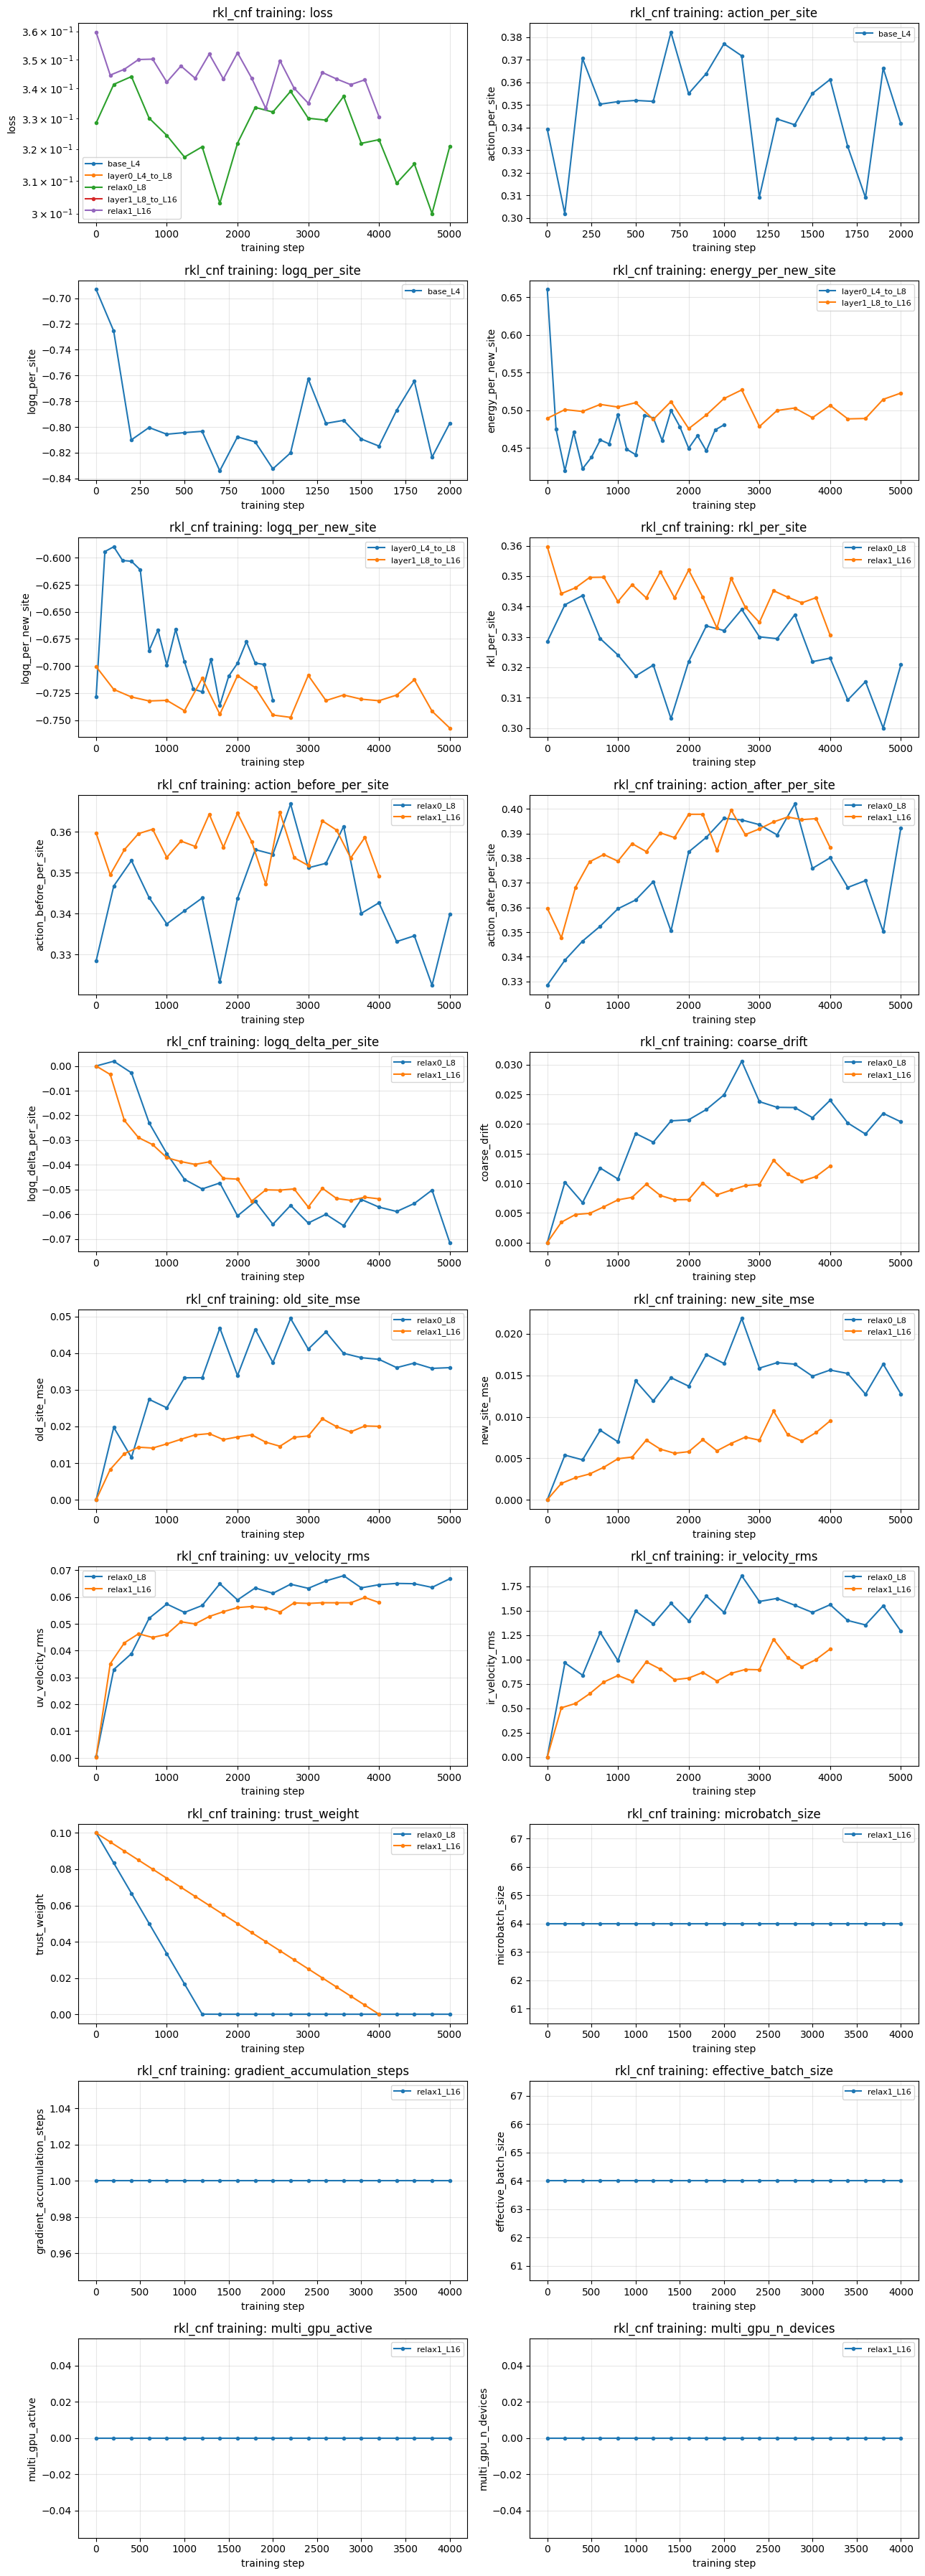

In [33]:
plot_training_diagnostics(training_result, log_loss=True)

<Axes: title={'center': 'rkl_cnf training: energy_per_new_site'}, xlabel='training step', ylabel='energy_per_new_site'>

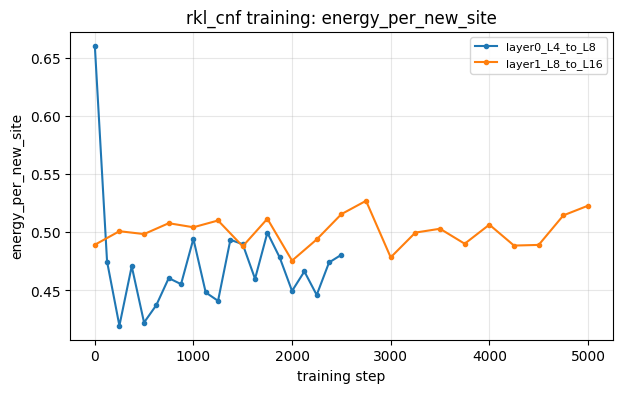

In [34]:
plot_training_metric(training_result, metric="energy_per_new_site")

# 9. Validation

In [35]:
from typing import Callable, Dict, Optional, Any, Union, List, Tuple

TensorLike = Union[torch.Tensor, np.ndarray]

@dataclass
class ParadigmOutput:
    """
    Container for one trained sampler's full-rollout outputs.

    samples:
        Generated full lattice samples, shape [N, ...].

    logq_samples:
        Fully normalized log q_theta(x) for generated samples.
        Needed for RKL and density-based ESS.
        Available for CNF / likelihood-based EWFM.

    logq_mcmc:
        Fully normalized log q_theta(x_mcmc) evaluated on MCMC samples.
        Needed for NLL / forward-KL proxy.

    path_logw:
        Total target-corrected full-path log weights.
        Native for NETS / AIS / Jarzynski-style methods and aligned with
        the same generated particle ancestries.

    training_metrics:
        Optional dictionary, e.g. natural loss values from training.
    """
    samples: TensorLike
    logq_samples: Optional[TensorLike] = None
    logq_mcmc: Optional[TensorLike] = None
    path_logw: Optional[TensorLike] = None
    training_metrics: Optional[Dict[str, Any]] = None

class FullLatticeSamplerEvaluator:
    """
    Evaluate full-lattice samples against MCMC reference samples.

    Main philosophy:
        - Do not evaluate conditional per-layer quality unless explicitly needed.
        - Compare final generated L128 samples against final MCMC L128 samples.
        - Use likelihood-based metrics only when log q is actually available.
        - Use path ESS only when valid path weights are available, e.g. NETS.

    Parameters
    ----------
    mcmc_samples:
        Full MCMC lattice samples, shape [N, ...].

    energy_fn:
        Callable mapping samples [N, ...] -> action/energy S(x), shape [N].
        This should be the full target action at the final lattice size.

    observable_fn:
        Optional callable mapping samples [N, ...] -> dict[str, TensorLike].
        Example observables: energy, magnetization, correlation, structure factor bins.

    feature_fn:
        Optional callable mapping samples [N, ...] -> features [N, D] for C2ST.
        If None, flattened raw samples are used.

    normalize_by_dim:
        If True, RKL proxy values are divided by number of lattice variables.
        NLL and unnormalized RNLL are always reported per site so that
        different lattice sizes can be compared.

    device:
        Torch device.
    """

    def __init__(
        self,
        mcmc_samples: TensorLike,
        energy_fn: Callable[[torch.Tensor], torch.Tensor],
        observable_fn: Optional[Callable[[torch.Tensor], Dict[str, TensorLike]]] = None,
        feature_fn: Optional[Callable[[torch.Tensor], TensorLike]] = None,
        normalize_by_dim: bool = True,
        device: Optional[Union[str, torch.device]] = None,
        batch_size: int = 4096,
    ):
        self.device = torch.device(device) if device is not None else torch.device(
            "cuda" if torch.cuda.is_available() else "cpu"
        )
        # Keep the full reference ensemble on CPU; move only working batches.
        self.mcmc_samples = self._to_tensor(mcmc_samples).cpu()
        self.energy_fn = energy_fn
        self.observable_fn = observable_fn
        self.feature_fn = feature_fn
        self.normalize_by_dim = normalize_by_dim
        self.batch_size = batch_size

        if self.mcmc_samples.ndim < 2:
            raise ValueError("mcmc_samples should have shape [N, ...].")

        self.sample_shape = tuple(self.mcmc_samples.shape[1:])
        self.dim = int(np.prod(self.sample_shape))

        self._mcmc_energy_cache = None
        self._mcmc_observable_cache = None

    # ------------------------------------------------------------------
    # Basic utilities
    # ------------------------------------------------------------------

    @staticmethod
    def _to_tensor(x: TensorLike, dtype: torch.dtype = torch.float32) -> torch.Tensor:
        if isinstance(x, torch.Tensor):
            return x.detach()
        return torch.as_tensor(x, dtype=dtype)

    def _scale(self, value: torch.Tensor) -> torch.Tensor:
        if self.normalize_by_dim:
            return value / self.dim
        return value

    def _batch_apply(
        self,
        fn: Callable[[torch.Tensor], TensorLike],
        x: torch.Tensor,
    ) -> torch.Tensor:
        outs = []
        with torch.no_grad():
            for start in range(0, x.shape[0], self.batch_size):
                xb = x[start:start + self.batch_size].to(self.device)
                out = fn(xb)
                out = self._to_tensor(out).to(self.device)
                outs.append(out)
        return torch.cat(outs, dim=0)

    def _energy(self, x: torch.Tensor) -> torch.Tensor:
        e = self._batch_apply(self.energy_fn, x)
        return e.reshape(-1)

    def _mcmc_energy(self) -> torch.Tensor:
        if self._mcmc_energy_cache is None:
            self._mcmc_energy_cache = self._energy(self.mcmc_samples)
        return self._mcmc_energy_cache

    # ------------------------------------------------------------------
    # Unnormalized reverse NLL (target action)
    # ------------------------------------------------------------------

    def rnll_unnormalized(self, generated_samples: TensorLike) -> Dict[str, float]:
        """
        Unnormalized reverse NLL per site:
            RNLL_unnorm / V = E_q[S(x)] / V.

        For p(x) = exp(-S(x)) / Z, the normalized reverse cross-entropy
        additionally contains log Z / V. We do not estimate or report Z.
        Consequently this metric is comparable only for the same target
        action and is interpreted together with NLL and diversity metrics.

        This is available for all methods.
        """
        xg = self._to_tensor(generated_samples).to(self.device)
        eg = self._energy(xg)
        em = self._mcmc_energy()

        gen_mean = eg.mean() / self.dim
        mcmc_mean = em.mean() / self.dim
        gap = gen_mean - mcmc_mean

        return {
            "rnll_unnormalized_per_site": float(gen_mean.cpu()),
            "mcmc_action_per_site": float(mcmc_mean.cpu()),
            "action_gap_per_site_gen_minus_mcmc": float(gap.cpu()),
            "generated_action_std_per_site": float((eg.std(unbiased=False) / self.dim).cpu()),
            "mcmc_action_std_per_site": float((em.std(unbiased=False) / self.dim).cpu()),
        }

    # ------------------------------------------------------------------
    # Normalized model NLL
    # ------------------------------------------------------------------

    def nll(self, logq_mcmc: TensorLike) -> Dict[str, float]:
        """
        Site-average NLL on MCMC reference samples:
            NLL / V = -E_{p_mcmc}[log q_theta(x)] / V.

        This is a proxy for forward KL:
            KL(p || q) = E_p[log p - log q].

        Requires the fully normalized model log density log q_theta,
        including the base-density normalization constants. Target Z is
        not involved.
        """
        logq = self._to_tensor(logq_mcmc).to(self.device).reshape(-1)

        if logq.shape[0] != self.mcmc_samples.shape[0]:
            raise ValueError(
                f"logq_mcmc length {logq.shape[0]} does not match "
                f"MCMC sample count {self.mcmc_samples.shape[0]}."
            )

        nll_value = (-logq).mean() / self.dim

        return {
            "nll_per_site": float(nll_value.cpu()),
        }

    # ------------------------------------------------------------------
    # RKL
    # ------------------------------------------------------------------

    def rkl(
        self,
        generated_samples: TensorLike,
        logq_samples: TensorLike,
    ) -> Dict[str, float]:
        """
        Reverse KL up to unknown log Z:
            KL(q || p) = E_q[log q(x) + S(x)] + log Z.

        Requires log q_theta for generated samples.
        """
        xg = self._to_tensor(generated_samples).to(self.device)
        logq = self._to_tensor(logq_samples).to(self.device).reshape(-1)

        if logq.shape[0] != xg.shape[0]:
            raise ValueError(
                f"logq_samples length {logq.shape[0]} does not match "
                f"generated sample count {xg.shape[0]}."
            )

        eg = self._energy(xg)
        rkl_value = self._scale((logq + eg).mean())

        return {
            "rkl_proxy": float(rkl_value.cpu()),
            "mean_logq_generated": float(self._scale(logq.mean()).cpu()),
        }

    # ------------------------------------------------------------------
    # ESS
    # ------------------------------------------------------------------

    @staticmethod
    def _ess_from_log_weights(logw: torch.Tensor) -> Dict[str, float]:
        """
        Compute absolute ESS and relative ESS from log weights.

        rESS = ESS / N = 1 / (N * sum_i wbar_i^2).
        """
        logw = logw.reshape(-1)
        n = logw.numel()

        logw_norm = logw - torch.logsumexp(logw, dim=0)
        wbar = torch.exp(logw_norm)

        ess = 1.0 / torch.sum(wbar ** 2)
        ress = ess / n
        if ess > n + 1e-4:
            raise RuntimeError(f"Invalid ESS {float(ess.cpu())} exceeds number of weights {n}.")

        return {
            "n_weights": int(n),
            "ess_over_n": float(ress.cpu()),
            "ess_abs": float(ess.cpu()),
            "logw_mean": float(logw.mean().cpu()),
            "logw_std": float(logw.std(unbiased=False).cpu()),
            "logw_min": float(logw.min().cpu()),
            "logw_max": float(logw.max().cpu()),
        }

    def density_ess(
        self,
        generated_samples: TensorLike,
        logq_samples: TensorLike,
    ) -> Dict[str, float]:
        """
        Final-sample IS ESS using:
            log w = -S(x) - log q_theta(x).

        Available for likelihood-based samplers, e.g. CNF or likelihood-based EWFM.
        """
        xg = self._to_tensor(generated_samples).to(self.device)
        logq = self._to_tensor(logq_samples).to(self.device).reshape(-1)

        if logq.shape[0] != xg.shape[0]:
            raise ValueError(
                f"logq_samples length {logq.shape[0]} does not match "
                f"generated sample count {xg.shape[0]}."
            )

        eg = self._energy(xg)
        logw = -eg - logq

        out = self._ess_from_log_weights(logw)
        out = {f"density_{k}": v for k, v in out.items()}

        return out

    def _normalized_density_weights(
        self,
        generated_samples: TensorLike,
        logq_samples: TensorLike,
    ) -> torch.Tensor:
        """Return stable self-normalized weights for generated samples."""
        xg = self._to_tensor(generated_samples).to(self.device)
        logq = self._to_tensor(logq_samples).to(self.device).reshape(-1)
        if logq.shape[0] != xg.shape[0]:
            raise ValueError(
                f"logq_samples length {logq.shape[0]} does not match "
                f"generated sample count {xg.shape[0]}."
            )
        logw = (-self._energy(xg) - logq).double()
        return torch.softmax(logw, dim=0)

    def path_ess(self, path_logw: TensorLike) -> Dict[str, float]:
        """
        ESS from target-corrected path weights, e.g. NETS / AIS / Jarzynski.

        path_logw must be the accumulated ancestry weight after any
        hierarchical-to-target action correction, not a normalized local
        training weight or a per-layer ESS.
        """
        logw = self._to_tensor(path_logw).to(self.device).reshape(-1)
        out = self._ess_from_log_weights(logw)
        return {f"path_{k}": v for k, v in out.items()}

    # ------------------------------------------------------------------
    # Observables
    # ------------------------------------------------------------------

    def _observables(self, x: torch.Tensor) -> Dict[str, torch.Tensor]:
        if self.observable_fn is None:
            return {}

        raw = self.observable_fn(x)
        out = {}
        for key, value in raw.items():
            value = self._to_tensor(value).to(self.device)
            if value.ndim == 0:
                value = value.reshape(1)
            out[key] = value
        return out

    def _mcmc_observables(self) -> Dict[str, torch.Tensor]:
        if self.observable_fn is None:
            return {}
        if self._mcmc_observable_cache is None:
            self._mcmc_observable_cache = self._observables(self.mcmc_samples)
        return self._mcmc_observable_cache

    def observable_gaps(
        self,
        generated_samples: TensorLike,
        logq_samples: Optional[TensorLike] = None,
    ) -> Dict[str, float]:
        """
        Compare raw and, when log q is available, self-normalized IS
        observables between generated and MCMC samples.

        The observable_fn may return:
            {"magnetization": [N],
             "corr_r1": [N],
             "structure_factor": [N, K],
             ...}

        For vector-valued observables, reports mean absolute gap and RMSE.
        """
        if self.observable_fn is None:
            return {}

        xg = self._to_tensor(generated_samples).to(self.device)
        obs_g = self._observables(xg)
        obs_m = self._mcmc_observables()
        weights = (
            self._normalized_density_weights(xg, logq_samples)
            if logq_samples is not None
            else None
        )

        metrics = {}

        for key in obs_m.keys():
            if key not in obs_g:
                continue

            gm = obs_g[key].float()
            mm = obs_m[key].float()

            # Average over samples, preserve observable dimension if any.
            gm_mean = gm.mean(dim=0)
            mm_mean = mm.mean(dim=0)
            gap = gm_mean - mm_mean

            # Std over MCMC samples, used for normalized error.
            mm_std = mm.std(dim=0, unbiased=False)
            z_gap = gap / (mm_std + 1e-8)

            metrics[f"obs_{key}_gen_mean"] = float(gm_mean.mean().cpu())
            # Explicit raw aliases make the comparison with IS estimates clear;
            # the historical gen_mean names are retained for compatibility.
            metrics[f"obs_{key}_raw_mean"] = float(gm_mean.mean().cpu())
            metrics[f"obs_{key}_mcmc_mean"] = float(mm_mean.mean().cpu())
            metrics[f"obs_{key}_mean_abs_gap"] = float(gap.abs().mean().cpu())
            metrics[f"obs_{key}_rmse_gap"] = float(torch.sqrt((gap ** 2).mean()).cpu())
            metrics[f"obs_{key}_mean_abs_z_gap"] = float(z_gap.abs().mean().cpu())
            metrics[f"obs_{key}_raw_mean_abs_gap"] = float(gap.abs().mean().cpu())

            if weights is not None:
                wshape = (weights.shape[0],) + (1,) * (gm.ndim - 1)
                is_mean = (gm.double() * weights.reshape(wshape)).sum(dim=0)
                is_gap = is_mean - mm_mean.double()
                is_z_gap = is_gap / (mm_std.double() + 1e-8)
                metrics[f"obs_{key}_is_mean"] = float(is_mean.mean().cpu())
                metrics[f"obs_{key}_is_mean_abs_gap"] = float(is_gap.abs().mean().cpu())
                metrics[f"obs_{key}_is_rmse_gap"] = float(
                    torch.sqrt((is_gap ** 2).mean()).cpu()
                )
                metrics[f"obs_{key}_is_mean_abs_z_gap"] = float(
                    is_z_gap.abs().mean().cpu()
                )

        return metrics

    def critical_observable_metrics(
        self,
        generated_samples: TensorLike,
        logq_samples: Optional[TensorLike] = None,
    ) -> Dict[str, float]:
        """Compute raw and self-normalized-IS susceptibility and Binder cumulant.

        Susceptibility uses the Z2-symmetric finite-volume convention
            chi_abs = V * (<m^2> - <|m|>^2),
        while the Binder cumulant is
            U4 = 1 - <m^4> / (3 * <m^2>^2).
        These are ensemble-level metrics and must not be averaged per sample.
        """
        xg = self._to_tensor(generated_samples).to(self.device)
        xm = self.mcmc_samples
        reduce_g = tuple(range(1, xg.ndim))
        reduce_m = tuple(range(1, xm.ndim))
        mg = xg.double().mean(dim=reduce_g).reshape(-1)
        mm = xm.double().mean(dim=reduce_m).reshape(-1)
        volume = float(self.dim)

        def summarize(
            m: torch.Tensor,
            weights: Optional[torch.Tensor] = None,
        ) -> Tuple[torch.Tensor, torch.Tensor]:
            if weights is None:
                m2 = m.square().mean()
                m4 = m.pow(4).mean()
                mean_abs_m = m.abs().mean()
            else:
                weights = weights.to(device=m.device, dtype=m.dtype)
                m2 = (weights * m.square()).sum()
                m4 = (weights * m.pow(4)).sum()
                mean_abs_m = (weights * m.abs()).sum()
            chi_abs = volume * (m2 - mean_abs_m.square())
            binder = 1.0 - m4 / (3.0 * m2.square().clamp_min(1e-16))
            return chi_abs, binder

        chi_g, binder_g = summarize(mg)
        chi_m, binder_m = summarize(mm)
        chi_m = chi_m.to(chi_g.device)
        binder_m = binder_m.to(binder_g.device)
        metrics = {
            "obs_susceptibility_gen": float(chi_g.cpu()),
            "obs_susceptibility_raw": float(chi_g.cpu()),
            "obs_susceptibility_mcmc": float(chi_m.cpu()),
            "obs_susceptibility_abs_gap": float((chi_g - chi_m).abs().cpu()),
            "obs_susceptibility_raw_abs_gap": float((chi_g - chi_m).abs().cpu()),
            "obs_binder_cumulant_gen": float(binder_g.cpu()),
            "obs_binder_cumulant_raw": float(binder_g.cpu()),
            "obs_binder_cumulant_mcmc": float(binder_m.cpu()),
            "obs_binder_cumulant_abs_gap": float((binder_g - binder_m).abs().cpu()),
            "obs_binder_cumulant_raw_abs_gap": float((binder_g - binder_m).abs().cpu()),
        }

        if logq_samples is not None:
            weights = self._normalized_density_weights(xg, logq_samples)
            chi_is, binder_is = summarize(mg, weights)
            metrics.update({
                "obs_susceptibility_is": float(chi_is.cpu()),
                "obs_susceptibility_is_abs_gap": float((chi_is - chi_m).abs().cpu()),
                "obs_binder_cumulant_is": float(binder_is.cpu()),
                "obs_binder_cumulant_is_abs_gap": float(
                    (binder_is - binder_m).abs().cpu()
                ),
            })

        return metrics

    # ------------------------------------------------------------------
    # C2ST
    # ------------------------------------------------------------------

    def _features(self, x: torch.Tensor) -> np.ndarray:
        """
        Extract features for C2ST.

        If feature_fn is provided, use it.
        Otherwise flatten raw samples.
        """
        with torch.no_grad():
            if self.feature_fn is not None:
                feat = self.feature_fn(x)
                feat = self._to_tensor(feat).to(self.device)
            else:
                feat = x.reshape(x.shape[0], -1).float()

        if feat.ndim != 2:
            feat = feat.reshape(feat.shape[0], -1)

        return feat.detach().cpu().numpy()

    def c2st(
        self,
        generated_samples: TensorLike,
        max_samples_per_class: int = 5000,
        test_size: float = 0.3,
        n_repeats: int = 5,
        classifier: str = "logreg",
        random_state: int = 0,
    ) -> Dict[str, float]:
        """
        Classifier two-sample test.

        Label:
            MCMC      -> 1
            Generated -> 0

        Accuracy close to 0.5 means generated samples are hard to distinguish
        from MCMC samples.

        classifier:
            "logreg" or "rf".
        """
        try:
            from sklearn.model_selection import train_test_split
            from sklearn.preprocessing import StandardScaler
            from sklearn.pipeline import make_pipeline
            from sklearn.linear_model import LogisticRegression
            from sklearn.ensemble import RandomForestClassifier
            from sklearn.metrics import accuracy_score, roc_auc_score
        except ImportError as e:
            return {
                "c2st_error": f"scikit-learn is required for C2ST: {str(e)}"
            }

        xg = self._to_tensor(generated_samples).to(self.device)
        xm = self.mcmc_samples

        n = min(xg.shape[0], xm.shape[0], max_samples_per_class)
        if n < 10:
            return {"c2st_error": "Not enough samples for C2ST."}

        rng = np.random.default_rng(random_state)

        accs: List[float] = []
        aucs: List[float] = []

        for r in range(n_repeats):
            idx_g = rng.choice(xg.shape[0], size=n, replace=False)
            idx_m = rng.choice(xm.shape[0], size=n, replace=False)

            fg = self._features(xg[idx_g])
            fm = self._features(xm[idx_m])

            X = np.concatenate([fm, fg], axis=0)
            y = np.concatenate([np.ones(n), np.zeros(n)], axis=0)

            X_train, X_test, y_train, y_test = train_test_split(
                X,
                y,
                test_size=test_size,
                random_state=random_state + r,
                stratify=y,
            )

            if classifier == "logreg":
                clf = make_pipeline(
                    StandardScaler(),
                    LogisticRegression(
                        max_iter=2000,
                        class_weight="balanced",
                        solver="lbfgs",
                    ),
                )
            elif classifier == "rf":
                clf = RandomForestClassifier(
                    n_estimators=300,
                    max_depth=None,
                    min_samples_leaf=2,
                    class_weight="balanced",
                    random_state=random_state + r,
                    n_jobs=-1,
                )
            else:
                raise ValueError("classifier should be 'logreg' or 'rf'.")

            clf.fit(X_train, y_train)
            pred = clf.predict(X_test)
            acc = accuracy_score(y_test, pred)
            accs.append(acc)

            try:
                prob = clf.predict_proba(X_test)[:, 1]
                auc = roc_auc_score(y_test, prob)
                aucs.append(auc)
            except Exception:
                pass

        out = {
            "c2st_acc_mean": float(np.mean(accs)),
            "c2st_acc_std": float(np.std(accs)),
            "c2st_acc_excess_over_0p5": float(np.mean(accs) - 0.5),
        }

        if len(aucs) > 0:
            out["c2st_auc_mean"] = float(np.mean(aucs))
            out["c2st_auc_std"] = float(np.std(aucs))

        return out

    # ------------------------------------------------------------------
    # Main evaluation call
    # ------------------------------------------------------------------

    def evaluate_one(
        self,
        output: Union[ParadigmOutput, Dict[str, Any], TensorLike],
        paradigm_name: str = "unknown",
        compute_c2st: bool = True,
        c2st_kwargs: Optional[Dict[str, Any]] = None,
    ) -> Dict[str, Any]:
        """
        Evaluate one sampler.

        output can be:
            - ParadigmOutput
            - dict with keys:
                samples, logq_samples, logq_mcmc, path_logw, training_metrics
            - raw generated samples tensor/array
        """
        if isinstance(output, ParadigmOutput):
            pack = output
        elif isinstance(output, dict):
            pack = ParadigmOutput(
                samples=output["samples"],
                logq_samples=output.get("logq_samples", None),
                logq_mcmc=output.get("logq_mcmc", None),
                path_logw=output.get("path_logw", None),
                training_metrics=output.get("training_metrics", None),
            )
        else:
            pack = ParadigmOutput(samples=output)

        metrics: Dict[str, Any] = {
            "paradigm": paradigm_name,
            "n_generated": int(self._to_tensor(pack.samples).shape[0]),
            "n_mcmc": int(self.mcmc_samples.shape[0]),
            "sample_dim": int(self.dim),
        }

        # Common metrics available for all.
        metrics.update(self.rnll_unnormalized(pack.samples))
        metrics.update(self.observable_gaps(pack.samples, pack.logq_samples))
        metrics.update(self.critical_observable_metrics(pack.samples, pack.logq_samples))

        # Site-average NLL if normalized log q on MCMC samples is available.
        if pack.logq_mcmc is not None:
            metrics.update(self.nll(pack.logq_mcmc))
        else:
            metrics["nll_per_site"] = None

        # RKL and density ESS if log q on generated samples is available.
        if pack.logq_samples is not None:
            metrics.update(self.rkl(pack.samples, pack.logq_samples))
            metrics.update(self.density_ess(pack.samples, pack.logq_samples))
        else:
            metrics["rkl_proxy"] = None
            metrics["density_ess_over_n"] = None
            metrics["density_ess_abs"] = None

        # Path ESS if path weights are available, e.g. NETS.
        if pack.path_logw is not None:
            metrics.update(self.path_ess(pack.path_logw))
        else:
            metrics["path_ess_over_n"] = None
            metrics["path_ess_abs"] = None

        # C2ST is common and likelihood-free.
        if compute_c2st:
            kwargs = c2st_kwargs or {}
            metrics.update(self.c2st(pack.samples, **kwargs))

        # Attach training metrics if provided.
        if pack.training_metrics is not None:
            for k, v in pack.training_metrics.items():
                metrics[f"train_{k}"] = v

        return metrics

    def evaluate(
        self,
        paradigm_outputs: Dict[str, Union[ParadigmOutput, Dict[str, Any], TensorLike]],
        compute_c2st: bool = True,
        c2st_kwargs: Optional[Dict[str, Any]] = None,
    ) -> Dict[str, Dict[str, Any]]:
        """
        Evaluate multiple paradigms.

        Example keys:
            "rkl_cnf", "ewfm", "nets", "idem".
        """
        results = {}

        for name, output in paradigm_outputs.items():
            results[name] = self.evaluate_one(
                output=output,
                paradigm_name=name,
                compute_c2st=compute_c2st,
                c2st_kwargs=c2st_kwargs,
            )

        return results

In [36]:
# Optional observables for physical diagnostics.
def make_observable_fn(cfg: Phi4Config):
    def observable_fn(x: torch.Tensor) -> Dict[str, torch.Tensor]:
        return {
            "magnetization": x.mean(dim=(-2, -1)),
            "energy": phi4_action(x, cfg),
            # "corr_r1": nearest_neighbor_corr(x),
            # "structure_factor": structure_factor_bins(x),
        }
    return observable_fn

# Optional global-summary C2ST feature function (not the default).
# This reduces each configuration to [total energy, global m, global |m|]
# and therefore does not directly test individual sites or general spatial correlations.
def make_feature_fn(cfg: Phi4Config):
    def feature_fn(x: torch.Tensor) -> torch.Tensor:
        energy = phi4_action(x, cfg).reshape(-1, 1)
        mag = x.mean(dim=(-2, -1), keepdim=False).reshape(-1, 1)
        abs_mag = mag.abs()
        return torch.cat([energy, mag, abs_mag], dim=1)
    return feature_fn

def notebook_dir() -> Path:
    """Best-effort notebook directory for local files."""
    try:
        return Path(__file__).resolve().parent
    except NameError:
        return Path.cwd()

def find_mcmc_file_for_L(L: int, mcmc_dir: Optional[Union[str, Path]] = None) -> Path:
    """Find the MCMC .npy file matching lattice size L."""
    mcmc_dir = Path(mcmc_dir) if mcmc_dir is not None else notebook_dir() / "MCMC_samples"

    preferred = mcmc_dir / f"phi4_L{L}_Singha2026_better.npy"
    if preferred.exists():
        return preferred
    default = mcmc_dir / f"phi4_L{L}_Singha2026.npy"
    if default.exists():
        return default
    matches = sorted(mcmc_dir.glob(f"phi4_L{L}_*.npy"))
    if matches:
        return matches[0]
    raise FileNotFoundError(f"No MCMC sample file found for L={L} under {mcmc_dir}")

def load_mcmc_samples_for_L(
    L: int,
    mcmc_dir: Optional[Union[str, Path]] = None,
    max_samples: Optional[int] = None,
    device: Optional[Union[str, torch.device]] = None,
    convert_to_pipeline_units: bool = True,
) -> torch.Tensor:
    """Load MCMC samples as [N, 1, L, L] float tensor.

    Samples written by mcmc_phi4.py use the field convention
        S(y) = sum[(dy)^2 + m2*y^2 + lam*y^4].
    The generative pipeline uses
        S(x) = sum[0.5*(dx)^2 + 0.5*m2*x^2 + 0.25*lam*x^4].
    They describe the same Singha2026 target with x = sqrt(2)*y.
    Conversion is enabled by default so all validation is performed in
    the pipeline convention. Set convert_to_pipeline_units=False only
    when loading samples that are already stored in pipeline units.
    """
    path = find_mcmc_file_for_L(L, mcmc_dir=mcmc_dir)
    arr = np.load(path, mmap_mode="r")
    if max_samples is not None:
        arr = arr[:max_samples]
    # Scaling requires an owned array; the copy also avoids PyTorch's
    # non-writable warning for memory-mapped NumPy arrays.
    x = torch.from_numpy(np.array(arr, dtype=np.float32, copy=True))
    field_scale = float(np.sqrt(2.0)) if convert_to_pipeline_units else 1.0
    if convert_to_pipeline_units:
        x.mul_(field_scale)
    if x.ndim == 3:
        x = x[:, None, :, :]
    if x.shape[-2:] != (L, L):
        raise ValueError(f"Loaded MCMC samples from {path} have shape {tuple(x.shape)}, expected final lattice {L}x{L}.")
    if device is not None:
        x = x.to(torch.device(device))
    print({
        "loaded_mcmc": str(path),
        "shape": tuple(x.shape),
        "field_conversion": "mcmc_phi4 -> pipeline" if convert_to_pipeline_units else "none",
        "field_scale": field_scale,
    })
    return x

def make_default_validation_evaluator(
    mcmc_samples: TensorLike,
    cfg: Phi4Config,
    batch_size: int = 2048,
    normalize_by_dim: bool = True,
) -> FullLatticeSamplerEvaluator:
    """Create the default full-lattice evaluator.

    C2ST uses raw per-site values by default: feature_fn=None makes the
    evaluator flatten each [1, L, L] configuration to L^2 site features.
    This is a joint full-lattice test, not L^2 independent sitewise tests.
    Pass make_feature_fn(cfg) explicitly for the optional three-feature
    [energy, m, |m|] diagnostic.
    """
    return FullLatticeSamplerEvaluator(
        mcmc_samples=mcmc_samples,
        energy_fn=lambda x: phi4_action(x, cfg),
        observable_fn=make_observable_fn(cfg),
        # Default C2ST: retain every raw site as a separate classifier feature.
        feature_fn=None,
        normalize_by_dim=normalize_by_dim,
        batch_size=batch_size,
    )

def validation_scales_from_training_result(training_result: Dict[str, object]) -> List[int]:
    """Return all lattice sizes represented by a trained layerwise stack."""
    scales = [int(training_result["base_L"])]
    scales.extend(int(rec["L_fine"]) for rec in training_result["layers"])
    return scales

def make_validation_evaluators_by_scale(
    training_result: Dict[str, object],
    cfg: Phi4Config,
    mcmc_dir: Optional[Union[str, Path]] = None,
    max_samples: Optional[int] = None,
    batch_size: int = 2048,
    convert_mcmc_to_pipeline_units: bool = True,
) -> Tuple[Dict[int, FullLatticeSamplerEvaluator], Dict[int, torch.Tensor]]:
    """Load matching MCMC references and create one evaluator for each rollout scale."""
    evaluators: Dict[int, FullLatticeSamplerEvaluator] = {}
    mcmc_by_scale: Dict[int, torch.Tensor] = {}
    scales = validation_scales_from_training_result(training_result)
    print({"validation_scales": scales})
    for L in scales:
        # Keep full reference lattices on CPU; likelihood evaluation streams GPU batches.
        mcmc = load_mcmc_samples_for_L(
            L,
            mcmc_dir=mcmc_dir,
            max_samples=max_samples,
            device="cpu",
            convert_to_pipeline_units=convert_mcmc_to_pipeline_units,
        )
        mcmc_by_scale[L] = mcmc
        evaluators[L] = make_default_validation_evaluator(mcmc, cfg, batch_size=batch_size)
    return evaluators, mcmc_by_scale


# Automatically load reference MCMC sets matching every rollout scale.
# For L64, this prefers phi4_L64_Singha2026_better.npy when present.
VALIDATION_MCMC_MAX_SAMPLES = None
# mcmc_phi4.py stores y; the pipeline models x=sqrt(2)*y. Keep this True
# for the existing phi4_L*_Singha2026.npy reference files.
VALIDATION_MCMC_CONVERT_TO_PIPELINE_UNITS = True
if "training_result" in globals():
    evaluators_by_scale, mcmc_by_scale = make_validation_evaluators_by_scale(
        training_result,
        cfg,
        max_samples=VALIDATION_MCMC_MAX_SAMPLES,
        convert_mcmc_to_pipeline_units=VALIDATION_MCMC_CONVERT_TO_PIPELINE_UNITS,
    )
    evaluator = evaluators_by_scale[training_result["final_L"]]
    mcmc_real = mcmc_by_scale[training_result["final_L"]]
    print({"validation_evaluators_ready": sorted(evaluators_by_scale.keys())})
else:
    evaluators_by_scale = {}
    mcmc_by_scale = {}
    mcmc_real = None
    evaluator = None
    print("training_result is not defined yet; run training before creating validation evaluators.")

{'validation_scales': [4, 8, 16]}
{'loaded_mcmc': '/scratch/kzhang9/KUL/MCMC_samples/phi4_L4_Singha2026.npy', 'shape': (10000, 1, 4, 4), 'field_conversion': 'mcmc_phi4 -> pipeline', 'field_scale': 1.4142135623730951}
{'loaded_mcmc': '/scratch/kzhang9/KUL/MCMC_samples/phi4_L8_Singha2026.npy', 'shape': (10000, 1, 8, 8), 'field_conversion': 'mcmc_phi4 -> pipeline', 'field_scale': 1.4142135623730951}
{'loaded_mcmc': '/scratch/kzhang9/KUL/MCMC_samples/phi4_L16_Singha2026.npy', 'shape': (10000, 1, 16, 16), 'field_conversion': 'mcmc_phi4 -> pipeline', 'field_scale': 1.4142135623730951}
{'validation_evaluators_ready': [4, 8, 16]}


In [37]:
def extract_layer_variable(fine: torch.Tensor, coarse: torch.Tensor, mode: str = "residual", cfg: Optional[Phi4Config] = None) -> torch.Tensor:
    """Extract the trained layer variable from a fine lattice and its even-even coarse ancestor."""
    return get_partition(cfg).extract(fine, coarse, mode=mode)

def decompose_lattice_stack(x: torch.Tensor, base_L: int, n_layers: int, mode: str = "residual", cfg: Optional[Phi4Config] = None) -> Tuple[torch.Tensor, List[Tuple[torch.Tensor, torch.Tensor]]]:
    """Decompose an external lattice into base field and per-layer (coarse, variable)."""
    if x.ndim == 3:
        x = x[:, None, :, :]
    expected_L = base_L * (2 ** n_layers)
    if x.shape[-1] != expected_L or x.shape[-2] != expected_L:
        raise ValueError(f"Expected {expected_L}x{expected_L} samples, got {tuple(x.shape)}.")

    fine_by_level: List[torch.Tensor] = [x]
    cur = x
    for _ in range(n_layers):
        cur = get_partition(cfg).coarsen_completed_lattice(cur)
        fine_by_level.append(cur)
    fine_by_level = list(reversed(fine_by_level))
    base = fine_by_level[0]

    layer_vars: List[Tuple[torch.Tensor, torch.Tensor]] = []
    for layer_idx in range(n_layers):
        coarse = fine_by_level[layer_idx]
        fine = fine_by_level[layer_idx + 1]
        var = extract_layer_variable(fine, coarse, mode=mode, cfg=cfg)
        layer_vars.append((coarse, var))
    return base, layer_vars

def inverse_base_cnf_logq(model: BaseFieldCNF, x: torch.Tensor) -> torch.Tensor:
    """Approximate log q(x) by Euler-integrating a base CNF backward to its source."""
    z = x
    integral_div = torch.zeros(x.shape[0], device=x.device, dtype=x.dtype)
    dt = 1.0 / model.n_steps
    for k in reversed(range(model.n_steps)):
        t = torch.full((z.shape[0],), (k + 0.5) * dt, device=z.device, dtype=z.dtype)
        z = z.detach().requires_grad_(True)
        v, div = compute_divergence(
            lambda x_, t_, _unused: model.velocity(x_, t_),
            z,
            t,
            None,
            mode=model.divergence_mode,
            hutchinson_samples=model.hutchinson_samples,
            create_graph=False,
        )
        integral_div = integral_div + dt * div
        z = z - dt * v
    return model.base_log_prob(z.detach()) - integral_div.detach()

def inverse_residual_cnf_logq(model: ResidualCNF, r: torch.Tensor, coarse: torch.Tensor) -> torch.Tensor:
    """Approximate log q(r|coarse) by Euler-integrating a residual CNF backward."""
    z = r
    integral_div = torch.zeros(r.shape[0], device=r.device, dtype=r.dtype)
    dt = 1.0 / model.n_steps
    for k in reversed(range(model.n_steps)):
        t = torch.full((z.shape[0],), (k + 0.5) * dt, device=z.device, dtype=z.dtype)
        z = z.detach().requires_grad_(True)
        v, div = compute_divergence(
            model.velocity,
            z,
            t,
            coarse,
            mode=model.divergence_mode,
            hutchinson_samples=model.hutchinson_samples,
            create_graph=False,
        )
        integral_div = integral_div + dt * div
        z = z - dt * v
    return model.base_log_prob(z.detach()) - integral_div.detach()

def inverse_base_velocity_logq(velocity: BaseFieldVelocityMLP, x: torch.Tensor, cfg: Phi4Config, n_steps: Optional[int] = None) -> torch.Tensor:
    """Approximate log q(x) for a velocity-trained base ODE by backward Euler integration."""
    z = x
    n_steps = n_steps or cfg.cnf_steps
    dt = 1.0 / n_steps
    integral_div = torch.zeros(x.shape[0], device=x.device, dtype=x.dtype)
    old_flags = _set_module_requires_grad(velocity, False)
    was_training = velocity.training
    velocity.eval()
    try:
        for k in reversed(range(n_steps)):
            t = torch.full((z.shape[0],), (k + 0.5) * dt, device=z.device, dtype=z.dtype)
            z = z.detach().requires_grad_(True)
            v, div = compute_divergence(
                lambda x_, t_, _unused: velocity(x_, t_),
                z,
                t,
                None,
                mode=cfg.cnf_divergence_mode,
                hutchinson_samples=cfg.hutchinson_samples,
                create_graph=False,
            )
            integral_div = integral_div + dt * div
            z = z - dt * v
    finally:
        velocity.train(was_training)
        _restore_module_requires_grad(velocity, old_flags)
    return initial_log_prob(z.detach(), cfg, role="base") - integral_div.detach()

def inverse_residual_velocity_logq(velocity: ResidualVelocityMLP, r: torch.Tensor, coarse: torch.Tensor, cfg: Phi4Config, n_steps: Optional[int] = None) -> torch.Tensor:
    """Approximate log q(r|coarse) for a velocity-trained residual ODE by backward Euler integration."""
    z = r
    n_steps = n_steps or cfg.cnf_steps
    dt = 1.0 / n_steps
    integral_div = torch.zeros(r.shape[0], device=r.device, dtype=r.dtype)
    old_flags = _set_module_requires_grad(velocity, False)
    was_training = velocity.training
    velocity.eval()
    try:
        for k in reversed(range(n_steps)):
            t = torch.full((z.shape[0],), (k + 0.5) * dt, device=z.device, dtype=z.dtype)
            z = z.detach().requires_grad_(True)
            v, div = compute_divergence(
                velocity,
                z,
                t,
                coarse,
                mode=cfg.cnf_divergence_mode,
                hutchinson_samples=cfg.hutchinson_samples,
                create_graph=False,
            )
            integral_div = integral_div + dt * div
            z = z - dt * v
    finally:
        velocity.train(was_training)
        _restore_module_requires_grad(velocity, old_flags)
    return initial_log_prob(z.detach(), cfg, role="residual") - integral_div.detach()

def inverse_rkl_cnf_stack_logq(
    training_result: Dict[str, object],
    cfg: Phi4Config,
    x: torch.Tensor,
    mode: str = "residual",
) -> torch.Tensor:
    """Invert relaxation before residual decomposition at every hierarchy level."""
    current = x
    relaxation_logq = torch.zeros(x.shape[0], device=x.device, dtype=x.dtype)
    reversed_layers: List[Tuple[Dict[str, Any], torch.Tensor, torch.Tensor]] = []

    for rec in reversed(training_result["layers"]):
        relaxation = rec.get("relaxation")
        if relaxation is not None:
            current, logq_delta = inverse_rg_relaxation_cnf(relaxation, current)
            relaxation_logq = relaxation_logq + logq_delta
        coarse = get_partition(cfg).coarsen_completed_lattice(current)
        residual = extract_layer_variable(current, coarse, mode=mode, cfg=cfg)
        reversed_layers.append((rec, coarse, residual))
        current = coarse

    logq = inverse_base_cnf_logq(training_result["base_model"], current)
    for rec, coarse, residual in reversed(reversed_layers):
        logq = logq + inverse_residual_cnf_logq(rec["model"], residual, coarse)
    return logq + relaxation_logq

def ode_logq_on_external_lattice(training_result: Dict[str, object], cfg: Phi4Config, x: torch.Tensor, mode: str = "residual") -> torch.Tensor:
    """Evaluate approximate log q_theta(x) for external samples under an ODE-trained stack."""
    paradigm = training_result["paradigm"]
    if paradigm not in {"rkl_cnf", "ewfm", "rfm"}:
        raise ValueError("External logq is only available for ODE paradigms: rkl_cnf, ewfm, rfm.")
    x = x.to(torch.device(cfg.device))
    base_L = int(training_result["base_L"])
    layers = training_result["layers"]
    if paradigm == "rkl_cnf" and any(rec.get("relaxation") is not None for rec in layers):
        return inverse_rkl_cnf_stack_logq(training_result, cfg, x, mode=mode).detach().cpu()
    base_x, layer_vars = decompose_lattice_stack(x, base_L, len(layers), mode=mode, cfg=cfg)

    if paradigm == "rkl_cnf":
        logq = inverse_base_cnf_logq(training_result["base_model"], base_x)
        for rec, (coarse, r) in zip(layers, layer_vars):
            logq = logq + inverse_residual_cnf_logq(rec["model"], r, coarse)
        return logq.detach().cpu()

    logq = inverse_base_velocity_logq(training_result["base_model"], base_x, cfg)
    for rec, (coarse, r) in zip(layers, layer_vars):
        logq = logq + inverse_residual_velocity_logq(rec["model"], r, coarse, cfg)
    return logq.detach().cpu()

def external_logq_by_scale_for_ode(training_result: Dict[str, object], cfg: Phi4Config, mcmc_by_scale: Optional[Dict[int, torch.Tensor]], mode: str = "residual", likelihood_batch_size: int = 8) -> Dict[int, torch.Tensor]:
    """Compute external log q in CPU-backed batches at every rollout scale.

    Only one batch is moved to the GPU at a time. Each result is detached
    and returned to CPU before processing the next batch.
    """
    if mcmc_by_scale is None or training_result["paradigm"] not in {"rkl_cnf", "ewfm", "rfm"}:
        return {}
    if likelihood_batch_size <= 0:
        raise ValueError("likelihood_batch_size must be positive.")
    out: Dict[int, torch.Tensor] = {}
    full_layers = training_result["layers"]
    for L, x_mcmc in mcmc_by_scale.items():
        n_layers = int(round(math.log2(int(L) / int(training_result["base_L"]))))
        if n_layers < 0 or int(training_result["base_L"]) * (2 ** n_layers) != int(L):
            continue
        partial = dict(training_result)
        partial["layers"] = full_layers[:n_layers]
        partial["final_L"] = int(L)
        logq_batches: List[torch.Tensor] = []
        for start in range(0, x_mcmc.shape[0], likelihood_batch_size):
            x_batch_cpu = x_mcmc[start:start + likelihood_batch_size].detach().cpu()
            with torch.enable_grad():
                logq_batch_cpu = ode_logq_on_external_lattice(partial, cfg, x_batch_cpu, mode=mode)
            logq_batches.append(logq_batch_cpu.detach().cpu())
        out[int(L)] = torch.cat(logq_batches, dim=0)
    return out

def selected_training_record(model: nn.Module) -> Optional[Dict[str, Any]]:
    """Return the history row corresponding to the weights restored before saving."""
    history = getattr(model, "training_history", None)
    if not history:
        return None
    selection = getattr(model, "training_selection", None) or {}
    best_step = selection.get("best_step")
    if best_step is not None:
        for record in reversed(history):
            if int(record.get("step", -1)) == int(best_step):
                return record
    return history[-1]

def collect_training_metrics(training_result: Dict[str, object], upto_layer_idx: Optional[int] = None) -> Dict[str, Any]:
    """Collect metrics for the selected/restored weights through a layer index."""
    metrics: Dict[str, Any] = {}
    base_model = training_result["base_model"]
    base_record = selected_training_record(base_model)
    if base_record:
        for k, v in base_record.items():
            metrics[f"base_{k}"] = v
        for k, v in (getattr(base_model, "training_selection", None) or {}).items():
            metrics[f"base_selection_{k}"] = v
    for k, v in (getattr(base_model, "training_resources", None) or {}).items():
        metrics[f"base_resource_{k}"] = v

    for rec in training_result["layers"]:
        if upto_layer_idx is not None and rec["idx"] > upto_layer_idx:
            continue
        layer_model = rec["model"]
        layer_record = selected_training_record(layer_model)
        if layer_record:
            for k, v in layer_record.items():
                metrics[f"layer{rec['idx']}_{k}"] = v
            for k, v in (getattr(layer_model, "training_selection", None) or {}).items():
                metrics[f"layer{rec['idx']}_selection_{k}"] = v
        for k, v in (getattr(layer_model, "training_resources", None) or {}).items():
            metrics[f"layer{rec['idx']}_resource_{k}"] = v
        relaxation_model = rec.get("relaxation")
        relaxation_record = selected_training_record(relaxation_model) if relaxation_model is not None else None
        if relaxation_record:
            for k, v in relaxation_record.items():
                metrics[f"relax{rec['idx']}_{k}"] = v
            for k, v in (getattr(relaxation_model, "training_selection", None) or {}).items():
                metrics[f"relax{rec['idx']}_selection_{k}"] = v
        if relaxation_model is not None:
            for k, v in (getattr(relaxation_model, "training_resources", None) or {}).items():
                metrics[f"relax{rec['idx']}_resource_{k}"] = v
    return metrics

def output_key(paradigm: str, L: int) -> str:
    return f"{paradigm}_L{int(L)}"

def rollout_rkl_cnf_multiscale_for_validation(training_result: Dict[str, object], cfg: Phi4Config, batch_size: Optional[int] = None, mode: str = "residual", logq_mcmc_by_scale: Optional[Dict[int, torch.Tensor]] = None) -> Dict[int, ParadigmOutput]:
    """Roll out RKL-CNF and record samples plus cumulative log q at every scale."""
    base_model = training_result["base_model"]
    batch_size = batch_size or cfg.batch_size
    device = torch.device(cfg.device)
    outputs: Dict[int, ParadigmOutput] = {}

    with torch.enable_grad():
        z = base_model.sample_base(batch_size, device=device)
        x, logq_total = base_model(z, compute_logq=True, create_graph=False)
        base_L = int(training_result["base_L"])
        outputs[base_L] = ParadigmOutput(
            samples=x.detach(),
            logq_samples=logq_total.detach(),
            logq_mcmc=None if logq_mcmc_by_scale is None else logq_mcmc_by_scale.get(base_L),
            training_metrics=collect_training_metrics(training_result, upto_layer_idx=-1),
        )

        for rec in training_result["layers"]:
            layer = rec["model"]
            z = layer.sample_base(batch_size, device=x.device)
            r, logq_layer = layer(z, x, compute_logq=True, create_graph=False)
            x = insert_residual(x, r, mode=mode)
            logq_total = logq_total + logq_layer
            relaxation = rec.get("relaxation")
            if relaxation is not None:
                x, logq_relax = relaxation(x, compute_logq=True, create_graph=False)
                logq_total = logq_total + logq_relax
            outputs[int(rec["L_fine"])] = ParadigmOutput(
                samples=x.detach(),
                logq_samples=logq_total.detach(),
                logq_mcmc=None if logq_mcmc_by_scale is None else logq_mcmc_by_scale.get(int(rec["L_fine"])),
                training_metrics=collect_training_metrics(training_result, upto_layer_idx=rec["idx"]),
            )
    return outputs

def rollout_velocity_ode_multiscale_for_validation(training_result: Dict[str, object], cfg: Phi4Config, batch_size: Optional[int] = None, mode: str = "residual", logq_mcmc_by_scale: Optional[Dict[int, torch.Tensor]] = None) -> Dict[int, ParadigmOutput]:
    """Roll out an EWFM/RFM velocity ODE and record cumulative log q at every scale."""
    base_velocity = training_result["base_model"]
    batch_size = batch_size or cfg.batch_size
    device = torch.device(cfg.device)
    outputs: Dict[int, ParadigmOutput] = {}

    with torch.enable_grad():
        z = sample_initial_field(cfg, batch_size, 1, base_velocity.L, device=device, role="base")
        x, logq_total = integrate_base_velocity_with_logq(base_velocity, z, cfg, create_graph=False)
        base_L = int(training_result["base_L"])
        outputs[base_L] = ParadigmOutput(
            samples=x.detach(),
            logq_samples=logq_total.detach(),
            logq_mcmc=None if logq_mcmc_by_scale is None else logq_mcmc_by_scale.get(base_L),
            training_metrics=collect_training_metrics(training_result, upto_layer_idx=-1),
        )

        for rec in training_result["layers"]:
            velocity = rec["model"]
            _, _, L, _ = x.shape
            z = sample_initial_field(cfg, batch_size, residual_channels_for_L(L, cfg), L, device=x.device, dtype=x.dtype)
            r, logq_layer = integrate_residual_velocity_with_logq(velocity, z, x, cfg, create_graph=False)
            x = insert_residual(x, r, mode=mode)
            logq_total = logq_total + logq_layer
            outputs[int(rec["L_fine"])] = ParadigmOutput(
                samples=x.detach(),
                logq_samples=logq_total.detach(),
                logq_mcmc=None if logq_mcmc_by_scale is None else logq_mcmc_by_scale.get(int(rec["L_fine"])),
                training_metrics=collect_training_metrics(training_result, upto_layer_idx=rec["idx"]),
            )
    return outputs

# Backward-compatible name retained for existing notebook callers.
rollout_ewfm_multiscale_for_validation = rollout_velocity_ode_multiscale_for_validation

@torch.no_grad()
def rollout_idem_multiscale_for_validation(training_result: Dict[str, object], cfg: Phi4Config, batch_size: Optional[int] = None, mode: str = "residual") -> Dict[int, ParadigmOutput]:
    """Roll out iDEM and record samples at every scale. No global log q/path IS is produced."""
    batch_size = batch_size or cfg.batch_size
    outputs: Dict[int, ParadigmOutput] = {}
    base_out = sample_idem_base_model(training_result["base_model"], cfg, batch_size=batch_size)
    x = base_out["samples"]
    base_L = int(training_result["base_L"])
    outputs[base_L] = ParadigmOutput(
        samples=x.detach(),
        training_metrics=collect_training_metrics(training_result, upto_layer_idx=-1),
    )

    for rec in training_result["layers"]:
        x = sample_idem_residual_layer(rec["model"], x, cfg, mode=mode)["fine"]
        outputs[int(rec["L_fine"])] = ParadigmOutput(
            samples=x.detach(),
            training_metrics=collect_training_metrics(training_result, upto_layer_idx=rec["idx"]),
        )
    return outputs

@torch.no_grad()
def rollout_nets_multiscale_for_validation(training_result: Dict[str, object], cfg: Phi4Config, batch_size: Optional[int] = None, mode: str = "residual") -> Dict[int, ParadigmOutput]:
    """Roll out one complete NETS ancestry and return target-corrected path weights.

    Raw local Jarzynski log weights multiply across conditional layers, so
    they are accumulated by addition along each particle's ancestry. The
    local endpoint energies define a hierarchical surrogate action
        S_hier = S_base + sum_l E_l.
    At every completed scale, path ESS must instead target the ordinary
    phi4 action S_L, hence
        logw_target = logw_path_total + S_hier - S_L.
    The normalized weights used inside NETS training are never accumulated.
    """
    batch_size = batch_size or cfg.batch_size
    outputs: Dict[int, ParadigmOutput] = {}
    base_out = sample_nets_langevin_base_model(training_result["base_model"], cfg, batch_size=batch_size)
    x = base_out["samples"]
    path_logw_total = base_out["path_logw"]
    hierarchical_action = base_out["action"].detach()
    target_action = phi4_action(x, cfg).detach()
    corrected_logw = path_logw_total + hierarchical_action - target_action
    base_L = int(training_result["base_L"])
    metrics = collect_training_metrics(training_result, upto_layer_idx=-1)
    metrics["path_logw_var"] = float(torch.var(corrected_logw.detach(), unbiased=False).cpu())
    outputs[base_L] = ParadigmOutput(samples=x.detach(), path_logw=corrected_logw.detach(), training_metrics=metrics)

    for rec in training_result["layers"]:
        out = sample_nets_langevin_residual_layer(rec["model"], x, cfg, mode=mode)
        x = out["fine"]
        path_logw_total = path_logw_total + out["path_logw"]
        hierarchical_action = hierarchical_action + out["energy"].detach()
        target_action = phi4_action(x, cfg).detach()
        corrected_logw = path_logw_total + hierarchical_action - target_action
        metrics = collect_training_metrics(training_result, upto_layer_idx=rec["idx"])
        metrics["path_logw_var"] = float(torch.var(corrected_logw.detach(), unbiased=False).cpu())
        outputs[int(rec["L_fine"])] = ParadigmOutput(samples=x.detach(), path_logw=corrected_logw.detach(), training_metrics=metrics)
    return outputs

def build_multiscale_paradigm_outputs_from_training_result(training_result: Dict[str, object], cfg: Phi4Config, batch_size: Optional[int] = None, mode: str = "residual", mcmc_by_scale: Optional[Dict[int, torch.Tensor]] = None, likelihood_batch_size: int = 8, generation_batch_size: Optional[int] = None) -> Dict[str, ParadigmOutput]:
    """Convert a trained stack into evaluator inputs, generating paths in GPU-safe chunks."""
    paradigm = training_result["paradigm"]
    total_batch_size = int(batch_size or cfg.batch_size)
    generation_batch_size = int(generation_batch_size or total_batch_size)
    if total_batch_size <= 0 or generation_batch_size <= 0:
        raise ValueError("batch_size and generation_batch_size must be positive.")
    generation_batch_size = min(generation_batch_size, total_batch_size)
    logq_mcmc_by_scale = external_logq_by_scale_for_ode(
        training_result, cfg, mcmc_by_scale, mode=mode, likelihood_batch_size=likelihood_batch_size
    )

    def rollout_once(chunk_size: int, external_logq: Optional[Dict[int, torch.Tensor]]) -> Dict[int, ParadigmOutput]:
        if paradigm == "rkl_cnf":
            return rollout_rkl_cnf_multiscale_for_validation(training_result, cfg, batch_size=chunk_size, mode=mode, logq_mcmc_by_scale=external_logq)
        if paradigm in {"ewfm", "rfm"}:
            return rollout_velocity_ode_multiscale_for_validation(training_result, cfg, batch_size=chunk_size, mode=mode, logq_mcmc_by_scale=external_logq)
        if paradigm == "idem":
            return rollout_idem_multiscale_for_validation(training_result, cfg, batch_size=chunk_size, mode=mode)
        if paradigm == "nets":
            return rollout_nets_multiscale_for_validation(training_result, cfg, batch_size=chunk_size, mode=mode)
        raise ValueError(f"Unknown trained paradigm: {paradigm}")

    if generation_batch_size == total_batch_size:
        by_scale = rollout_once(total_batch_size, logq_mcmc_by_scale)
        return {output_key(paradigm, L): out for L, out in by_scale.items()}

    chunks_by_scale: Dict[int, List[ParadigmOutput]] = {}
    completed = 0
    while completed < total_batch_size:
        chunk_size = min(generation_batch_size, total_batch_size - completed)
        # External-MCMC log q is computed once above, not once per generated chunk.
        chunk_outputs = rollout_once(chunk_size, {})
        for L, out in chunk_outputs.items():
            chunks_by_scale.setdefault(int(L), []).append(ParadigmOutput(
                samples=torch.as_tensor(out.samples).detach().cpu(),
                logq_samples=None if out.logq_samples is None else torch.as_tensor(out.logq_samples).detach().cpu(),
                path_logw=None if out.path_logw is None else torch.as_tensor(out.path_logw).detach().cpu(),
                training_metrics=out.training_metrics,
            ))
        del out, chunk_outputs  # Release this chunk's GPU tensors before starting the next one.
        completed += chunk_size
        if completed == total_batch_size or completed % max(generation_batch_size, total_batch_size // 10) == 0:
            print({"validation_generated": completed, "validation_total": total_batch_size})

    by_scale: Dict[int, ParadigmOutput] = {}
    for L, chunks in chunks_by_scale.items():
        def concatenate_optional(field: str) -> Optional[torch.Tensor]:
            values = [getattr(chunk, field) for chunk in chunks]
            if all(value is None for value in values):
                return None
            if any(value is None for value in values):
                raise RuntimeError(f"Inconsistent {field} availability across validation chunks.")
            return torch.cat(values, dim=0)

        by_scale[L] = ParadigmOutput(
            samples=torch.cat([torch.as_tensor(chunk.samples) for chunk in chunks], dim=0),
            logq_samples=concatenate_optional("logq_samples"),
            logq_mcmc=logq_mcmc_by_scale.get(L),
            path_logw=concatenate_optional("path_logw"),
            training_metrics=chunks[0].training_metrics,
        )
    return {output_key(paradigm, L): out for L, out in by_scale.items()}

# Build evaluator inputs from the currently trained stack at every available scale.
# ODE methods provide cumulative generated-sample log q at each scale.
# NETS provides cumulative Jarzynski path weights corrected to the completed-scale phi4 action.
# iDEM provides samples only; there is no global IS/logq in the current iDEM algorithm.
VALIDATION_BATCH_SIZE = 10000  # Total generated paths used for reported validation metrics.
VALIDATION_GENERATION_BATCH_SIZE = VALIDATION_BATCH_SIZE  # Complete paths processed on GPU at once; reduce to 16 or 8 if needed.
VALIDATION_LIKELIHOOD_BATCH_SIZE = 32  # Batch size only for log q on external MCMC samples.
VALIDATION_SAMPLING_SEED = 482014  # Change this to repeat validation with independent generated paths.
torch.manual_seed(VALIDATION_SAMPLING_SEED)
np.random.seed(VALIDATION_SAMPLING_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(VALIDATION_SAMPLING_SEED)
paradigm_outputs = build_multiscale_paradigm_outputs_from_training_result(
    training_result,
    cfg,
    batch_size=VALIDATION_BATCH_SIZE,
    mode="residual",
    mcmc_by_scale= None, #mcmc_by_scale if "mcmc_by_scale" in globals() else None,
    likelihood_batch_size=VALIDATION_LIKELIHOOD_BATCH_SIZE,
    generation_batch_size=VALIDATION_GENERATION_BATCH_SIZE,
)
print({"validation_sampling_seed": VALIDATION_SAMPLING_SEED})
print({"validation_batch_size_requested": VALIDATION_BATCH_SIZE})
print({"validation_generation_batch_size": VALIDATION_GENERATION_BATCH_SIZE})
print({"validation_likelihood_batch_size": VALIDATION_LIKELIHOOD_BATCH_SIZE})
print({"validation_outputs_ready": list(paradigm_outputs.keys())})
for name, output in paradigm_outputs.items():
    print({"validation_output": name, "n_samples": int(output.samples.shape[0])})

{'validation_sampling_seed': 482014}
{'validation_batch_size_requested': 10000}
{'validation_generation_batch_size': 10000}
{'validation_likelihood_batch_size': 32}
{'validation_outputs_ready': ['rkl_cnf_L4', 'rkl_cnf_L8', 'rkl_cnf_L16']}
{'validation_output': 'rkl_cnf_L4', 'n_samples': 10000}
{'validation_output': 'rkl_cnf_L8', 'n_samples': 10000}
{'validation_output': 'rkl_cnf_L16', 'n_samples': 10000}


In [38]:
def scale_from_output_key(name: str) -> int:
    """Parse lattice scale from keys like 'rkl_cnf_L32'."""
    return int(name.rsplit("_L", 1)[1])

if evaluators_by_scale:
    results = {}
    for name, output in paradigm_outputs.items():
        L = scale_from_output_key(name)
        print({"evaluating": name, "L": L, "n_generated": int(output.samples.shape[0])})
        if "VALIDATION_BATCH_SIZE" in globals() and int(output.samples.shape[0]) != int(VALIDATION_BATCH_SIZE):
            print({"warning": "paradigm_outputs sample count does not match VALIDATION_BATCH_SIZE; rerun the cell that builds paradigm_outputs", "expected": int(VALIDATION_BATCH_SIZE), "actual": int(output.samples.shape[0])})
        results[name] = evaluators_by_scale[L].evaluate_one(
            output=output,
            paradigm_name=name,
            compute_c2st=True,
            c2st_kwargs={
                "max_samples_per_class": 3000,
                "n_repeats": 5,
                "classifier": "logreg",
            },
        )
    print("validation results:")
    for name, metrics in results.items():
        print(name)
        for key, value in metrics.items():
            print(f"  {key}: {value}")
else:
    results = None
    print("Validation samples were built, but evaluators_by_scale is empty. Run training first and ensure matching MCMC_samples/phi4_L{L}_*.npy files exist.")

{'evaluating': 'rkl_cnf_L4', 'L': 4, 'n_generated': 10000}
{'evaluating': 'rkl_cnf_L8', 'L': 8, 'n_generated': 10000}
{'evaluating': 'rkl_cnf_L16', 'L': 16, 'n_generated': 10000}
validation results:
rkl_cnf_L4
  paradigm: rkl_cnf_L4
  n_generated: 10000
  n_mcmc: 10000
  sample_dim: 16
  rnll_unnormalized_per_site: 0.35915908217430115
  mcmc_action_per_site: 0.35404956340789795
  action_gap_per_site_gen_minus_mcmc: 0.005109518766403198
  generated_action_std_per_site: 0.17891450226306915
  mcmc_action_std_per_site: 0.17793679237365723
  obs_magnetization_gen_mean: 0.027742013335227966
  obs_magnetization_raw_mean: 0.027742013335227966
  obs_magnetization_mcmc_mean: -0.012013937346637249
  obs_magnetization_mean_abs_gap: 0.03975595161318779
  obs_magnetization_rmse_gap: 0.03975595161318779
  obs_magnetization_mean_abs_z_gap: 0.04663657397031784
  obs_magnetization_raw_mean_abs_gap: 0.03975595161318779
  obs_magnetization_is_mean: 0.002437347505526535
  obs_magnetization_is_mean_abs_gap:

In [ ]:
def validation_metric_names(results: Dict[str, Dict[str, Any]]) -> List[str]:
    """Return scalar metric names present in validation results."""
    names = set()
    for metrics in results.values():
        for key, value in metrics.items():
            if key == "paradigm" or value is None:
                continue
            if isinstance(value, (int, float, np.integer, np.floating)):
                names.add(key)
    return sorted(names)

def validation_results_to_series(results: Dict[str, Dict[str, Any]], metric: str) -> Tuple[List[int], List[float], List[str]]:
    """Extract one metric as y(L), ordered by lattice size."""
    rows = []
    for name, metrics in results.items():
        value = metrics.get(metric, None)
        if value is None:
            continue
        if not isinstance(value, (int, float, np.integer, np.floating)):
            continue
        rows.append((scale_from_output_key(name), float(value), name))
    rows.sort(key=lambda row: row[0])
    return [r[0] for r in rows], [r[1] for r in rows], [r[2] for r in rows]

def plot_validation_metric(
    results: Dict[str, Dict[str, Any]],
    metric: str,
    ax=None,
    logy: bool = False,
    marker: str = "o",
):
    """Plot one validation metric versus lattice size L."""
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 4))
    Ls, ys, _ = validation_results_to_series(results, metric)
    if not Ls:
        ax.set_axis_off()
        ax.set_title(f"{metric} unavailable")
        return ax
    ax.plot(Ls, ys, marker=marker)
    ax.set_xlabel("lattice size L")
    ax.set_ylabel(metric)
    ax.set_title(metric)
    ax.set_xticks(Ls)
    if logy:
        ax.set_yscale("log")
    ax.grid(True, alpha=0.25)
    return ax

def plot_validation_diagnostics(
    results: Dict[str, Dict[str, Any]],
    metrics: Optional[List[str]] = None,
    log_metrics: Optional[set] = None,
    ncols: int = 2,
):
    """Plot validation metrics across all evaluated lattice sizes."""
    if results is None:
        raise ValueError("results is None; run validation evaluation first.")
    available = set(validation_metric_names(results))
    if metrics is None:
        preferred = [
            "nll_per_site",
            "rnll_unnormalized_per_site",
            "action_gap_per_site_gen_minus_mcmc",
            "obs_energy_mean_abs_z_gap",
            "obs_energy_is_mean_abs_z_gap",
            "density_ess_over_n",
            "path_ess_over_n",
            "c2st_acc_mean",
            "c2st_auc_mean",
            "obs_magnetization_mean_abs_gap",
            "obs_magnetization_is_mean_abs_gap",
            "obs_susceptibility_abs_gap",
            "obs_susceptibility_is_abs_gap",
            "obs_binder_cumulant_abs_gap",
            "obs_binder_cumulant_is_abs_gap",
            "density_logw_std",
            "path_logw_std",
        ]
        metrics = [m for m in preferred if m in available]
    else:
        metrics = [m for m in metrics if m in available]
    if not metrics:
        raise ValueError(f"No requested validation metrics available. Available: {sorted(available)}")

    log_metrics = log_metrics or set()
    ncols = max(1, ncols)
    nrows = math.ceil(len(metrics) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(6.2 * ncols, 3.8 * nrows), squeeze=False)
    for ax, metric in zip(axes.ravel(), metrics):
        plot_validation_metric(results, metric, ax=ax, logy=(metric in log_metrics))
    for ax in axes.ravel()[len(metrics):]:
        ax.set_axis_off()
    fig.tight_layout()
    return fig, axes

plot_validation_diagnostics(results)


## 9.1 Paired relaxation-change diagnostics

{'relaxation_change_analysis': True, 'layer_idx': 1, 'L': 16, 'n_paired_samples': 10000, 'seed': 918273}
{'site_group': 'inherited', 'sites_per_configuration': 64, 'relative_rms_change_pct': 15.402559280395508, 'per_configuration_pct_mean': 15.428690910339355, 'per_configuration_pct_p05': 12.75056266784668, 'per_configuration_pct_median': 15.269124984741211, 'per_configuration_pct_p95': 18.665302276611328, 'rms_displacement': 0.1421675980091095, 'before_rms': 0.9230126738548279, 'before_after_correlation': 0.9881171584129333, 'sign_flip_pct': 4.488437652587891}
{'site_group': 'lifted_all', 'sites_per_configuration': 192, 'relative_rms_change_pct': 10.028773307800293, 'per_configuration_pct_mean': 10.101912498474121, 'per_configuration_pct_p05': 6.604761123657227, 'per_configuration_pct_median': 9.411685943603516, 'per_configuration_pct_p95': 16.001413345336914, 'rms_displacement': 0.09235937148332596, 'before_rms': 0.9209437370300293, 'before_after_correlation': 0.995020866394043, 'sig

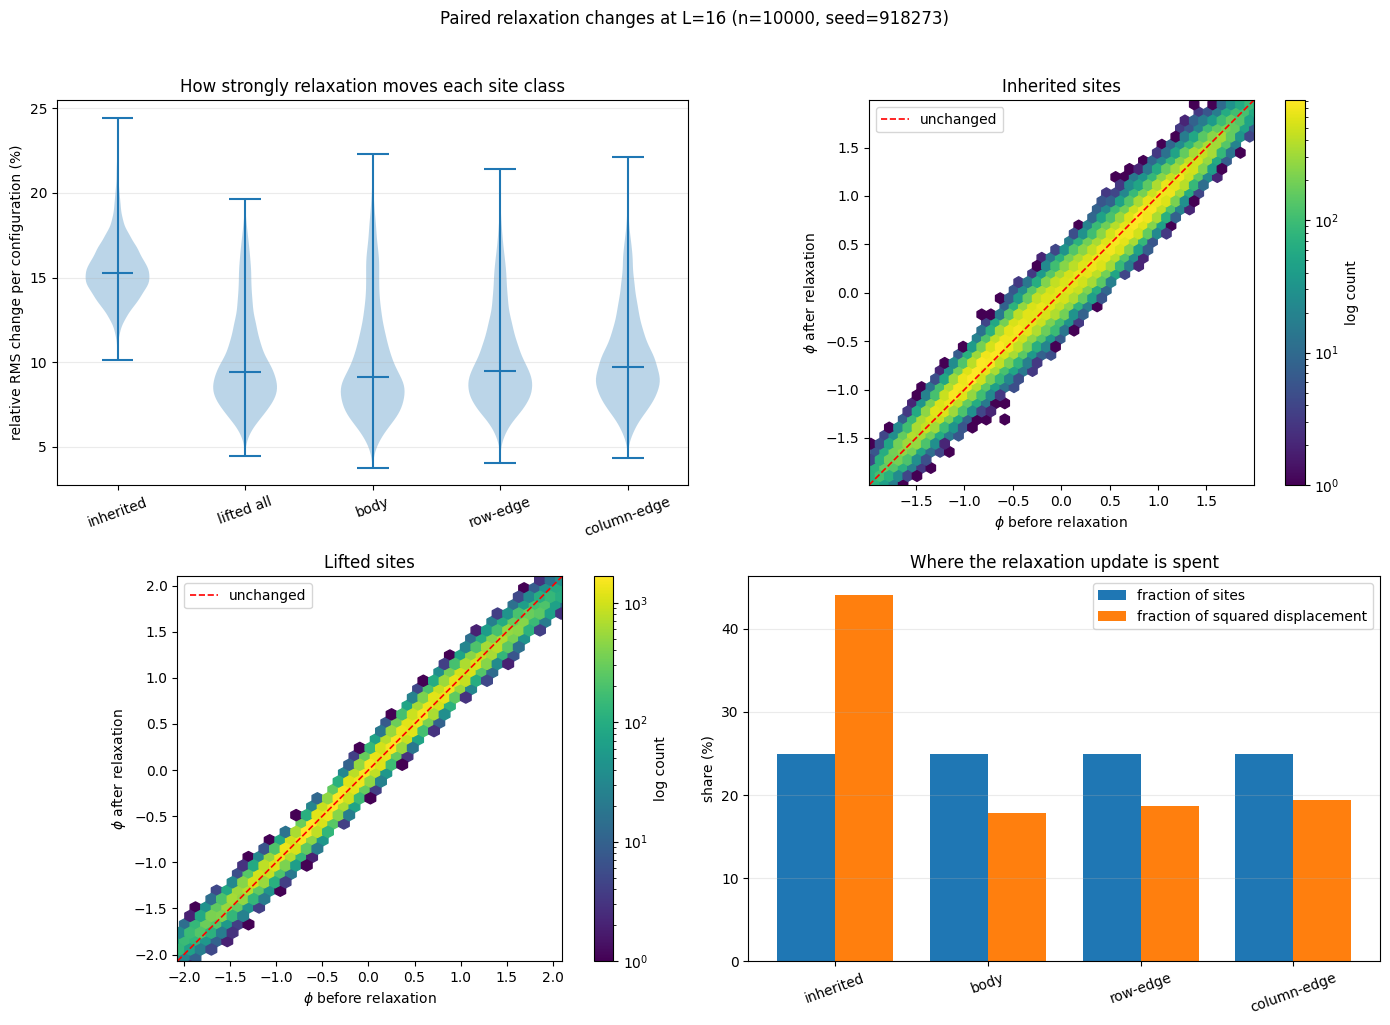

In [39]:
def _relaxation_site_group_values(x: torch.Tensor) -> Dict[str, torch.Tensor]:
    """Flatten the four parity sublattices, plus all lifted sites together."""
    if x.ndim != 4 or x.shape[1] != 1 or x.shape[-1] != x.shape[-2]:
        raise ValueError(f"Expected [B,1,L,L] scalar fields, got {tuple(x.shape)}.")
    inherited = x[:, :, 0::2, 0::2].flatten(1)
    body = x[:, :, 1::2, 1::2].flatten(1)
    row_edge = x[:, :, 1::2, 0::2].flatten(1)
    column_edge = x[:, :, 0::2, 1::2].flatten(1)
    return {
        "inherited": inherited,
        "lifted_all": torch.cat([body, row_edge, column_edge], dim=1),
        "body": body,
        "row_edge": row_edge,
        "column_edge": column_edge,
    }

def _resolve_relaxation_layer_index(
    training_result: Dict[str, object], layer_idx: Optional[int]
) -> int:
    layers = list(training_result.get("layers", []))
    if layer_idx is None:
        candidates = [i for i, rec in enumerate(layers) if rec.get("relaxation") is not None]
        if not candidates:
            raise ValueError("This checkpoint contains no relaxation block.")
        return candidates[-1]
    resolved = int(layer_idx)
    if resolved < 0:
        resolved += len(layers)
    if resolved < 0 or resolved >= len(layers):
        raise IndexError(f"Relaxation layer index out of range: {layer_idx}.")
    if layers[resolved].get("relaxation") is None:
        raise ValueError(f"Layer {resolved} has no relaxation block.")
    return resolved

@torch.no_grad()
def generate_paired_relaxation_samples(
    training_result: Dict[str, object],
    cfg: Phi4Config,
    layer_idx: Optional[int] = None,
    n_samples: int = 10000,
    generation_batch_size: int = 256,
    seed: int = 918273,
) -> Dict[str, Any]:
    """Generate paired fields immediately before and after one stored relaxation block."""
    if int(n_samples) <= 0 or int(generation_batch_size) <= 0:
        raise ValueError("n_samples and generation_batch_size must be positive.")
    if str(training_result.get("paradigm")) != "rkl_cnf":
        raise NotImplementedError("Stored RG relaxation is currently available only for rkl_cnf.")
    resolved_idx = _resolve_relaxation_layer_index(training_result, layer_idx)
    layers = list(training_result["layers"])
    target = layers[resolved_idx]
    mode = str(training_result.get("mode", "residual"))

    torch.manual_seed(int(seed))
    np.random.seed(int(seed))
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(int(seed))

    before_chunks: List[torch.Tensor] = []
    after_chunks: List[torch.Tensor] = []
    completed = 0
    while completed < int(n_samples):
        batch = min(int(generation_batch_size), int(n_samples) - completed)
        x = sample_parent_from_base(training_result["base_model"], cfg, batch_size=batch)
        for rec in layers[:resolved_idx]:
            x = sample_residual_layer_for_paradigm(
                rec["model"], x, cfg, paradigm="rkl_cnf", mode=mode
            )
            if rec.get("relaxation") is not None:
                x = sample_rg_relaxation_cnf(rec["relaxation"], x)
        before = sample_residual_layer_for_paradigm(
            target["model"], x, cfg, paradigm="rkl_cnf", mode=mode
        )
        after = sample_rg_relaxation_cnf(target["relaxation"], before)
        before_chunks.append(before.detach().cpu())
        after_chunks.append(after.detach().cpu())
        completed += batch

    return {
        "layer_idx": resolved_idx,
        "L": int(target["L_fine"]),
        "seed": int(seed),
        "before": torch.cat(before_chunks, dim=0),
        "after": torch.cat(after_chunks, dim=0),
    }

def analyze_paired_relaxation_changes(paired: Dict[str, Any]) -> Dict[str, Any]:
    """Compute per-configuration percentage changes and displacement shares."""
    before = paired["before"].float()
    after = paired["after"].float()
    if before.shape != after.shape:
        raise ValueError(f"Paired sample shapes differ: {before.shape} versus {after.shape}.")
    before_groups = _relaxation_site_group_values(before)
    after_groups = _relaxation_site_group_values(after)
    eps = torch.finfo(before.dtype).eps
    summaries: Dict[str, Dict[str, float]] = {}
    relative_rms_pct: Dict[str, torch.Tensor] = {}

    for name, before_values in before_groups.items():
        after_values = after_groups[name]
        delta = after_values - before_values
        per_config_pct = 100.0 * delta.square().mean(dim=1).sqrt() / (
            before_values.square().mean(dim=1).sqrt() + eps
        )
        relative_rms_pct[name] = per_config_pct
        b_flat = before_values.flatten()
        a_flat = after_values.flatten()
        b_centered = b_flat - b_flat.mean()
        a_centered = a_flat - a_flat.mean()
        correlation = (b_centered * a_centered).mean() / (
            b_centered.square().mean().sqrt() * a_centered.square().mean().sqrt() + eps
        )
        quantiles = torch.quantile(per_config_pct, torch.tensor([0.05, 0.5, 0.95]))
        summaries[name] = {
            "sites_per_configuration": int(before_values.shape[1]),
            "relative_rms_change_pct": float(
                100.0 * delta.square().mean().sqrt() / (before_values.square().mean().sqrt() + eps)
            ),
            "per_configuration_pct_mean": float(per_config_pct.mean()),
            "per_configuration_pct_p05": float(quantiles[0]),
            "per_configuration_pct_median": float(quantiles[1]),
            "per_configuration_pct_p95": float(quantiles[2]),
            "rms_displacement": float(delta.square().mean().sqrt()),
            "before_rms": float(before_values.square().mean().sqrt()),
            "before_after_correlation": float(correlation),
            "sign_flip_pct": float(100.0 * ((before_values * after_values) < 0).float().mean()),
        }

    exclusive = ["inherited", "body", "row_edge", "column_edge"]
    delta_sums = {
        name: float((after_groups[name] - before_groups[name]).square().sum())
        for name in exclusive
    }
    total_delta = sum(delta_sums.values())
    site_counts = {name: int(before_groups[name].shape[1]) for name in exclusive}
    total_sites = sum(site_counts.values())
    displacement_share_pct = {
        name: 100.0 * value / max(total_delta, float(eps))
        for name, value in delta_sums.items()
    }
    site_share_pct = {name: 100.0 * count / total_sites for name, count in site_counts.items()}
    old_vs_lifted_displacement_share_pct = {
        "inherited": displacement_share_pct["inherited"],
        "lifted_all": 100.0 - displacement_share_pct["inherited"],
    }
    old_vs_lifted_site_share_pct = {"inherited": 25.0, "lifted_all": 75.0}

    result = dict(paired)
    result.update({
        "summaries": summaries,
        "relative_rms_pct": relative_rms_pct,
        "displacement_share_pct": displacement_share_pct,
        "site_share_pct": site_share_pct,
        "old_vs_lifted_displacement_share_pct": old_vs_lifted_displacement_share_pct,
        "old_vs_lifted_site_share_pct": old_vs_lifted_site_share_pct,
    })
    return result

def print_relaxation_change_summary(analysis: Dict[str, Any]) -> None:
    print({
        "relaxation_change_analysis": True,
        "layer_idx": analysis["layer_idx"],
        "L": analysis["L"],
        "n_paired_samples": int(analysis["before"].shape[0]),
        "seed": analysis["seed"],
    })
    for name in ["inherited", "lifted_all", "body", "row_edge", "column_edge"]:
        print({"site_group": name, **analysis["summaries"][name]})
    print({"old_vs_lifted_squared_displacement_share_pct": analysis["old_vs_lifted_displacement_share_pct"]})
    print({"old_vs_lifted_site_count_share_pct": analysis["old_vs_lifted_site_share_pct"]})
    print({"squared_displacement_share_pct": analysis["displacement_share_pct"]})
    print({"site_count_share_pct": analysis["site_share_pct"]})

def plot_relaxation_change_diagnostics(
    analysis: Dict[str, Any], max_hexbin_points: int = 100000
):
    """Violin, paired-density, and displacement-share views of relaxation."""
    before_groups = _relaxation_site_group_values(analysis["before"].float())
    after_groups = _relaxation_site_group_values(analysis["after"].float())
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))

    violin_names = ["inherited", "lifted_all", "body", "row_edge", "column_edge"]
    violin_labels = ["inherited", "lifted all", "body", "row-edge", "column-edge"]
    violin_data = [analysis["relative_rms_pct"][name].numpy() for name in violin_names]
    axes[0, 0].violinplot(violin_data, showmedians=True, showextrema=True)
    axes[0, 0].set_xticks(range(1, len(violin_labels) + 1), violin_labels, rotation=20)
    axes[0, 0].set_ylabel("relative RMS change per configuration (%)")
    axes[0, 0].set_title("How strongly relaxation moves each site class")
    axes[0, 0].grid(True, axis="y", alpha=0.25)

    rng = np.random.default_rng(int(analysis["seed"]) + 1)
    for ax, name, title in [
        (axes[0, 1], "inherited", "Inherited sites"),
        (axes[1, 0], "lifted_all", "Lifted sites"),
    ]:
        b = before_groups[name].flatten().numpy()
        a = after_groups[name].flatten().numpy()
        if b.size > int(max_hexbin_points):
            keep = rng.choice(b.size, size=int(max_hexbin_points), replace=False)
            b, a = b[keep], a[keep]
        limits = np.quantile(np.concatenate([b, a]), [0.005, 0.995])
        if not np.isfinite(limits).all() or limits[0] >= limits[1]:
            limits = np.array([min(b.min(), a.min()), max(b.max(), a.max())])
        density = ax.hexbin(b, a, gridsize=60, bins="log", mincnt=1, cmap="viridis")
        ax.plot(limits, limits, "r--", linewidth=1.2, label="unchanged")
        ax.set_xlim(limits)
        ax.set_ylim(limits)
        ax.set_aspect("equal", adjustable="box")
        ax.set_xlabel(r"$\phi$ before relaxation")
        ax.set_ylabel(r"$\phi$ after relaxation")
        ax.set_title(title)
        ax.legend(loc="upper left")
        fig.colorbar(density, ax=ax, label="log count")

    exclusive = ["inherited", "body", "row_edge", "column_edge"]
    labels = ["inherited", "body", "row-edge", "column-edge"]
    positions = np.arange(len(exclusive))
    width = 0.38
    axes[1, 1].bar(
        positions - width / 2,
        [analysis["site_share_pct"][name] for name in exclusive],
        width,
        label="fraction of sites",
    )
    axes[1, 1].bar(
        positions + width / 2,
        [analysis["displacement_share_pct"][name] for name in exclusive],
        width,
        label="fraction of squared displacement",
    )
    axes[1, 1].set_xticks(positions, labels, rotation=20)
    axes[1, 1].set_ylabel("share (%)")
    axes[1, 1].set_title("Where the relaxation update is spent")
    axes[1, 1].legend()
    axes[1, 1].grid(True, axis="y", alpha=0.25)

    fig.suptitle(
        f"Paired relaxation changes at L={analysis['L']} "
        f"(n={analysis['before'].shape[0]}, seed={analysis['seed']})",
        y=1.02,
    )
    fig.tight_layout()
    return fig, axes

# Set layer index to None to analyze the finest stored relaxation block.
RUN_RELAXATION_CHANGE_DIAGNOSTIC = True
RELAXATION_DIAGNOSTIC_LAYER_INDEX = None
RELAXATION_DIAGNOSTIC_N_SAMPLES = int(globals().get("VALIDATION_BATCH_SIZE", 10000))
RELAXATION_DIAGNOSTIC_GENERATION_BATCH_SIZE = 256
RELAXATION_DIAGNOSTIC_SEED = 918273

if RUN_RELAXATION_CHANGE_DIAGNOSTIC:
    relaxation_indices = [
        i for i, rec in enumerate(training_result.get("layers", []))
        if rec.get("relaxation") is not None
    ]
    if not relaxation_indices:
        relaxation_change_analysis = None
        print({"relaxation_change_diagnostic": "skipped", "reason": "checkpoint has no relaxation block"})
    else:
        paired_relaxation_samples = generate_paired_relaxation_samples(
            training_result,
            cfg,
            layer_idx=RELAXATION_DIAGNOSTIC_LAYER_INDEX,
            n_samples=RELAXATION_DIAGNOSTIC_N_SAMPLES,
            generation_batch_size=RELAXATION_DIAGNOSTIC_GENERATION_BATCH_SIZE,
            seed=RELAXATION_DIAGNOSTIC_SEED,
        )
        relaxation_change_analysis = analyze_paired_relaxation_changes(paired_relaxation_samples)
        print_relaxation_change_summary(relaxation_change_analysis)
        relaxation_change_figure, relaxation_change_axes = plot_relaxation_change_diagnostics(
            relaxation_change_analysis
        )
        plt.show()
